Cell 1 — Setup

Imports

Global settings: RANDOM_STATE, test size, CV folds

In [1]:
# Cell 1 — Setup (imports + global settings)

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

# Global settings (keep fixed for reproducibility)
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

# Cross-validation splitter (stratified keeps class ratio similar in each fold)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print("Setup complete.")
print("RANDOM_STATE =", RANDOM_STATE, "| TEST_SIZE =", TEST_SIZE, "| CV_FOLDS =", CV_FOLDS)


Setup complete.
RANDOM_STATE = 42 | TEST_SIZE = 0.2 | CV_FOLDS = 5


Cell 2 — Load Dataset (PIMA)

Read CSV

Show shape, column names, first 5 rows

In [2]:
# Cell 2 — Load Dataset (PIMA)

# Path to your uploaded file (update if your file is elsewhere)
pima_path = r"C:\Users\HP\PhD Python\PIMA\data\RAW\PIMA diabetes.csv"   # if the notebook is in the same folder as the CSV
# pima_path = r"/mnt/data/PIMA diabetes.csv"  # (use this if you're running in this sandbox)

df = pd.read_csv(pima_path)

print("Shape (rows, cols):", df.shape)
print("\nColumn names:")
print(list(df.columns))

print("\nFirst 5 rows:")
display(df.head())


Shape (rows, cols): (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Cell 3 — Data Quality Report (PIMA)

NaN count per column

Zero count per column (show only key columns)

Class distribution (Outcome 0/1)

In [3]:
# Cell 3 — Data Quality Report (PIMA)

# 1) NaN count per column
nan_counts = df.isna().sum()
print("NaN count per column:")
print(nan_counts)

# 2) Zero count per column (key columns only)
key_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "Pregnancies", "Outcome"]
missing_cols = [c for c in key_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"These expected columns are missing in your CSV: {missing_cols}")

zero_counts = (df[key_cols] == 0).sum()
zero_percent = ((df[key_cols] == 0).mean() * 100).round(2)

print("\nZero count (key columns):")
print(pd.DataFrame({"zero_count": zero_counts, "zero_%": zero_percent}))

# 3) Class distribution (Outcome 0/1)
class_counts = df["Outcome"].value_counts().sort_index()
class_percent = (df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(2)

print("\nClass distribution (Outcome):")
print(pd.DataFrame({"count": class_counts, "%": class_percent}))


NaN count per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero count (key columns):
               zero_count  zero_%
Glucose                 5    0.65
BloodPressure          35    4.56
SkinThickness         227   29.56
Insulin               374   48.70
BMI                    11    1.43
Pregnancies           111   14.45
Outcome               500   65.10

Class distribution (Outcome):
         count     %
Outcome             
0          500  65.1
1          268  34.9


Cell 4 — Cleaning Rule (PIMA): 0 → NaN for selected columns

Apply only to: Glucose, BloodPressure, SkinThickness, Insulin, BMI

Re-check NaNs after conversion

In [4]:
# Cell 4 — Cleaning Rule (PIMA): 0 → NaN for selected columns + re-check NaNs

cols_zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Safety check: ensure all columns exist
missing = [c for c in cols_zero_as_missing if c not in df.columns]
if missing:
    raise ValueError(f"These columns are missing in your dataset: {missing}")

# Replace 0 with NaN only in the selected columns
df_clean = df.copy()
df_clean[cols_zero_as_missing] = df_clean[cols_zero_as_missing].replace(0, np.nan)

# Re-check NaN counts (only show these columns + total)
nan_after = df_clean.isna().sum()
print("NaN count AFTER 0→NaN conversion (selected columns):")
print(nan_after[cols_zero_as_missing])

print("\nTotal NaNs in dataset after conversion:", int(nan_after.sum()))


NaN count AFTER 0→NaN conversion (selected columns):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Total NaNs in dataset after conversion: 652


Cell 5 — Split (PIMA)

X, y separation

Train/test split with random_state

Print train/test shapes and class distribution

# Cell 5 — Split (PIMA): X/y + stratified train/test split + checks

# Separate features and target

In [5]:

X = df_clean.drop(columns=["Outcome"])
y = df_clean["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

# Train/test split (stratified keeps class balance similar)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTrain/Test shapes:")
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

# Class distribution helper
def class_dist(series, name):
    counts = series.value_counts().sort_index()
    perc = (series.value_counts(normalize=True).sort_index() * 100).round(2)
    out = pd.DataFrame({"count": counts, "%": perc})
    print(f"\nClass distribution ({name}):")
    print(out)

class_dist(y, "Full dataset (y)")
class_dist(y_train, "Train (y_train)")
class_dist(y_test, "Test (y_test)")


X shape: (768, 8)
y shape: (768,)

Train/Test shapes:
X_train: (614, 8) | y_train: (614,)
X_test : (154, 8) | y_test : (154,)

Class distribution (Full dataset (y)):
         count     %
Outcome             
0          500  65.1
1          268  34.9

Class distribution (Train (y_train)):
         count      %
Outcome              
0          400  65.15
1          214  34.85

Class distribution (Test (y_test)):
         count      %
Outcome              
0          100  64.94
1           54  35.06


Cell 6 — Baseline Model (PIMA): Logistic Regression Pipeline

Pipeline: Imputer(median) → Scaler → LR

Fit on train

Predict on test

Metrics + confusion matrix + ROC-AUC

# Cell 6 — Baseline Model (PIMA): Logistic Regression Pipeline + evaluation

# Pipeline: Median Imputer -> StandardScaler -> Logistic Regression

=== Logistic Regression (Baseline) — PIMA ===
Accuracy : 0.7078
F1-score : 0.5455
ROC-AUC  : 0.813

Confusion Matrix (rows=true, cols=pred):
[[82 18]
 [27 27]]

Classification Report:
              precision    recall  f1-score   support

           0     0.7523    0.8200    0.7847       100
           1     0.6000    0.5000    0.5455        54

    accuracy                         0.7078       154
   macro avg     0.6761    0.6600    0.6651       154
weighted avg     0.6989    0.7078    0.7008       154



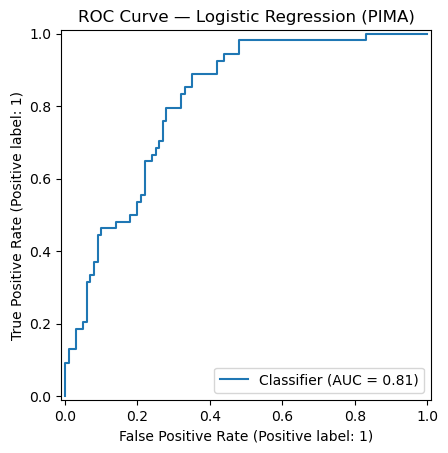

In [6]:
lr_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# Fit on train
lr_pipe.fit(X_train, y_train)

# Predict on test
y_pred = lr_pipe.predict(X_test)
y_proba = lr_pipe.predict_proba(X_test)[:, 1]  # probability of class 1

# Metrics
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

cm = confusion_matrix(y_test, y_pred)

print("=== Logistic Regression (Baseline) — PIMA ===")
print("Accuracy :", round(acc, 4))
print("F1-score :", round(f1, 4))
print("ROC-AUC  :", round(auc, 4))

print("\nConfusion Matrix (rows=true, cols=pred):")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

# Optional: ROC Curve plot
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve — Logistic Regression (PIMA)")
plt.show()


Cell 7 — Primary Model (PIMA): Random Forest Pipeline

Pipeline: Imputer(median) → RF

Fit on train

Predict on test

Metrics + confusion matrix + ROC-AUC

=== Random Forest (Primary) — PIMA ===
Accuracy : 0.7403
F1-score : 0.6
ROC-AUC  : 0.8169

Confusion Matrix (rows=true, cols=pred):
[[84 16]
 [24 30]]

Classification Report:
              precision    recall  f1-score   support

           0     0.7778    0.8400    0.8077       100
           1     0.6522    0.5556    0.6000        54

    accuracy                         0.7403       154
   macro avg     0.7150    0.6978    0.7038       154
weighted avg     0.7337    0.7403    0.7349       154



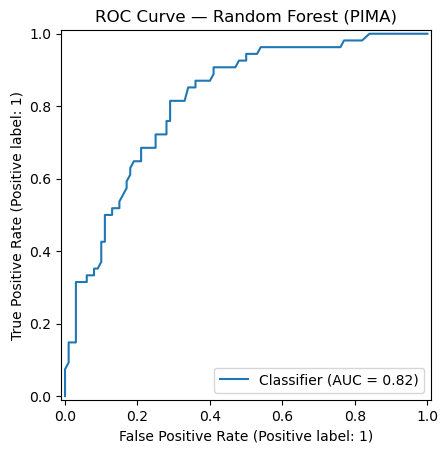

In [7]:
# Cell 7 — Primary Model (PIMA): Random Forest Pipeline + evaluation

rf_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

# Fit on train
rf_pipe.fit(X_train, y_train)

# Predict on test
y_pred_rf = rf_pipe.predict(X_test)
y_proba_rf = rf_pipe.predict_proba(X_test)[:, 1]

# Metrics
acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
auc_rf = roc_auc_score(y_test, y_proba_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("=== Random Forest (Primary) — PIMA ===")
print("Accuracy :", round(acc_rf, 4))
print("F1-score :", round(f1_rf, 4))
print("ROC-AUC  :", round(auc_rf, 4))

print("\nConfusion Matrix (rows=true, cols=pred):")
print(cm_rf)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, digits=4))

# Optional: ROC Curve plot
RocCurveDisplay.from_predictions(y_test, y_proba_rf)
plt.title("ROC Curve — Random Forest (PIMA)")
plt.show()


Cell 8 — Results Summary Table (PIMA)

One small table: LR vs RF (Acc, F1, ROC-AUC)

In [8]:
# Cell 8 — Results Summary Table (PIMA): LR vs RF

results_pima = pd.DataFrame({
    "Dataset": ["PIMA", "PIMA"],
    "Model": ["Logistic Regression (Baseline)", "Random Forest (Primary)"],
    "Accuracy": [acc, acc_rf],
    "F1": [f1, f1_rf],
    "ROC_AUC": [auc, auc_rf]
})

# Optional: round for neat display
results_pima_round = results_pima.copy()
results_pima_round[["Accuracy", "F1", "ROC_AUC"]] = results_pima_round[["Accuracy", "F1", "ROC_AUC"]].round(4)

display(results_pima_round)


,Dataset,Model,Accuracy,F1,ROC_AUC
0,PIMA,Logistic Regression (Baseline),0.7078,0.5455,0.8130
1,PIMA,Random Forest (Primary),0.7403,0.6000,0.8169


Cell 9 — Load UCI dataset

read CSV, shape, columns, head()

In [3]:
# Cell 9 — Load UCI Early-Stage Diabetes dataset

# Option 1: if the CSV is in the SAME folder as your notebook
uci_path = r"C:\Users\HP\PhD Python\UCI\data\RAW\diabetes_data_upload.csv"

# Option 2: use full Windows path (edit as needed)
# uci_path = r"C:\Users\HP\PhD Python\UCI\diabetes_data_upload.csv"

uci_df = pd.read_csv(uci_path)

print("UCI Shape (rows, cols):", uci_df.shape)

print("\nUCI Column names:")
print(list(uci_df.columns))

print("\nFirst 5 rows:")
display(uci_df.head())


UCI Shape (rows, cols): (520, 17)

UCI Column names:
['Age', 'Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity', 'class']

First 5 rows:


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


Cell 10 — Data quality report (UCI)

NaN count per column

class distribution (class)

list categorical vs numeric columns

In [10]:
# Cell 10 — Data Quality Report (UCI)

# 1) NaN count per column
nan_counts_uci = uci_df.isna().sum()
print("NaN count per column (UCI):")
print(nan_counts_uci)

# 2) Class distribution (target = 'class')
# (Keep it general: supports 'Positive/Negative' or '1/0' etc.)
class_counts = uci_df["class"].value_counts(dropna=False)
class_percent = (uci_df["class"].value_counts(normalize=True, dropna=False) * 100).round(2)

print("\nClass distribution (UCI - class):")
print(pd.DataFrame({"count": class_counts, "%": class_percent}))

# 3) List numeric vs categorical columns
numeric_cols = uci_df.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in uci_df.columns if c not in numeric_cols and c != "class"]

print("\nNumeric columns:", numeric_cols)
print("Categorical columns (features):", categorical_cols)

# Optional: show unique values for a few categorical columns (sanity check)
print("\nSample unique values (sanity check):")
for c in ["Gender", "Polyuria", "Polydipsia", "Obesity"]:
    if c in uci_df.columns:
        print(f"{c}: {sorted(uci_df[c].dropna().unique().tolist())}")


NaN count per column (UCI):
Age                   0
Gender                0
Polyuria              0
Polydipsia            0
sudden weight loss    0
weakness              0
Polyphagia            0
Genital thrush        0
visual blurring       0
Itching               0
Irritability          0
delayed healing       0
partial paresis       0
muscle stiffness      0
Alopecia              0
Obesity               0
class                 0
dtype: int64

Class distribution (UCI - class):
          count      %
class                 
Positive    320  61.54
Negative    200  38.46

Numeric columns: ['Age']
Categorical columns (features): ['Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity']

Sample unique values (sanity check):
Gender: ['Female', 'Male']
Polyuria: ['No', 'Yes']
Polydipsia: ['No', 'Yes']
Obesity: ['No', 'Yes'

Cell 11 — Split (UCI)

X/y separation (y = class)

train/test split with random_state + stratify

print shapes + class distribution in train/test

In [11]:
# Cell 11 — Split (UCI): X/y + stratified train/test split + checks

# Separate features and target
X_uci = uci_df.drop(columns=["class"])
y_uci = uci_df["class"]

print("X_uci shape:", X_uci.shape)
print("y_uci shape:", y_uci.shape)

# Train/test split (stratified)
X_uci_train, X_uci_test, y_uci_train, y_uci_test = train_test_split(
    X_uci, y_uci,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_uci
)

print("\nTrain/Test shapes:")
print("X_uci_train:", X_uci_train.shape, "| y_uci_train:", y_uci_train.shape)
print("X_uci_test :", X_uci_test.shape,  "| y_uci_test :", y_uci_test.shape)

# Class distribution helper
def class_dist(series, name):
    counts = series.value_counts()
    perc = (series.value_counts(normalize=True) * 100).round(2)
    out = pd.DataFrame({"count": counts, "%": perc})
    print(f"\nClass distribution ({name}):")
    print(out)

class_dist(y_uci, "Full dataset (y_uci)")
class_dist(y_uci_train, "Train (y_uci_train)")
class_dist(y_uci_test, "Test (y_uci_test)")


X_uci shape: (520, 16)
y_uci shape: (520,)

Train/Test shapes:
X_uci_train: (416, 16) | y_uci_train: (416,)
X_uci_test : (104, 16) | y_uci_test : (104,)

Class distribution (Full dataset (y_uci)):
          count      %
class                 
Positive    320  61.54
Negative    200  38.46

Class distribution (Train (y_uci_train)):
          count      %
class                 
Positive    256  61.54
Negative    160  38.46

Class distribution (Test (y_uci_test)):
          count      %
class                 
Positive     64  61.54
Negative     40  38.46


Cell 12 — Preprocessing for UCI (categorical handling)

define categorical columns = all except Age (and except class)

ColumnTransformer with OneHotEncoder (+ handle_unknown)

(Optionally) imputer for missing categories if any

In [12]:
# Cell 12 — Preprocessing for UCI (categorical handling)

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Define feature columns
numeric_features = ["Age"]  # only numeric column in this dataset
categorical_features = [c for c in X_uci.columns if c not in numeric_features]

print("Numeric features:", numeric_features)
print("Categorical features (count):", len(categorical_features))
print(categorical_features)

# Preprocessing:
# - Numeric: median imputation (safe) (scaling can be added later for LR if desired)
# - Categorical: most_frequent imputation + one-hot encoding
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_uci = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("\nUCI preprocessor is ready.")


Numeric features: ['Age']
Categorical features (count): 15
['Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity']

UCI preprocessor is ready.


Cell 13 — Baseline model (UCI): LR pipeline

preprocessor → (optional scaler for numeric) → LR

metrics + confusion matrix + ROC-AUC

=== Logistic Regression (Baseline) — UCI Early-Stage ===
Accuracy : 0.9423
F1-score : 0.9516
ROC-AUC  : 0.9906

Confusion Matrix (rows=true, cols=pred) [Negative, Positive]:
[[39  1]
 [ 5 59]]

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8864    0.9750    0.9286        40
    Positive     0.9833    0.9219    0.9516        64

    accuracy                         0.9423       104
   macro avg     0.9348    0.9484    0.9401       104
weighted avg     0.9460    0.9423    0.9428       104



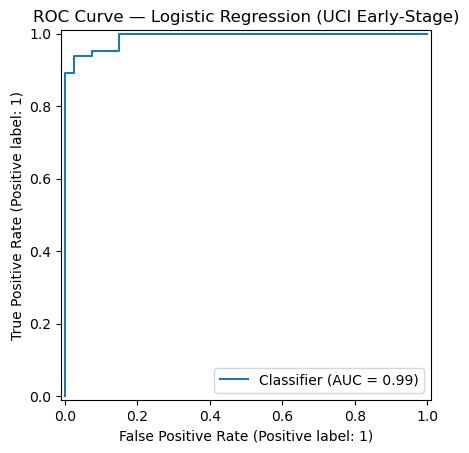

In [13]:
# Cell 13 — Baseline model (UCI): Logistic Regression pipeline + evaluation

# Note: Scaling is not essential here because Age is the only numeric feature,
# and after one-hot encoding, most features are 0/1. So we keep it simple.

uci_lr_pipe = Pipeline(steps=[
    ("preprocess", preprocessor_uci),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

# Fit on train
uci_lr_pipe.fit(X_uci_train, y_uci_train)

# Predict on test
y_uci_pred = uci_lr_pipe.predict(X_uci_test)
y_uci_proba = uci_lr_pipe.predict_proba(X_uci_test)[:, 1]  # probability of Positive class

# Important: ensure ROC-AUC uses the correct "positive" label
# scikit-learn orders classes alphabetically: ['Negative','Positive']
# So [:,1] corresponds to 'Positive' in this dataset.
acc_uci_lr = accuracy_score(y_uci_test, y_uci_pred)
f1_uci_lr = f1_score(y_uci_test, y_uci_pred, pos_label="Positive")
auc_uci_lr = roc_auc_score((y_uci_test == "Positive").astype(int), y_uci_proba)

cm_uci_lr = confusion_matrix(y_uci_test, y_uci_pred, labels=["Negative", "Positive"])

print("=== Logistic Regression (Baseline) — UCI Early-Stage ===")
print("Accuracy :", round(acc_uci_lr, 4))
print("F1-score :", round(f1_uci_lr, 4))
print("ROC-AUC  :", round(auc_uci_lr, 4))

print("\nConfusion Matrix (rows=true, cols=pred) [Negative, Positive]:")
print(cm_uci_lr)

print("\nClassification Report:")
print(classification_report(y_uci_test, y_uci_pred, digits=4))

# Optional: ROC Curve plot
RocCurveDisplay.from_predictions((y_uci_test == "Positive").astype(int), y_uci_proba)
plt.title("ROC Curve — Logistic Regression (UCI Early-Stage)")
plt.show()


Cell 14 — Primary model (UCI): RF pipeline

preprocessor → RF

metrics + confusion matrix + ROC-AUC

=== Random Forest (Primary) — UCI Early-Stage ===
Accuracy : 1.0
F1-score : 1.0
ROC-AUC  : 1.0

Confusion Matrix (rows=true, cols=pred) [Negative, Positive]:
[[40  0]
 [ 0 64]]

Classification Report:
              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000        40
    Positive     1.0000    1.0000    1.0000        64

    accuracy                         1.0000       104
   macro avg     1.0000    1.0000    1.0000       104
weighted avg     1.0000    1.0000    1.0000       104



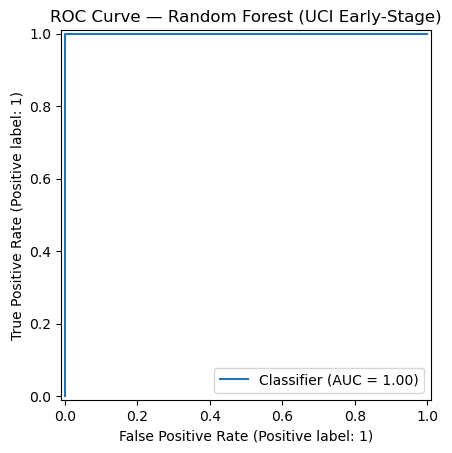

In [14]:
# Cell 14 — Primary model (UCI): Random Forest pipeline + evaluation

uci_rf_pipe = Pipeline(steps=[
    ("preprocess", preprocessor_uci),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

# Fit on train
uci_rf_pipe.fit(X_uci_train, y_uci_train)

# Predict on test
y_uci_pred_rf = uci_rf_pipe.predict(X_uci_test)

# Probabilities for ROC-AUC (need probability of 'Positive')
proba_rf_all = uci_rf_pipe.predict_proba(X_uci_test)
classes_rf = uci_rf_pipe.named_steps["model"].classes_
pos_index = list(classes_rf).index("Positive")
y_uci_proba_rf = proba_rf_all[:, pos_index]

# Metrics
acc_uci_rf = accuracy_score(y_uci_test, y_uci_pred_rf)
f1_uci_rf = f1_score(y_uci_test, y_uci_pred_rf, pos_label="Positive")
auc_uci_rf = roc_auc_score((y_uci_test == "Positive").astype(int), y_uci_proba_rf)

cm_uci_rf = confusion_matrix(y_uci_test, y_uci_pred_rf, labels=["Negative", "Positive"])

print("=== Random Forest (Primary) — UCI Early-Stage ===")
print("Accuracy :", round(acc_uci_rf, 4))
print("F1-score :", round(f1_uci_rf, 4))
print("ROC-AUC  :", round(auc_uci_rf, 4))

print("\nConfusion Matrix (rows=true, cols=pred) [Negative, Positive]:")
print(cm_uci_rf)

print("\nClassification Report:")
print(classification_report(y_uci_test, y_uci_pred_rf, digits=4))

# Optional: ROC Curve plot
RocCurveDisplay.from_predictions((y_uci_test == "Positive").astype(int), y_uci_proba_rf)
plt.title("ROC Curve — Random Forest (UCI Early-Stage)")
plt.show()


Cell 15 — Results summary table (UCI)

LR vs RF (Acc, F1, ROC-AUC)

In [15]:
# Cell 15 — Results Summary Table (UCI): LR vs RF

results_uci = pd.DataFrame({
    "Dataset": ["UCI Early-Stage", "UCI Early-Stage"],
    "Model": ["Logistic Regression (Baseline)", "Random Forest (Primary)"],
    "Accuracy": [acc_uci_lr, acc_uci_rf],
    "F1": [f1_uci_lr, f1_uci_rf],
    "ROC_AUC": [auc_uci_lr, auc_uci_rf]
})

# Round for neat display
results_uci_round = results_uci.copy()
results_uci_round[["Accuracy", "F1", "ROC_AUC"]] = results_uci_round[["Accuracy", "F1", "ROC_AUC"]].round(4)

display(results_uci_round)


,Dataset,Model,Accuracy,F1,ROC_AUC
0,UCI Early-Stage,Logistic Regression (Baseline),0.9423,0.9516,0.9906
1,UCI Early-Stage,Random Forest (Primary),1.0000,1.0000,1.0000


Cell 16 — Final comparison table (PIMA vs UCI)

In [16]:
# Final Comparison Table — PIMA + UCI (LR vs RF)

final_results = pd.concat([results_pima, results_uci], ignore_index=True)

# Round for neat display
final_results_round = final_results.copy()
final_results_round[["Accuracy", "F1", "ROC_AUC"]] = final_results_round[["Accuracy", "F1", "ROC_AUC"]].round(4)

display(final_results_round)


,Dataset,Model,Accuracy,F1,ROC_AUC
0,PIMA,Logistic Regression (Baseline),0.7078,0.5455,0.8130
1,PIMA,Random Forest (Primary),0.7403,0.6000,0.8169
2,UCI Early-Stage,Logistic Regression (Baseline),0.9423,0.9516,0.9906
3,UCI Early-Stage,Random Forest (Primary),1.0000,1.0000,1.0000


# New Cell (Robustness Check) — UCI: repeat with multiple RANDOM_STATE values
# Goal: show results are not due to a “lucky split”


In [17]:
# New Cell (Robustness Check) — UCI: repeat with multiple RANDOM_STATE values

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# ---- Settings to try ----
seeds_to_try = [10, 64, 128]
test_size = 0.20  # 20% test split (same as earlier)

# ---- Prepare X/y once ----
X_uci_all = uci_df.drop(columns=["class"])
y_uci_all = uci_df["class"]

# ---- Build preprocessor once ----
numeric_features = ["Age"]
categorical_features = [c for c in X_uci_all.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

def get_positive_proba(model_pipe, X_test, pos_label="Positive"):
    proba = model_pipe.predict_proba(X_test)
    classes = model_pipe.named_steps["model"].classes_
    pos_idx = list(classes).index(pos_label)
    return proba[:, pos_idx]

rows = []

for seed in seeds_to_try:
    # Split
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_uci_all, y_uci_all,
        test_size=test_size,
        random_state=seed,
        stratify=y_uci_all
    )

    # LR baseline
    lr_pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=2000, random_state=seed))
    ])
    lr_pipe.fit(X_tr, y_tr)
    y_pred_lr = lr_pipe.predict(X_te)
    y_proba_lr = get_positive_proba(lr_pipe, X_te, "Positive")

    acc_lr = accuracy_score(y_te, y_pred_lr)
    f1_lr = f1_score(y_te, y_pred_lr, pos_label="Positive")
    auc_lr = roc_auc_score((y_te == "Positive").astype(int), y_proba_lr)

    # RF primary
    rf_pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=seed,
            class_weight="balanced"
        ))
    ])
    rf_pipe.fit(X_tr, y_tr)
    y_pred_rf = rf_pipe.predict(X_te)
    y_proba_rf = get_positive_proba(rf_pipe, X_te, "Positive")

    acc_rf = accuracy_score(y_te, y_pred_rf)
    f1_rf = f1_score(y_te, y_pred_rf, pos_label="Positive")
    auc_rf = roc_auc_score((y_te == "Positive").astype(int), y_proba_rf)

    rows.append({
        "seed": seed,
        "LR_Acc": acc_lr, "LR_F1": f1_lr, "LR_AUC": auc_lr,
        "RF_Acc": acc_rf, "RF_F1": f1_rf, "RF_AUC": auc_rf
    })

robust_uci = pd.DataFrame(rows).round(4)
display(robust_uci)


,seed,LR_Acc,LR_F1,LR_AUC,RF_Acc,RF_F1,RF_AUC
0,10,0.9231,0.9375,0.9648,0.9808,0.9844,0.9988
1,64,0.9038,0.9206,0.9473,0.9423,0.9524,0.9961
2,128,0.9038,0.9231,0.9625,0.9712,0.9764,0.9988


# New Cell — UCI 5-fold Cross-Validation (LR vs RF) with leakage-safe pipelines
# Output: mean ± std for Accuracy, F1(Positive), ROC-AUC

In [18]:


import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ---- Prepare X/y ----
X_uci_all = uci_df.drop(columns=["class"])
y_uci_all = uci_df["class"]

# ---- Preprocessor (same as before) ----
numeric_features = ["Age"]
categorical_features = [c for c in X_uci_all.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# ---- Models (pipelines) ----
uci_lr_cv = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

uci_rf_cv = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

# ---- CV setup ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring ----
# F1 is for Positive class; ROC-AUC needs probabilities.
scoring = {
    "acc": "accuracy",
    "f1_pos": "f1_macro"  # placeholder replaced below if needed
}

# Better: use explicit Positive label for F1
# In sklearn, you can use make_scorer, but simplest is:
from sklearn.metrics import make_scorer, f1_score
f1_positive = make_scorer(f1_score, pos_label="Positive")

scoring = {
    "acc": "accuracy",
    "f1_pos": f1_positive,
    "auc": "roc_auc"
}

def summarize_cv(name, cv_dict):
    return {
        "Model": name,
        "Acc_mean": np.mean(cv_dict["test_acc"]),
        "Acc_std":  np.std(cv_dict["test_acc"]),
        "F1_mean":  np.mean(cv_dict["test_f1_pos"]),
        "F1_std":   np.std(cv_dict["test_f1_pos"]),
        "AUC_mean": np.mean(cv_dict["test_auc"]),
        "AUC_std":  np.std(cv_dict["test_auc"]),
    }

# ---- Run CV ----
cv_lr = cross_validate(uci_lr_cv, X_uci_all, y_uci_all, cv=cv5, scoring=scoring)
cv_rf = cross_validate(uci_rf_cv, X_uci_all, y_uci_all, cv=cv5, scoring=scoring)

summary = pd.DataFrame([
    summarize_cv("Logistic Regression (Baseline)", cv_lr),
    summarize_cv("Random Forest (Primary)", cv_rf)
])

# Round for display
for c in ["Acc_mean","Acc_std","F1_mean","F1_std","AUC_mean","AUC_std"]:
    summary[c] = summary[c].round(4)

display(summary)


,Model,Acc_mean,Acc_std,F1_mean,F1_std,AUC_mean,AUC_std
0,Logistic Regression (Baseline),0.9308,0.0112,0.9437,0.0084,0.9766,0.0087
1,Random Forest (Primary),0.9846,0.0144,0.9874,0.0118,0.9988,0.0012


In [19]:
# New Cell — UCI 5-fold CV with Precision and Recall
# Positive class = "Positive"

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, roc_auc_score

# ---- Prepare UCI data ----
# Uses existing uci_df if available; otherwise loads from CSV

try:
    X_uci_all = uci_df.drop(columns=["class"])
    y_uci_all = uci_df["class"]
    print("Using existing uci_df.")
except NameError:
    print("uci_df not found; loading UCI dataset.")
    
    uci_path = "diabetes_data_upload.csv"  # change to full path if needed
    # uci_path = r"C:\Users\HP\PhD Python\PIMA\diabetes_data_upload.csv"
    
    uci_df = pd.read_csv(uci_path)
    X_uci_all = uci_df.drop(columns=["class"])
    y_uci_all = uci_df["class"]

# ---- Define numeric and categorical features ----
numeric_features = ["Age"]
categorical_features = [c for c in X_uci_all.columns if c not in numeric_features]

# ---- Preprocessing ----
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_uci = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# ---- 5-fold stratified CV ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring metrics for Positive class ----
precision_positive = make_scorer(precision_score, pos_label="Positive")
recall_positive = make_scorer(recall_score, pos_label="Positive")
f1_positive = make_scorer(f1_score, pos_label="Positive")

# Custom ROC-AUC scorer for Positive class
def auc_positive(estimator, X, y):
    proba_all = estimator.predict_proba(X)
    classes = estimator.named_steps["model"].classes_
    pos_idx = list(classes).index("Positive")
    y_score = proba_all[:, pos_idx]
    y_true = (y == "Positive").astype(int)
    return roc_auc_score(y_true, y_score)

scoring = {
    "accuracy": "accuracy",
    "precision": precision_positive,
    "recall": recall_positive,
    "f1": f1_positive,
    "roc_auc": auc_positive
}

# ---- LR pipeline ----
uci_lr_cv = Pipeline(steps=[
    ("preprocess", preprocessor_uci),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# ---- RF pipeline ----
uci_rf_cv = Pipeline(steps=[
    ("preprocess", preprocessor_uci),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

# ---- Run CV ----
cv_lr_uci = cross_validate(uci_lr_cv, X_uci_all, y_uci_all, cv=cv5, scoring=scoring)
cv_rf_uci = cross_validate(uci_rf_cv, X_uci_all, y_uci_all, cv=cv5, scoring=scoring)

# ---- Summary function ----
def summarize_cv(name, cv_dict):
    return {
        "Model": name,
        "Accuracy_mean": np.mean(cv_dict["test_accuracy"]),
        "Accuracy_std": np.std(cv_dict["test_accuracy"]),
        "Precision_mean": np.mean(cv_dict["test_precision"]),
        "Precision_std": np.std(cv_dict["test_precision"]),
        "Recall_mean": np.mean(cv_dict["test_recall"]),
        "Recall_std": np.std(cv_dict["test_recall"]),
        "F1_mean": np.mean(cv_dict["test_f1"]),
        "F1_std": np.std(cv_dict["test_f1"]),
        "ROC_AUC_mean": np.mean(cv_dict["test_roc_auc"]),
        "ROC_AUC_std": np.std(cv_dict["test_roc_auc"])
    }

uci_cv_precision_recall = pd.DataFrame([
    summarize_cv("Logistic Regression (Baseline)", cv_lr_uci),
    summarize_cv("Random Forest (Primary)", cv_rf_uci)
])

# ---- Round values ----
numeric_cols = uci_cv_precision_recall.columns.drop("Model")
uci_cv_precision_recall[numeric_cols] = uci_cv_precision_recall[numeric_cols].round(4)

display(uci_cv_precision_recall)

Using existing uci_df.


,Model,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std
0,Logistic Regression (Baseline),0.9308,0.0112,0.9475,0.0248,0.9406,0.0153,0.9437,0.0084,0.9766,0.0087
1,Random Forest (Primary),0.9846,0.0144,0.9876,0.0114,0.9875,0.0182,0.9874,0.0118,0.9988,0.0012


# New Cell — PIMA 5-fold Cross-Validation (LR vs RF) with leakage-safe pipelines
# Output: mean ± std for Accuracy, F1(Outcome=1), ROC-AUC

In [20]:



import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ---- Prepare X/y from your cleaned PIMA dataframe ----
# (df_clean is the PIMA dataframe where 0→NaN conversion was done for selected columns)
X_pima_all = df_clean.drop(columns=["Outcome"])
y_pima_all = df_clean["Outcome"]

# ---- CV setup ----
cv5_pima = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring ----
scoring_pima = {
    "acc": "accuracy",
    "f1": "f1",          # default positive label is 1 (perfect for PIMA)
    "auc": "roc_auc"
}

# ---- Pipelines ----
pima_lr_cv = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

pima_rf_cv = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

def summarize_cv(name, cv_dict):
    return {
        "Model": name,
        "Acc_mean": np.mean(cv_dict["test_acc"]),
        "Acc_std":  np.std(cv_dict["test_acc"]),
        "F1_mean":  np.mean(cv_dict["test_f1"]),
        "F1_std":   np.std(cv_dict["test_f1"]),
        "AUC_mean": np.mean(cv_dict["test_auc"]),
        "AUC_std":  np.std(cv_dict["test_auc"]),
    }

# ---- Run CV ----
cv_lr_pima = cross_validate(pima_lr_cv, X_pima_all, y_pima_all, cv=cv5_pima, scoring=scoring_pima)
cv_rf_pima = cross_validate(pima_rf_cv, X_pima_all, y_pima_all, cv=cv5_pima, scoring=scoring_pima)

pima_cv_summary = pd.DataFrame([
    summarize_cv("Logistic Regression (Baseline)", cv_lr_pima),
    summarize_cv("Random Forest (Primary)", cv_rf_pima)
])

# Round for display
for c in ["Acc_mean","Acc_std","F1_mean","F1_std","AUC_mean","AUC_std"]:
    pima_cv_summary[c] = pima_cv_summary[c].round(4)

display(pima_cv_summary)


,Model,Acc_mean,Acc_std,F1_mean,F1_std,AUC_mean,AUC_std
0,Logistic Regression (Baseline),0.7721,0.0166,0.6358,0.0210,0.8366,0.0203
1,Random Forest (Primary),0.7630,0.0177,0.6345,0.0237,0.8248,0.0186


# New Cell — PIMA 5-fold Cross-Validation (LR vs RF) [SELF-CONTAINED]
# Loads PIMA, applies 0→NaN for selected columns, then CV with leakage-safe pipelines.


In [19]:



import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ---- Load PIMA (edit path if needed) ----
pima_path = r"C:\Users\HP\PhD Python\PIMA\data\RAW\PIMA diabetes.csv"
#pima_path = "PIMA diabetes.csv"  # same folder as notebook
# pima_path = r"C:\Users\HP\PhD Python\PIMA\PIMA diabetes.csv"  # full path if needed
df_pima = pd.read_csv(pima_path)

# ---- Standard PIMA cleaning: 0 → NaN for medically impossible columns ----
cols_zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_pima[cols_zero_as_missing] = df_pima[cols_zero_as_missing].replace(0, np.nan)

# ---- Prepare X/y ----
X_pima_all = df_pima.drop(columns=["Outcome"])
y_pima_all = df_pima["Outcome"]

# ---- CV setup ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring ----
scoring = {
    "acc": "accuracy",
    "f1": "f1",        # positive class is 1 in PIMA
    "auc": "roc_auc"
}

# ---- Pipelines ----
pima_lr_cv = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

pima_rf_cv = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

def summarize(name, cv_dict):
    return {
        "Model": name,
        "Acc_mean": np.mean(cv_dict["test_acc"]),
        "Acc_std":  np.std(cv_dict["test_acc"]),
        "F1_mean":  np.mean(cv_dict["test_f1"]),
        "F1_std":   np.std(cv_dict["test_f1"]),
        "AUC_mean": np.mean(cv_dict["test_auc"]),
        "AUC_std":  np.std(cv_dict["test_auc"]),
    }

# ---- Run CV ----
cv_lr = cross_validate(pima_lr_cv, X_pima_all, y_pima_all, cv=cv5, scoring=scoring)
cv_rf = cross_validate(pima_rf_cv, X_pima_all, y_pima_all, cv=cv5, scoring=scoring)

pima_cv_summary = pd.DataFrame([
    summarize("Logistic Regression (Baseline)", cv_lr),
    summarize("Random Forest (Primary)", cv_rf)
])

# Round for display
cols = ["Acc_mean","Acc_std","F1_mean","F1_std","AUC_mean","AUC_std"]
pima_cv_summary[cols] = pima_cv_summary[cols].round(4)

display(pima_cv_summary)


,Model,Acc_mean,Acc_std,F1_mean,F1_std,AUC_mean,AUC_std
0,Logistic Regression (Baseline),0.7721,0.0166,0.6358,0.0210,0.8366,0.0203
1,Random Forest (Primary),0.7630,0.0177,0.6345,0.0237,0.8248,0.0186


In [21]:
# New Cell — PIMA 5-fold CV with Precision and Recall
# Positive class = Outcome 1 (diabetic)

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ---- Prepare PIMA data ----
# Uses existing df_clean if available; otherwise loads and applies 0→NaN cleaning
try:
    X_pima_all = df_clean.drop(columns=["Outcome"])
    y_pima_all = df_clean["Outcome"]
    print("Using existing df_clean.")
except NameError:
    print("df_clean not found; loading PIMA and applying 0→NaN cleaning rule.")
    
    pima_path = r"C:\Users\HP\PhD Python\PIMA\PIMA diabetes.csv"
    df_pima = pd.read_csv(pima_path)
    
    cols_zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    df_pima[cols_zero_as_missing] = df_pima[cols_zero_as_missing].replace(0, np.nan)
    
    X_pima_all = df_pima.drop(columns=["Outcome"])
    y_pima_all = df_pima["Outcome"]

# ---- 5-fold stratified CV ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring metrics ----
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",   # for positive class 1 by default
    "recall": "recall",         # for positive class 1 by default
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# ---- LR pipeline ----
pima_lr_cv = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# ---- RF pipeline ----
pima_rf_cv = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

# ---- Run CV ----
cv_lr = cross_validate(pima_lr_cv, X_pima_all, y_pima_all, cv=cv5, scoring=scoring)
cv_rf = cross_validate(pima_rf_cv, X_pima_all, y_pima_all, cv=cv5, scoring=scoring)

# ---- Summary function ----
def summarize_cv(name, cv_dict):
    return {
        "Model": name,
        "Accuracy_mean": np.mean(cv_dict["test_accuracy"]),
        "Accuracy_std": np.std(cv_dict["test_accuracy"]),
        "Precision_mean": np.mean(cv_dict["test_precision"]),
        "Precision_std": np.std(cv_dict["test_precision"]),
        "Recall_mean": np.mean(cv_dict["test_recall"]),
        "Recall_std": np.std(cv_dict["test_recall"]),
        "F1_mean": np.mean(cv_dict["test_f1"]),
        "F1_std": np.std(cv_dict["test_f1"]),
        "ROC_AUC_mean": np.mean(cv_dict["test_roc_auc"]),
        "ROC_AUC_std": np.std(cv_dict["test_roc_auc"])
    }

pima_cv_precision_recall = pd.DataFrame([
    summarize_cv("Logistic Regression (Baseline)", cv_lr),
    summarize_cv("Random Forest (Primary)", cv_rf)
])

# Round values
numeric_cols = pima_cv_precision_recall.columns.drop("Model")
pima_cv_precision_recall[numeric_cols] = pima_cv_precision_recall[numeric_cols].round(4)

display(pima_cv_precision_recall)

Using existing df_clean.


,Model,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std
0,Logistic Regression (Baseline),0.7721,0.0166,0.7261,0.0617,0.5711,0.0474,0.6358,0.0210,0.8366,0.0203
1,Random Forest (Primary),0.7630,0.0177,0.6892,0.0382,0.5896,0.0305,0.6345,0.0237,0.8248,0.0186


In [22]:
import os
print("Current folder:", os.getcwd())
print("Files here:", os.listdir())


Current folder: C:\Users\HP\PhD Python\PIMA
Files here: ['.ipynb_checkpoints', 'data', 'FEATURE IMPORTANCE.ipynb', 'LRPIMA.ipynb', 'OTHER BASELINE MODELS 2.ipynb', 'pidd_rf_permutation_feature_importance.pdf', 'pidd_rf_permutation_feature_importance.png', 'pidd_tuned_precision_recall_curves.png']


# New Cell — PIMA: Small GridSearchCV to tune Random Forest (DSC-friendly)
# Goal: improve RF performance on PIMA using 5-fold CV (leakage-safe pipeline)

In [23]:



import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score

# ---- Load/prepare PIMA (use existing df_clean if available; else do self-contained load) ----
try:
    X_pima_all = df_clean.drop(columns=["Outcome"])
    y_pima_all = df_clean["Outcome"]
    print("Using existing df_clean from notebook.")
except NameError:
    print("df_clean not found; loading PIMA CSV and applying 0→NaN conversion...")
    pima_path = pima_path = r"C:\Users\HP\PhD Python\PIMA\data\RAW\PIMA diabetes.csv"  # change to full path if needed
    df_pima = pd.read_csv(pima_path)
    cols_zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    df_pima[cols_zero_as_missing] = df_pima[cols_zero_as_missing].replace(0, np.nan)
    X_pima_all = df_pima.drop(columns=["Outcome"])
    y_pima_all = df_pima["Outcome"]

# ---- Pipeline: Imputer -> RF ----
rf_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_estimators=300
    ))
])

# ---- Small parameter grid (kept small for speed + defensibility) ----
param_grid = {
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

# ---- CV + scoring (focus on F1 for positive class=1) ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_scorer = make_scorer(f1_score, pos_label=1)

grid = GridSearchCV(
    estimator=rf_pipe,
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=cv5,
    n_jobs=-1,
    verbose=0
)

grid.fit(X_pima_all, y_pima_all)

print("\nBest CV F1 (mean):", round(grid.best_score_, 4))
print("Best parameters:")
print(grid.best_params_)

# Optional: show top 5 configs
results = pd.DataFrame(grid.cv_results_).sort_values("mean_test_score", ascending=False)
top5 = results[["mean_test_score", "std_test_score", "params"]].head(5).copy()
top5["mean_test_score"] = top5["mean_test_score"].round(4)
top5["std_test_score"] = top5["std_test_score"].round(4)

display(top5)


Using existing df_clean from notebook.

Best CV F1 (mean): 0.6981
Best parameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__min_samples_split': 10}


,mean_test_score,std_test_score,params
44,0.6981,0.0276,"{'model__max_depth': 10, 'model__max_features'..."
34,0.6981,0.0255,"{'model__max_depth': 5, 'model__max_features':..."
33,0.6981,0.0255,"{'model__max_depth': 5, 'model__max_features':..."
53,0.6974,0.0258,"{'model__max_depth': 10, 'model__max_features'..."
31,0.6967,0.0300,"{'model__max_depth': 5, 'model__max_features':..."


# New Cell — UCI Data Quality: Unique values + counts (categorical columns)

# Assumes uci_df is already loaded (from Cell 9)


In [24]:
# 1) Missing values (repeat, quick)
print("NaN count per column (UCI):")
print(uci_df.isna().sum())

# 2) Unique values + counts for each categorical feature
print("\nUnique value counts for categorical columns:\n")

numeric_cols = uci_df.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in uci_df.columns if c not in numeric_cols]  # includes 'class'

for col in categorical_cols:
    print(f"--- {col} ---")
    print(uci_df[col].value_counts(dropna=False))
    print()


NaN count per column (UCI):
Age                   0
Gender                0
Polyuria              0
Polydipsia            0
sudden weight loss    0
weakness              0
Polyphagia            0
Genital thrush        0
visual blurring       0
Itching               0
Irritability          0
delayed healing       0
partial paresis       0
muscle stiffness      0
Alopecia              0
Obesity               0
class                 0
dtype: int64

Unique value counts for categorical columns:

--- Gender ---
Gender
Male      328
Female    192
Name: count, dtype: int64

--- Polyuria ---
Polyuria
No     262
Yes    258
Name: count, dtype: int64

--- Polydipsia ---
Polydipsia
No     287
Yes    233
Name: count, dtype: int64

--- sudden weight loss ---
sudden weight loss
No     303
Yes    217
Name: count, dtype: int64

--- weakness ---
weakness
Yes    305
No     215
Name: count, dtype: int64

--- Polyphagia ---
Polyphagia
No     283
Yes    237
Name: count, dtype: int64

--- Genital thrush ---
G

In [7]:
# Output 5 fold stratified cross validation on UCI - checked with ppt - was trying to figure out what 
# this code is for - then from ppt found out that this corresponds to 5 fold stratified CV on UCI
# but still wondering why this code is again here

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score, roc_auc_score

# ---- Prepare X/y ----
X_uci_all = uci_df.drop(columns=["class"])
y_uci_all = uci_df["class"]  # labels: "Negative" / "Positive"

# ---- Preprocessor (same as before) ----
numeric_features = ["Age"]
categorical_features = [c for c in X_uci_all.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# ---- Models (pipelines) ----
uci_lr_cv = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

uci_rf_cv = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

# ---- CV setup ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring ----
# F1 explicitly for Positive class
f1_positive = make_scorer(f1_score, pos_label="Positive")

# ROC-AUC explicitly for Positive class (DSC-safe: no label ambiguity)
def auc_positive(estimator, X, y):
    proba_all = estimator.predict_proba(X)
    classes = estimator.named_steps["model"].classes_
    pos_idx = list(classes).index("Positive")
    y_score = proba_all[:, pos_idx]
    y_true = (y == "Positive").astype(int)
    return roc_auc_score(y_true, y_score)

scoring = {
    "acc": "accuracy",
    "f1_pos": f1_positive,
    "auc": auc_positive
}

def summarize_cv(name, cv_dict):
    return {
        "Model": name,
        "Acc_mean": np.mean(cv_dict["test_acc"]),
        "Acc_std":  np.std(cv_dict["test_acc"]),
        "F1_mean":  np.mean(cv_dict["test_f1_pos"]),
        "F1_std":   np.std(cv_dict["test_f1_pos"]),
        "AUC_mean": np.mean(cv_dict["test_auc"]),
        "AUC_std":  np.std(cv_dict["test_auc"]),
    }

# ---- Run CV ----
cv_lr = cross_validate(uci_lr_cv, X_uci_all, y_uci_all, cv=cv5, scoring=scoring)
cv_rf = cross_validate(uci_rf_cv, X_uci_all, y_uci_all, cv=cv5, scoring=scoring)

summary = pd.DataFrame([
    summarize_cv("Logistic Regression (Baseline)", cv_lr),
    summarize_cv("Random Forest (Primary)", cv_rf)
])

# Round for display
for c in ["Acc_mean","Acc_std","F1_mean","F1_std","AUC_mean","AUC_std"]:
    summary[c] = summary[c].round(4)

display(summary)


,Model,Acc_mean,Acc_std,F1_mean,F1_std,AUC_mean,AUC_std
0,Logistic Regression (Baseline),0.9308,0.0112,0.9437,0.0084,0.9766,0.0087
1,Random Forest (Primary),0.9846,0.0144,0.9874,0.0118,0.9988,0.0012


Loaded uci_df shape: (520, 17)
Columns: ['Age', 'Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity', 'class']
class
Positive    320
Negative    200
Name: count, dtype: int64
=== Random Forest (Primary) — UCI Early-Stage ===
Accuracy : 1.0
F1-score : 1.0
ROC-AUC  : 1.0

Confusion Matrix (rows=true, cols=pred) [Negative, Positive]:
[[40  0]
 [ 0 64]]

Classification Report:
              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000        40
    Positive     1.0000    1.0000    1.0000        64

    accuracy                         1.0000       104
   macro avg     1.0000    1.0000    1.0000       104
weighted avg     1.0000    1.0000    1.0000       104



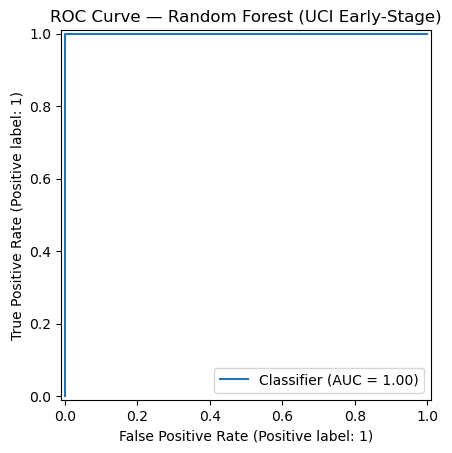

In [26]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

UCI_PATH = r"C:\Users\HP\PhD Python\UCI\data\RAW\diabetes_data_upload.csv"   # e.g., r"D:\Datasets\diabetes_data_upload.csv"
uci_df = pd.read_csv(UCI_PATH)

print("Loaded uci_df shape:", uci_df.shape)
print("Columns:", list(uci_df.columns))
print(uci_df["class"].value_counts())


# -----------------------------
# 1) X/y
# -----------------------------
X_uci = uci_df.drop(columns=["class"])
y_uci = uci_df["class"]  # labels: "Negative" / "Positive"

# -----------------------------
# 2) Split (stratified)
# -----------------------------
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_uci_train, X_uci_test, y_uci_train, y_uci_test = train_test_split(
    X_uci, y_uci,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_uci
)

# -----------------------------
# 3) Preprocessor
# -----------------------------
numeric_features = ["Age"]
categorical_features = [c for c in X_uci.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_uci = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# -----------------------------
# 4) Random Forest pipeline
# -----------------------------
uci_rf_pipe = Pipeline(steps=[
    ("preprocess", preprocessor_uci),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

# Fit on train
uci_rf_pipe.fit(X_uci_train, y_uci_train)

# Predict on test
y_pred = uci_rf_pipe.predict(X_uci_test)

# Probability of "Positive" (DSC-safe: find correct column)
proba_all = uci_rf_pipe.predict_proba(X_uci_test)
classes = uci_rf_pipe.named_steps["model"].classes_
pos_idx = list(classes).index("Positive")
y_proba_pos = proba_all[:, pos_idx]

# -----------------------------
# 5) Metrics
# -----------------------------
acc = accuracy_score(y_uci_test, y_pred)
f1  = f1_score(y_uci_test, y_pred, pos_label="Positive")
auc = roc_auc_score((y_uci_test == "Positive").astype(int), y_proba_pos)

cm = confusion_matrix(y_uci_test, y_pred, labels=["Negative", "Positive"])

print("=== Random Forest (Primary) — UCI Early-Stage ===")
print("Accuracy :", round(acc, 4))
print("F1-score :", round(f1, 4))
print("ROC-AUC  :", round(auc, 4))

print("\nConfusion Matrix (rows=true, cols=pred) [Negative, Positive]:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_uci_test, y_pred, digits=4))

# ROC curve
RocCurveDisplay.from_predictions((y_uci_test == "Positive").astype(int), y_proba_pos)
plt.title("ROC Curve — Random Forest (UCI Early-Stage)")
plt.show()


In [26]:
print("Train accuracy:", rf_pipe.score(X_train, y_train))
print("Test  accuracy:", rf_pipe.score(X_test, y_test))
print("Train size:", X_train.shape[0], "Test size:", X_test.shape[0])


NotFittedError: This SimpleImputer instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [27]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# 1) X/y
X_uci = uci_df.drop(columns=["class"])
y_uci = uci_df["class"]

# 2) Split
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X_uci, y_uci,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_uci
)

# 3) Preprocessor
numeric_features = ["Age"]
categorical_features = [c for c in X_uci.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# 4) RF pipeline
rf_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

# 5) Fit
rf_pipe.fit(X_train, y_train)

# 6) Train/Test accuracy
print("Train accuracy:", rf_pipe.score(X_train, y_train))
print("Test  accuracy:", rf_pipe.score(X_test, y_test))
print("Train size:", X_train.shape[0], "Test size:", X_test.shape[0])

# (Optional) sanity check with confusion matrix on test
y_pred_test = rf_pipe.predict(X_test)
cm = confusion_matrix(y_test, y_pred_test, labels=["Negative", "Positive"])
print("\nTest confusion matrix [Negative, Positive]:\n", cm)
print("Correct:", cm[0,0] + cm[1,1], "Wrong:", cm[0,1] + cm[1,0], "Total:", cm.sum())


Train accuracy: 1.0
Test  accuracy: 1.0
Train size: 416 Test size: 104

Test confusion matrix [Negative, Positive]:
 [[40  0]
 [ 0 64]]
Correct: 104 Wrong: 0 Total: 104


In [28]:
# Stratified CV on UCI

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score, roc_auc_score

# ---- Prepare X/y ----
X_uci_all = uci_df.drop(columns=["class"])
y_uci_all = uci_df["class"]  # "Negative" / "Positive"

# ---- Preprocessor (same as before) ----
numeric_features = ["Age"]
categorical_features = [c for c in X_uci_all.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# ---- Models (pipelines) ----
uci_lr_cv = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

uci_rf_cv = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

# ---- CV setup ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring ----
# F1 explicitly for Positive class
f1_positive = make_scorer(f1_score, pos_label="Positive")

# ROC-AUC explicitly for Positive class (DSC-safe)
def auc_positive(estimator, X, y):
    proba_all = estimator.predict_proba(X)
    classes = estimator.named_steps["model"].classes_
    pos_idx = list(classes).index("Positive")
    y_score = proba_all[:, pos_idx]
    y_true = (y == "Positive").astype(int)
    return roc_auc_score(y_true, y_score)

scoring = {
    "acc": "accuracy",
    "f1_pos": f1_positive,
    "auc": auc_positive
}

def summarize_cv(name, cv_dict):
    return {
        "Model": name,
        "Acc_mean": np.mean(cv_dict["test_acc"]),
        "Acc_std":  np.std(cv_dict["test_acc"]),
        "F1_mean":  np.mean(cv_dict["test_f1_pos"]),
        "F1_std":   np.std(cv_dict["test_f1_pos"]),
        "AUC_mean": np.mean(cv_dict["test_auc"]),
        "AUC_std":  np.std(cv_dict["test_auc"]),
    }

# ---- Run CV ----
cv_lr = cross_validate(uci_lr_cv, X_uci_all, y_uci_all, cv=cv5, scoring=scoring)
cv_rf = cross_validate(uci_rf_cv, X_uci_all, y_uci_all, cv=cv5, scoring=scoring)

summary = pd.DataFrame([
    summarize_cv("Logistic Regression (Baseline)", cv_lr),
    summarize_cv("Random Forest (Primary)", cv_rf)
])

# Round for display
for c in ["Acc_mean","Acc_std","F1_mean","F1_std","AUC_mean","AUC_std"]:
    summary[c] = summary[c].round(4)

display(summary)


,Model,Acc_mean,Acc_std,F1_mean,F1_std,AUC_mean,AUC_std
0,Logistic Regression (Baseline),0.9308,0.0112,0.9437,0.0084,0.9766,0.0087
1,Random Forest (Primary),0.9846,0.0144,0.9874,0.0118,0.9988,0.0012


In [ ]:
# GRIDSEARCH CV ON PIMA

In [29]:
# New Cell — PIMA: GridSearchCV for Random Forest
# Goal: tune RF hyperparameters using 5-fold CV

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score

# ---- Prepare X/y ----
# df_clean should already have 0→NaN conversion applied for:
# Glucose, BloodPressure, SkinThickness, Insulin, BMI

X_pima_all = df_clean.drop(columns=["Outcome"])
y_pima_all = df_clean["Outcome"]

# ---- Pipeline: Median Imputer → Random Forest ----
rf_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

# ---- Parameter grid ----
param_grid = {
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

# ---- 5-fold stratified CV ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring: focus on diabetic class (Outcome = 1) ----
f1_scorer = make_scorer(f1_score, pos_label=1)

# ---- GridSearchCV ----
grid_rf_pima = GridSearchCV(
    estimator=rf_pipe,
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=cv5,
    n_jobs=-1,
    verbose=1
)

# ---- Run grid search ----
grid_rf_pima.fit(X_pima_all, y_pima_all)

print("Best CV F1 score:", round(grid_rf_pima.best_score_, 4))
print("\nBest hyperparameters:")
print(grid_rf_pima.best_params_)

# ---- Show top 5 parameter combinations ----
grid_results = pd.DataFrame(grid_rf_pima.cv_results_)

top5_rf_pima = grid_results[
    ["mean_test_score", "std_test_score", "params"]
].sort_values(by="mean_test_score", ascending=False).head(5)

top5_rf_pima["mean_test_score"] = top5_rf_pima["mean_test_score"].round(4)
top5_rf_pima["std_test_score"] = top5_rf_pima["std_test_score"].round(4)

display(top5_rf_pima)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best CV F1 score: 0.6981

Best hyperparameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__min_samples_split': 10}


,mean_test_score,std_test_score,params
44,0.6981,0.0276,"{'model__max_depth': 10, 'model__max_features'..."
34,0.6981,0.0255,"{'model__max_depth': 5, 'model__max_features':..."
33,0.6981,0.0255,"{'model__max_depth': 5, 'model__max_features':..."
53,0.6974,0.0258,"{'model__max_depth': 10, 'model__max_features'..."
31,0.6967,0.0300,"{'model__max_depth': 5, 'model__max_features':..."


Using existing df_clean.
=== Tuned Random Forest — PIMA Test Set ===
Accuracy : 0.7468
F1-score : 0.6549
MCC       : 0.4566
ROC-AUC  : 0.8202

Confusion Matrix (rows=true, cols=pred):
[[78 22]
 [17 37]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8211    0.7800    0.8000       100
           1     0.6271    0.6852    0.6549        54

    accuracy                         0.7468       154
   macro avg     0.7241    0.7326    0.7274       154
weighted avg     0.7530    0.7468    0.7491       154



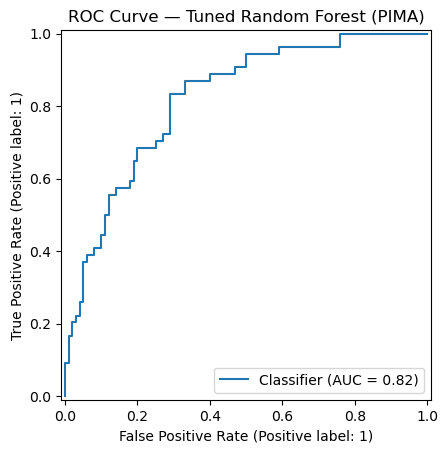

In [30]:
# New Cell — Test tuned RF on the same PIMA train-test split

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    matthews_corrcoef
)

import matplotlib.pyplot as plt

# ---- Prepare PIMA data ----
# If df_clean already exists, use it. Otherwise load and clean again.
try:
    X_pima_all = df_clean.drop(columns=["Outcome"])
    y_pima_all = df_clean["Outcome"]
    print("Using existing df_clean.")
except NameError:
    print("df_clean not found; loading PIMA and applying 0→NaN cleaning rule.")
    
    pima_path = r"C:\Users\HP\PhD Python\PIMA\PIMA diabetes.csv"
    df_pima = pd.read_csv(pima_path)
    
    cols_zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    df_pima[cols_zero_as_missing] = df_pima[cols_zero_as_missing].replace(0, np.nan)
    
    X_pima_all = df_pima.drop(columns=["Outcome"])
    y_pima_all = df_pima["Outcome"]

# ---- Same train-test split as earlier ----
X_train_pima, X_test_pima, y_train_pima, y_test_pima = train_test_split(
    X_pima_all,
    y_pima_all,
    test_size=0.20,
    random_state=42,
    stratify=y_pima_all
)

# ---- Tuned RF model from GridSearchCV best parameters ----
tuned_rf_pima = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        max_depth=10,
        max_features="sqrt",
        min_samples_leaf=4,
        min_samples_split=10
    ))
])

# ---- Fit on training data ----
tuned_rf_pima.fit(X_train_pima, y_train_pima)

# ---- Predict on test data ----
y_pred_tuned_rf = tuned_rf_pima.predict(X_test_pima)
y_proba_tuned_rf = tuned_rf_pima.predict_proba(X_test_pima)[:, 1]

# ---- Metrics ----
acc_tuned_rf = accuracy_score(y_test_pima, y_pred_tuned_rf)
mcc_tuned_rf = matthews_corrcoef(y_test_pima, y_pred_tuned_rf)
f1_tuned_rf = f1_score(y_test_pima, y_pred_tuned_rf)
auc_tuned_rf = roc_auc_score(y_test_pima, y_proba_tuned_rf)
cm_tuned_rf = confusion_matrix(y_test_pima, y_pred_tuned_rf)

print("=== Tuned Random Forest — PIMA Test Set ===")
print("Accuracy :", round(acc_tuned_rf, 4))
print("F1-score :", round(f1_tuned_rf, 4))
#print("Precision :", round(precision_tuned_rf, 4))
#print("Recall    :", round(recall_tuned_rf, 4))
print("MCC       :", round(mcc_tuned_rf, 4))
print("ROC-AUC  :", round(auc_tuned_rf, 4))

print("\nConfusion Matrix (rows=true, cols=pred):")
print(cm_tuned_rf)

print("\nClassification Report:")
print(classification_report(y_test_pima, y_pred_tuned_rf, digits=4))

# Optional ROC curve
RocCurveDisplay.from_predictions(y_test_pima, y_proba_tuned_rf)
plt.title("ROC Curve — Tuned Random Forest (PIMA)")
plt.show()

In [ ]:
# PIMA + Logistic Regression GridSearchCV.

In [31]:
# New Cell — PIMA: GridSearchCV for Logistic Regression
# Goal: tune LR hyperparameters using 5-fold CV

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, f1_score

# ---- Prepare PIMA data ----
# If df_clean already exists, use it. Otherwise load and clean again.
try:
    X_pima_all = df_clean.drop(columns=["Outcome"])
    y_pima_all = df_clean["Outcome"]
    print("Using existing df_clean.")
except NameError:
    print("df_clean not found; loading PIMA and applying 0→NaN cleaning rule.")
    
    pima_path = r"C:\Users\HP\PhD Python\PIMA\PIMA diabetes.csv"
    df_pima = pd.read_csv(pima_path)
    
    cols_zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    df_pima[cols_zero_as_missing] = df_pima[cols_zero_as_missing].replace(0, np.nan)
    
    X_pima_all = df_pima.drop(columns=["Outcome"])
    y_pima_all = df_pima["Outcome"]

# ---- Pipeline: Median Imputer → StandardScaler → Logistic Regression ----
lr_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# ---- Parameter grid ----
# Note: liblinear supports both l1 and l2 penalty.
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear"],
    "model__class_weight": [None, "balanced"]
}

# ---- 5-fold stratified CV ----
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Scoring: focus on diabetic class (Outcome = 1) ----
f1_scorer = make_scorer(f1_score, pos_label=1)

# ---- GridSearchCV ----
grid_lr_pima = GridSearchCV(
    estimator=lr_pipe,
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=cv5,
    n_jobs=-1,
    verbose=1
)

# ---- Run grid search ----
grid_lr_pima.fit(X_pima_all, y_pima_all)

print("Best CV F1 score:", round(grid_lr_pima.best_score_, 4))
print("\nBest hyperparameters:")
print(grid_lr_pima.best_params_)

# ---- Show top 5 parameter combinations ----
grid_results_lr = pd.DataFrame(grid_lr_pima.cv_results_)

top5_lr_pima = grid_results_lr[
    ["mean_test_score", "std_test_score", "params"]
].sort_values(by="mean_test_score", ascending=False).head(5)

top5_lr_pima["mean_test_score"] = top5_lr_pima["mean_test_score"].round(4)
top5_lr_pima["std_test_score"] = top5_lr_pima["std_test_score"].round(4)

display(top5_lr_pima)

Using existing df_clean.
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV F1 score: 0.677

Best hyperparameters:
{'model__C': 1, 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'model__solver': 'liblinear'}


,mean_test_score,std_test_score,params
10,0.6770,0.0483,"{'model__C': 1, 'model__class_weight': 'balanc..."
6,0.6695,0.0530,"{'model__C': 0.1, 'model__class_weight': 'bala..."
11,0.6688,0.0402,"{'model__C': 1, 'model__class_weight': 'balanc..."
18,0.6675,0.0368,"{'model__C': 100, 'model__class_weight': 'bala..."
15,0.6675,0.0368,"{'model__C': 10, 'model__class_weight': 'balan..."


Using existing df_clean.
=== Tuned Logistic Regression — PIMA Test Set ===
Accuracy : 0.7273
F1-score : 0.6441
ROC-AUC  : 0.8106
MCC      : 0.4296

Confusion Matrix (rows=true, cols=pred):
[[74 26]
 [16 38]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8222    0.7400    0.7789       100
           1     0.5938    0.7037    0.6441        54

    accuracy                         0.7273       154
   macro avg     0.7080    0.7219    0.7115       154
weighted avg     0.7421    0.7273    0.7317       154



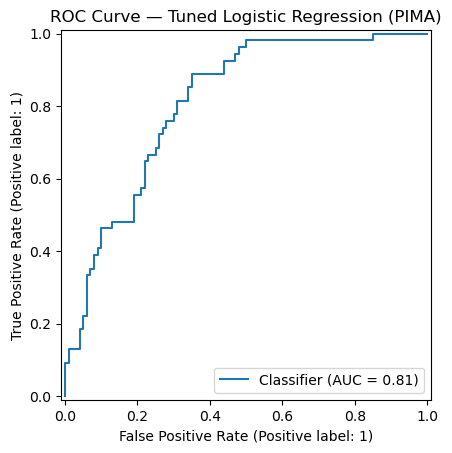

In [32]:
# New Cell — Test tuned LR on the same PIMA train-test split 
# THIS CODE IS NOT REQUIRED ANY MORE

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    matthews_corrcoef
)

import matplotlib.pyplot as plt

# ---- Prepare PIMA data ----
# If df_clean already exists, use it. Otherwise load and clean again.
try:
    X_pima_all = df_clean.drop(columns=["Outcome"])
    y_pima_all = df_clean["Outcome"]
    print("Using existing df_clean.")
except NameError:
    print("df_clean not found; loading PIMA and applying 0→NaN cleaning rule.")
    
    pima_path = r"C:\Users\HP\PhD Python\PIMA\PIMA diabetes.csv"
    df_pima = pd.read_csv(pima_path)
    
    cols_zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    df_pima[cols_zero_as_missing] = df_pima[cols_zero_as_missing].replace(0, np.nan)
    
    X_pima_all = df_pima.drop(columns=["Outcome"])
    y_pima_all = df_pima["Outcome"]

# ---- Same train-test split as earlier ----
X_train_pima, X_test_pima, y_train_pima, y_test_pima = train_test_split(
    X_pima_all,
    y_pima_all,
    test_size=0.20,
    random_state=42,
    stratify=y_pima_all
)

# ---- Tuned LR model from GridSearchCV best parameters ----
tuned_lr_pima = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=1,
        class_weight="balanced",
        penalty="l1",
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ))
])

# ---- Fit on training data ----
tuned_lr_pima.fit(X_train_pima, y_train_pima)

# ---- Predict on test data ----
y_pred_tuned_lr = tuned_lr_pima.predict(X_test_pima)
y_proba_tuned_lr = tuned_lr_pima.predict_proba(X_test_pima)[:, 1]

# ---- Metrics ----
acc_tuned_lr = accuracy_score(y_test_pima, y_pred_tuned_lr)
f1_tuned_lr = f1_score(y_test_pima, y_pred_tuned_lr)
auc_tuned_lr = roc_auc_score(y_test_pima, y_proba_tuned_lr)
cm_tuned_lr = confusion_matrix(y_test_pima, y_pred_tuned_lr)
mcc_tuned_lr = matthews_corrcoef(y_test_pima, y_pred_tuned_lr)

print("=== Tuned Logistic Regression — PIMA Test Set ===")
print("Accuracy :", round(acc_tuned_lr, 4))
print("F1-score :", round(f1_tuned_lr, 4))
print("ROC-AUC  :", round(auc_tuned_lr, 4))
print("MCC      :", round(mcc_tuned_lr, 4))

print("\nConfusion Matrix (rows=true, cols=pred):")
print(cm_tuned_lr)

print("\nClassification Report:")
print(classification_report(y_test_pima, y_pred_tuned_lr, digits=4))

# Optional ROC curve
RocCurveDisplay.from_predictions(y_test_pima, y_proba_tuned_lr)
plt.title("ROC Curve — Tuned Logistic Regression (PIMA)")
plt.show() 

In [ ]:
# STATISTICAL TESTING

In [31]:
# THIS CODE IS NOT REQUIRED ANY MORE

import numpy as np
from statsmodels.stats.contingency_tables import mcnemar

# Convert values to NumPy arrays
y_true = np.asarray(y_test_pima)
lr_pred = np.asarray(y_pred_tuned_lr)
rf_pred = np.asarray(y_pred_tuned_rf)

# Check that all arrays contain the same number of test cases
print("Test cases:", len(y_true))
print("LR predictions:", len(lr_pred))
print("RF predictions:", len(rf_pred))

# Find whether each prediction is correct
lr_correct = lr_pred == y_true
rf_correct = rf_pred == y_true

# Construct the paired comparison table
both_correct = np.sum(lr_correct & rf_correct)
only_lr_correct = np.sum(lr_correct & ~rf_correct)
only_rf_correct = np.sum(~lr_correct & rf_correct)
both_wrong = np.sum(~lr_correct & ~rf_correct)

table = [
    [both_correct, only_lr_correct],
    [only_rf_correct, both_wrong]
]

print("\nMcNemar contingency table:")
print(np.array(table))

print("\nBoth models correct :", both_correct)
print("Only LR correct     :", only_lr_correct)
print("Only RF correct     :", only_rf_correct)
print("Both models wrong   :", both_wrong)

# Exact McNemar test
result = mcnemar(table, exact=True)

print("\nMcNemar statistic:", result.statistic)
print("p-value:", result.pvalue)

if result.pvalue < 0.05:
    print("The performance difference is statistically significant.")
else:
    print("The performance difference is not statistically significant.")

Test cases: 154
LR predictions: 154
RF predictions: 154

McNemar contingency table:
[[105   7]
 [ 10  32]]

Both models correct : 105
Only LR correct     : 7
Only RF correct     : 10
Both models wrong   : 32

McNemar statistic: 7.0
p-value: 0.629058837890625
The performance difference is not statistically significant.


In [ ]:
## Fresh Code GRIDSEARCH CV LR ON PIMA

Using existing df_clean.

Training records: 614
Test records    : 154
Fitting 5 folds for each of 20 candidates, totalling 100 fits

=== Logistic Regression GridSearchCV Results ===
Number of parameter combinations: 20
Best CV F1-score: 0.6792
Best hyperparameters:
{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear'}


,mean_test_score,std_test_score,params
7,0.6792,0.0177,"{'model__C': 0.1, 'model__class_weight': 'bala..."
10,0.6737,0.0150,"{'model__C': 1, 'model__class_weight': 'balanc..."
18,0.6724,0.0133,"{'model__C': 100, 'model__class_weight': 'bala..."
15,0.6724,0.0133,"{'model__C': 10, 'model__class_weight': 'balan..."
14,0.6724,0.0133,"{'model__C': 10, 'model__class_weight': 'balan..."



=== Tuned Logistic Regression — PIMA Test Set ===
Accuracy  : 0.7208
Precision : 0.5846
Recall    : 0.7037
F1-score  : 0.6387
MCC       : 0.419
ROC-AUC   : 0.8106

Confusion Matrix (rows=true, columns=predicted):
[[73 27]
 [16 38]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8202    0.7300    0.7725       100
           1     0.5846    0.7037    0.6387        54

    accuracy                         0.7208       154
   macro avg     0.7024    0.7169    0.7056       154
weighted avg     0.7376    0.7208    0.7256       154



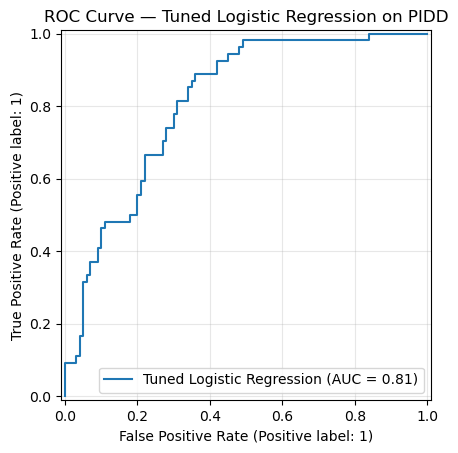

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    make_scorer
)

# ============================================================
# 1. Prepare PIMA dataset
# ============================================================

try:
    X_pima_all = df_clean.drop(columns=["Outcome"])
    y_pima_all = df_clean["Outcome"]
    print("Using existing df_clean.")

except NameError:
    print("df_clean not found; loading PIMA dataset.")

    pima_path = r"C:\Users\HP\PhD Python\PIMA\PIMA diabetes.csv"
    df_pima = pd.read_csv(pima_path)

    # Replace physiologically invalid zero values with NaN
    cols_zero_as_missing = [
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI"
    ]

    df_pima[cols_zero_as_missing] = (
        df_pima[cols_zero_as_missing].replace(0, np.nan)
    )

    X_pima_all = df_pima.drop(columns=["Outcome"])
    y_pima_all = df_pima["Outcome"]


# ============================================================
# 2. Create stratified 80:20 train-test split
# ============================================================

X_train_pima, X_test_pima, y_train_pima, y_test_pima = train_test_split(
    X_pima_all,
    y_pima_all,
    test_size=0.20,
    random_state=42,
    stratify=y_pima_all
)

print("\nTraining records:", len(X_train_pima))
print("Test records    :", len(X_test_pima))


# ============================================================
# 3. Logistic Regression pipeline
# ============================================================

lr_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])


# ============================================================
# 4. Hyperparameter grid
# ============================================================

param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear"],
    "model__class_weight": [None, "balanced"]
}


# ============================================================
# 5. Stratified 5-fold cross-validation
# ============================================================

cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Optimize F1-score for class 1
f1_scorer = make_scorer(
    f1_score,
    pos_label=1
)


# ============================================================
# 6. GridSearchCV on training data only
# ============================================================

grid_lr_pima = GridSearchCV(
    estimator=lr_pipe,
    param_grid=param_grid_lr,
    scoring=f1_scorer,
    cv=cv5,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

grid_lr_pima.fit(
    X_train_pima,
    y_train_pima
)


# ============================================================
# 7. Display best GridSearchCV result
# ============================================================

print("\n=== Logistic Regression GridSearchCV Results ===")
print("Number of parameter combinations:",
      len(grid_lr_pima.cv_results_["params"]))

print("Best CV F1-score:",
      round(grid_lr_pima.best_score_, 4))

print("Best hyperparameters:")
print(grid_lr_pima.best_params_)


# ============================================================
# 8. Display top five parameter combinations
# ============================================================

grid_results_lr = pd.DataFrame(
    grid_lr_pima.cv_results_
)

top5_lr_pima = grid_results_lr[
    [
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
).head(5)

top5_lr_pima["mean_test_score"] = (
    top5_lr_pima["mean_test_score"].round(4)
)

top5_lr_pima["std_test_score"] = (
    top5_lr_pima["std_test_score"].round(4)
)

display(top5_lr_pima)


# ============================================================
# 9. Obtain the best tuned Logistic Regression model
# ============================================================

best_lr_pima = grid_lr_pima.best_estimator_


# ============================================================
# 10. Evaluate on untouched test set
# ============================================================

y_pred_tuned_lr = best_lr_pima.predict(
    X_test_pima
)

y_proba_tuned_lr = best_lr_pima.predict_proba(
    X_test_pima
)[:, 1]


# ============================================================
# 11. Calculate test-set metrics
# ============================================================

acc_tuned_lr = accuracy_score(
    y_test_pima,
    y_pred_tuned_lr
)

precision_tuned_lr = precision_score(
    y_test_pima,
    y_pred_tuned_lr,
    pos_label=1
)

recall_tuned_lr = recall_score(
    y_test_pima,
    y_pred_tuned_lr,
    pos_label=1
)

f1_tuned_lr = f1_score(
    y_test_pima,
    y_pred_tuned_lr,
    pos_label=1
)

mcc_tuned_lr = matthews_corrcoef(
    y_test_pima,
    y_pred_tuned_lr
)

auc_tuned_lr = roc_auc_score(
    y_test_pima,
    y_proba_tuned_lr
)

cm_tuned_lr = confusion_matrix(
    y_test_pima,
    y_pred_tuned_lr
)


# ============================================================
# 12. Print test-set results
# ============================================================

print("\n=== Tuned Logistic Regression — PIMA Test Set ===")
print("Accuracy  :", round(acc_tuned_lr, 4))
print("Precision :", round(precision_tuned_lr, 4))
print("Recall    :", round(recall_tuned_lr, 4))
print("F1-score  :", round(f1_tuned_lr, 4))
print("MCC       :", round(mcc_tuned_lr, 4))
print("ROC-AUC   :", round(auc_tuned_lr, 4))

print("\nConfusion Matrix (rows=true, columns=predicted):")
print(cm_tuned_lr)

print("\nClassification Report:")
print(
    classification_report(
        y_test_pima,
        y_pred_tuned_lr,
        digits=4
    )
)


# ============================================================
# 13. ROC curve
# ============================================================

RocCurveDisplay.from_predictions(
    y_test_pima,
    y_proba_tuned_lr,
    name="Tuned Logistic Regression"
)

plt.title("ROC Curve — Tuned Logistic Regression on PIDD")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
## Fresh Code GRIDSEARCH CV RF ON PIMA

Using existing df_clean.

Training records: 614
Test records    : 154
Fitting 5 folds for each of 72 candidates, totalling 360 fits

=== Random Forest GridSearchCV Results ===
Number of parameter combinations: 72
Best CV F1-score: 0.7049
Best hyperparameters:
{'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}


,mean_test_score,std_test_score,params
19,0.7049,0.0128,"{'model__max_depth': 5, 'model__max_features':..."
22,0.7009,0.0206,"{'model__max_depth': 5, 'model__max_features':..."
29,0.6979,0.0103,"{'model__max_depth': 5, 'model__max_features':..."
35,0.6963,0.0129,"{'model__max_depth': 5, 'model__max_features':..."
28,0.6949,0.0101,"{'model__max_depth': 5, 'model__max_features':..."



=== Tuned Random Forest — PIMA Test Set ===
Accuracy  : 0.7468
Precision : 0.6154
Recall    : 0.7407
F1-score  : 0.6723
MCC       : 0.4741
ROC-AUC   : 0.8174

Confusion Matrix (rows=true, columns=predicted):
[[75 25]
 [14 40]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8427    0.7500    0.7937       100
           1     0.6154    0.7407    0.6723        54

    accuracy                         0.7468       154
   macro avg     0.7290    0.7454    0.7330       154
weighted avg     0.7630    0.7468    0.7511       154



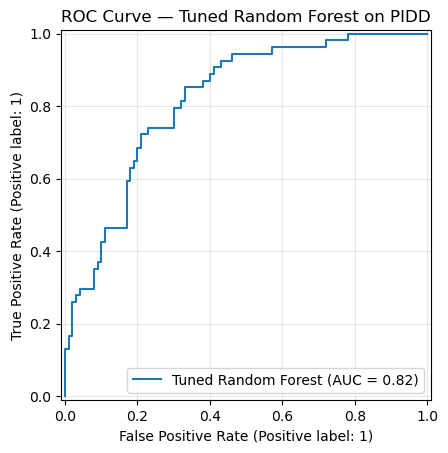

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    make_scorer
)

# ============================================================
# 1. Prepare PIMA dataset
# ============================================================

try:
    X_pima_all = df_clean.drop(columns=["Outcome"])
    y_pima_all = df_clean["Outcome"]
    print("Using existing df_clean.")

except NameError:
    print("df_clean not found; loading and cleaning PIMA dataset.")

    pima_path = r"C:\Users\HP\PhD Python\PIMA\PIMA diabetes.csv"
    df_pima = pd.read_csv(pima_path)

    cols_zero_as_missing = [
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI"
    ]

    df_pima[cols_zero_as_missing] = (
        df_pima[cols_zero_as_missing].replace(0, np.nan)
    )

    X_pima_all = df_pima.drop(columns=["Outcome"])
    y_pima_all = df_pima["Outcome"]


# ============================================================
# 2. Create the same stratified 80:20 train-test split
# ============================================================

X_train_pima, X_test_pima, y_train_pima, y_test_pima = train_test_split(
    X_pima_all,
    y_pima_all,
    test_size=0.20,
    random_state=42,
    stratify=y_pima_all
)

print("\nTraining records:", len(X_train_pima))
print("Test records    :", len(X_test_pima))


# ============================================================
# 3. Random Forest pipeline
# ============================================================

rf_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])


# ============================================================
# 4. Hyperparameter grid
# ============================================================

param_grid_rf = {
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}


# ============================================================
# 5. Stratified 5-fold cross-validation
# ============================================================

cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Optimize the F1-score for class 1
f1_scorer = make_scorer(
    f1_score,
    pos_label=1
)


# ============================================================
# 6. GridSearchCV on training data only
# ============================================================

grid_rf_pima = GridSearchCV(
    estimator=rf_pipe,
    param_grid=param_grid_rf,
    scoring=f1_scorer,
    cv=cv5,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

grid_rf_pima.fit(
    X_train_pima,
    y_train_pima
)


# ============================================================
# 7. Display best GridSearchCV result
# ============================================================

print("\n=== Random Forest GridSearchCV Results ===")

print(
    "Number of parameter combinations:",
    len(grid_rf_pima.cv_results_["params"])
)

print(
    "Best CV F1-score:",
    round(grid_rf_pima.best_score_, 4)
)

print("Best hyperparameters:")
print(grid_rf_pima.best_params_)


# ============================================================
# 8. Show top five parameter combinations
# ============================================================

grid_results_rf = pd.DataFrame(
    grid_rf_pima.cv_results_
)

top5_rf_pima = grid_results_rf[
    [
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
).head(5)

top5_rf_pima["mean_test_score"] = (
    top5_rf_pima["mean_test_score"].round(4)
)

top5_rf_pima["std_test_score"] = (
    top5_rf_pima["std_test_score"].round(4)
)

display(top5_rf_pima)


# ============================================================
# 9. Obtain the best tuned Random Forest
# ============================================================

best_rf_pima = grid_rf_pima.best_estimator_


# ============================================================
# 10. Evaluate on untouched test set
# ============================================================

y_pred_tuned_rf = best_rf_pima.predict(
    X_test_pima
)

y_proba_tuned_rf = best_rf_pima.predict_proba(
    X_test_pima
)[:, 1]


# ============================================================
# 11. Calculate test-set metrics
# ============================================================

acc_tuned_rf = accuracy_score(
    y_test_pima,
    y_pred_tuned_rf
)

precision_tuned_rf = precision_score(
    y_test_pima,
    y_pred_tuned_rf,
    pos_label=1
)

recall_tuned_rf = recall_score(
    y_test_pima,
    y_pred_tuned_rf,
    pos_label=1
)

f1_tuned_rf = f1_score(
    y_test_pima,
    y_pred_tuned_rf,
    pos_label=1
)

mcc_tuned_rf = matthews_corrcoef(
    y_test_pima,
    y_pred_tuned_rf
)

auc_tuned_rf = roc_auc_score(
    y_test_pima,
    y_proba_tuned_rf
)

cm_tuned_rf = confusion_matrix(
    y_test_pima,
    y_pred_tuned_rf
)


# ============================================================
# 12. Print test-set results
# ============================================================

print("\n=== Tuned Random Forest — PIMA Test Set ===")
print("Accuracy  :", round(acc_tuned_rf, 4))
print("Precision :", round(precision_tuned_rf, 4))
print("Recall    :", round(recall_tuned_rf, 4))
print("F1-score  :", round(f1_tuned_rf, 4))
print("MCC       :", round(mcc_tuned_rf, 4))
print("ROC-AUC   :", round(auc_tuned_rf, 4))

print("\nConfusion Matrix (rows=true, columns=predicted):")
print(cm_tuned_rf)

print("\nClassification Report:")
print(
    classification_report(
        y_test_pima,
        y_pred_tuned_rf,
        digits=4
    )
)


# ============================================================
# 13. ROC curve
# ============================================================

RocCurveDisplay.from_predictions(
    y_test_pima,
    y_proba_tuned_rf,
    name="Tuned Random Forest"
)

plt.title("ROC Curve — Tuned Random Forest on PIDD")
plt.grid(alpha=0.3)
plt.show()

In [34]:
print(len(y_test_pima))
print(len(y_pred_tuned_lr))
print(len(y_pred_tuned_rf))

154
154
154


In [ ]:
## FRESH STATISTICAL TESTING

In [35]:
import numpy as np
from statsmodels.stats.contingency_tables import mcnemar

# Convert to NumPy arrays
y_true = np.asarray(y_test_pima)
lr_pred = np.asarray(y_pred_tuned_lr)
rf_pred = np.asarray(y_pred_tuned_rf)

# Confirm that both models were tested on the same 154 records
print("Test cases      :", len(y_true))
print("LR predictions  :", len(lr_pred))
print("RF predictions  :", len(rf_pred))

# Determine whether each model predicted each test case correctly
lr_correct = lr_pred == y_true
rf_correct = rf_pred == y_true

# Paired prediction counts
both_correct = np.sum(lr_correct & rf_correct)
only_lr_correct = np.sum(lr_correct & ~rf_correct)
only_rf_correct = np.sum(~lr_correct & rf_correct)
both_wrong = np.sum(~lr_correct & ~rf_correct)

# McNemar contingency table
mcnemar_table = [
    [both_correct, only_lr_correct],
    [only_rf_correct, both_wrong]
]

print("\nMcNemar contingency table:")
print(np.array(mcnemar_table))

print("\nBoth models correct :", both_correct)
print("Only LR correct     :", only_lr_correct)
print("Only RF correct     :", only_rf_correct)
print("Both models wrong   :", both_wrong)

# Exact McNemar test
result = mcnemar(mcnemar_table, exact=True)

print("\nMcNemar statistic :", result.statistic)
print("p-value           :", result.pvalue)

if result.pvalue < 0.05:
    print("The performance difference is statistically significant.")
else:
    print("The performance difference is not statistically significant.")

Test cases      : 154
LR predictions  : 154
RF predictions  : 154

McNemar contingency table:
[[104   7]
 [ 11  32]]

Both models correct : 104
Only LR correct     : 7
Only RF correct     : 11
Both models wrong   : 32

McNemar statistic : 7.0
p-value           : 0.480682373046875
The performance difference is not statistically significant.


In [36]:
print("Training records:", len(X_train_pima))
print("Test records:", len(X_test_pima))

Training records: 614
Test records: 154


In [ ]:
## To calculate baseline CV F1

In [36]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score


# Same cross-validation configuration used in GridSearchCV
cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# F1-score for the diabetic class: Outcome = 1
f1_scorer = make_scorer(
    f1_score,
    pos_label=1
)


# ---------------------------------------------------------
# Baseline Logistic Regression
# Original PIDD baseline configuration
# ---------------------------------------------------------
baseline_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_baseline_scores = cross_val_score(
    baseline_lr,
    X_train_pima,
    y_train_pima,
    scoring=f1_scorer,
    cv=cv5,
    n_jobs=-1
)


# ---------------------------------------------------------
# Baseline Random Forest
# Original PIDD baseline configuration
# ---------------------------------------------------------
baseline_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

rf_baseline_scores = cross_val_score(
    baseline_rf,
    X_train_pima,
    y_train_pima,
    scoring=f1_scorer,
    cv=cv5,
    n_jobs=-1
)


# ---------------------------------------------------------
# Display fold-wise and mean CV F1-scores
# ---------------------------------------------------------
print("Baseline LR fold-wise F1-scores:",
      np.round(lr_baseline_scores, 4))

print("Baseline LR mean CV F1:",
      round(lr_baseline_scores.mean(), 4),
      "±",
      round(lr_baseline_scores.std(), 4))


print("\nBaseline RF fold-wise F1-scores:",
      np.round(rf_baseline_scores, 4))

print("Baseline RF mean CV F1:",
      round(rf_baseline_scores.mean(), 4),
      "±",
      round(rf_baseline_scores.std(), 4))


# ---------------------------------------------------------
# Baseline-versus-tuned comparison
# ---------------------------------------------------------
comparison_table = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Baseline Mean CV F1": [
        lr_baseline_scores.mean(),
        rf_baseline_scores.mean()
    ],
    "Tuned Mean CV F1": [
        0.6792,
        0.7049
    ]
})

comparison_table["Improvement"] = (
    comparison_table["Tuned Mean CV F1"]
    - comparison_table["Baseline Mean CV F1"]
)

print("\nBaseline versus tuned comparison:")
print(comparison_table.round(4).to_string(index=False))

Baseline LR fold-wise F1-scores: [0.6389 0.6667 0.6944 0.6494 0.6234]
Baseline LR mean CV F1: 0.6545 ± 0.0244

Baseline RF fold-wise F1-scores: [0.64   0.6265 0.6842 0.6118 0.6329]
Baseline RF mean CV F1: 0.6391 ± 0.0244

Baseline versus tuned comparison:
              Model  Baseline Mean CV F1  Tuned Mean CV F1  Improvement
Logistic Regression               0.6545            0.6792       0.0247
      Random Forest               0.6391            0.7049       0.0658


In [ ]:
#precision–recall curve

In [38]:
print(y_proba_tuned_lr.shape)
print(y_proba_tuned_rf.shape)
print(y_test_pima.shape)

(154,)
(154,)
(154,)


In [40]:
print("y_test_pima       :", y_test_pima.shape)
print("LR probabilities :", y_proba_tuned_lr.shape)
print("RF probabilities :", y_proba_tuned_rf.shape)

y_test_pima       : (154,)
LR probabilities : (154,)
RF probabilities : (154,)


Tuned Logistic Regression AP: 0.6653
Tuned Random Forest AP      : 0.7035
No-skill baseline           : 0.3506


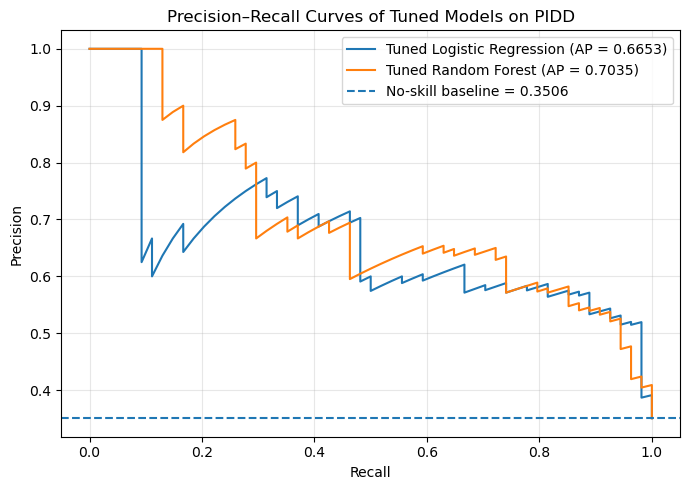

In [37]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Precision–recall values
precision_lr, recall_lr, _ = precision_recall_curve(
    y_test_pima,
    y_proba_tuned_lr
)

precision_rf, recall_rf, _ = precision_recall_curve(
    y_test_pima,
    y_proba_tuned_rf
)

# Average Precision scores
ap_lr = average_precision_score(
    y_test_pima,
    y_proba_tuned_lr
)

ap_rf = average_precision_score(
    y_test_pima,
    y_proba_tuned_rf
)

# Positive-class proportion in the test set
baseline_precision = y_test_pima.mean()

print("Tuned Logistic Regression AP:", round(ap_lr, 4))
print("Tuned Random Forest AP      :", round(ap_rf, 4))
print("No-skill baseline           :", round(baseline_precision, 4))

# Combined PR curve
plt.figure(figsize=(7, 5))

plt.plot(
    recall_lr,
    precision_lr,
    label=f"Tuned Logistic Regression (AP = {ap_lr:.4f})"
)

plt.plot(
    recall_rf,
    precision_rf,
    label=f"Tuned Random Forest (AP = {ap_rf:.4f})"
)

plt.axhline(
    y=baseline_precision,
    linestyle="--",
    label=f"No-skill baseline = {baseline_precision:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves of Tuned Models on PIDD")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "pidd_tuned_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
import os
print(os.getcwd())


C:\Users\HP\PhD Python\PIMA


In [ ]:
#Feature importance of the tuned Random Forest model on the PIDD dataset.


Permutation Feature Importance — Tuned Random Forest
                 Feature  Mean Importance  Standard Deviation
                 Glucose           0.1052              0.0315
                     Age           0.0617              0.0226
                     BMI           0.0486              0.0327
                 Insulin           0.0126              0.0234
DiabetesPedigreeFunction           0.0038              0.0151
             Pregnancies           0.0005              0.0116
           BloodPressure          -0.0004              0.0071
           SkinThickness          -0.0008              0.0140


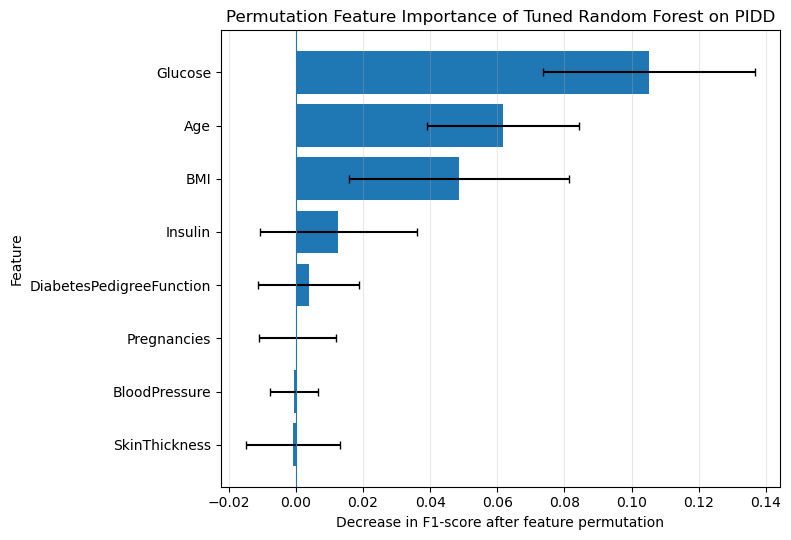


PNG saved at: C:\Users\HP\PhD Python\PIMA\pidd_rf_permutation_feature_importance.png
PDF saved at: C:\Users\HP\PhD Python\PIMA\pidd_rf_permutation_feature_importance.pdf


In [42]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# ============================================================
# 1. Calculate permutation importance on untouched PIDD test set
# ============================================================

perm_result_rf = permutation_importance(
    estimator=best_rf_pima,
    X=X_test_pima,
    y=y_test_pima,
    scoring="f1",        # F1-score for diabetic class
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

# ============================================================
# 2. Obtain feature names
# ============================================================

if hasattr(X_test_pima, "columns"):
    feature_names = X_test_pima.columns
else:
    feature_names = X_pima_all.columns

# ============================================================
# 3. Prepare importance table
# ============================================================

rf_permutation_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Importance": perm_result_rf.importances_mean,
    "Standard Deviation": perm_result_rf.importances_std
})

rf_permutation_importance = (
    rf_permutation_importance
    .sort_values(by="Mean Importance", ascending=False)
    .reset_index(drop=True)
)

print("\nPermutation Feature Importance — Tuned Random Forest")
print(rf_permutation_importance.round(4).to_string(index=False))

# ============================================================
# 4. Prepare data for horizontal bar chart
# ============================================================

plot_data = rf_permutation_importance.sort_values(
    by="Mean Importance",
    ascending=True
)

# ============================================================
# 5. Draw figure
# ============================================================

plt.figure(figsize=(8, 5.5))

plt.barh(
    plot_data["Feature"],
    plot_data["Mean Importance"],
    xerr=plot_data["Standard Deviation"],
    capsize=3
)

plt.axvline(
    x=0,
    linewidth=0.8
)

plt.xlabel("Decrease in F1-score after feature permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance of Tuned Random Forest on PIDD")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# ============================================================
# 6. Save before displaying
# ============================================================

save_folder = r"C:\Users\HP\PhD Python\PIMA"
os.makedirs(save_folder, exist_ok=True)

png_path = os.path.join(
    save_folder,
    "pidd_rf_permutation_feature_importance.png"
)

pdf_path = os.path.join(
    save_folder,
    "pidd_rf_permutation_feature_importance.pdf"
)

plt.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print("\nPNG saved at:", png_path)
print("PDF saved at:", pdf_path)

In [43]:
print(best_rf_pima.named_steps["model"].n_features_in_)

8


In [44]:
print("Best CV F1-score:",
      round(grid_lr_pima.best_score_, 4))

print("Best hyperparameters:")
print(grid_lr_pima.best_params_)

Best CV F1-score: 0.6792
Best hyperparameters:
{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear'}


In [ ]:
# New Safety Check Cell 

In [45]:
print("df_clean available:", "df_clean" in globals())
print("uci_df available:", "uci_df" in globals())

if "df_clean" in globals():
    print("PIDD shape:", df_clean.shape)

if "uci_df" in globals():
    print("UCI shape:", uci_df.shape)

df_clean available: True
uci_df available: True
PIDD shape: (768, 9)
UCI shape: (520, 17)


In [46]:
# ============================================================
# FEATURE-LEVEL CLASS SEPARABILITY ANALYSIS
# PIDD + UCI Early Stage Diabetes Risk Prediction Dataset
#
# IMPORTANT:
# - This is a separate descriptive/statistical analysis.
# - It does NOT modify existing LR/RF models, preprocessing,
#   train-test splits, CV, tuning, McNemar, MCC, PR/AP,
#   or permutation feature importance.
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import mannwhitneyu, chi2_contingency, fisher_exact
from sklearn.metrics import roc_auc_score


# ------------------------------------------------------------
# Benjamini-Hochberg False Discovery Rate correction
# ------------------------------------------------------------
def bh_fdr(p_values):
    """
    Benjamini-Hochberg correction for multiple comparisons.
    Returns FDR-adjusted p-values in the original order.
    """
    p = np.asarray(p_values, dtype=float)
    n = len(p)

    order = np.argsort(p)
    ranked_p = p[order]

    adjusted = ranked_p * n / np.arange(1, n + 1)

    # Ensure monotonicity
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)

    result = np.empty(n)
    result[order] = adjusted

    return result


# ============================================================
# PART 1: PIDD
# ============================================================

print("=" * 70)
print("PIDD FEATURE-LEVEL CLASS SEPARABILITY")
print("=" * 70)

if "df_clean" not in globals():
    raise RuntimeError(
        "df_clean was not found. Run the existing PIDD loading and "
        "cleaning cells first."
    )

if "Outcome" not in df_clean.columns:
    raise RuntimeError("Outcome column not found in df_clean.")


# All PIDD predictors
sep_pidd_features = [
    col for col in df_clean.columns
    if col != "Outcome"
]

sep_pidd_rows = []


for feature in sep_pidd_features:

    # Use available observations only.
    # No new imputation is performed here.
    temp = df_clean[[feature, "Outcome"]].dropna().copy()

    group_0 = temp.loc[
        temp["Outcome"] == 0, feature
    ].astype(float)

    group_1 = temp.loc[
        temp["Outcome"] == 1, feature
    ].astype(float)

    # --------------------------------------------------------
    # Mann-Whitney U test
    # --------------------------------------------------------
    u_stat, raw_p = mannwhitneyu(
        group_1,
        group_0,
        alternative="two-sided",
        method="auto"
    )

    # --------------------------------------------------------
    # Rank-biserial correlation
    #
    # Positive value:
    # feature tends to be higher for diabetic class.
    #
    # Negative value:
    # feature tends to be lower for diabetic class.
    # --------------------------------------------------------
    n1 = len(group_1)
    n0 = len(group_0)

    rank_biserial = (
        (2 * u_stat) / (n1 * n0)
    ) - 1


    # --------------------------------------------------------
    # Descriptive single-feature ROC-AUC
    #
    # IMPORTANT:
    # This is NOT model-validation AUC.
    # It simply tells us how strongly one feature by itself
    # separates Outcome 0 and Outcome 1.
    # --------------------------------------------------------
    y_temp = temp["Outcome"].astype(int).values
    x_temp = temp[feature].astype(float).values

    auc_raw = roc_auc_score(
        y_temp,
        x_temp
    )

    # Direction-independent separation
    auc_separation = max(
        auc_raw,
        1 - auc_raw
    )

    if auc_raw >= 0.5:
        auc_direction = "Higher values associated with Outcome 1"
    else:
        auc_direction = "Lower values associated with Outcome 1"


    sep_pidd_rows.append({

        "Feature": feature,

        "N_NonDiabetic":
            len(group_0),

        "N_Diabetic":
            len(group_1),

        "Median_NonDiabetic":
            group_0.median(),

        "IQR_NonDiabetic":
            group_0.quantile(0.75)
            - group_0.quantile(0.25),

        "Median_Diabetic":
            group_1.median(),

        "IQR_Diabetic":
            group_1.quantile(0.75)
            - group_1.quantile(0.25),

        "Rank_Biserial":
            rank_biserial,

        "Abs_Rank_Biserial":
            abs(rank_biserial),

        "Single_Feature_AUC":
            auc_raw,

        "AUC_Separation":
            auc_separation,

        "Direction":
            auc_direction,

        "Raw_p":
            raw_p
    })


sep_pidd_results = pd.DataFrame(
    sep_pidd_rows
)


# FDR correction
sep_pidd_results["FDR_p"] = bh_fdr(
    sep_pidd_results["Raw_p"]
)

sep_pidd_results[
    "Significant_after_FDR"
] = (
    sep_pidd_results["FDR_p"] < 0.05
)


# Rank by single-feature separation
sep_pidd_results = (
    sep_pidd_results
    .sort_values(
        by=[
            "AUC_Separation",
            "Abs_Rank_Biserial"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\nPIDD results "
    "(ranked by univariate class separation):\n"
)

display(
    sep_pidd_results.style.format({

        "Median_NonDiabetic":
            "{:.3f}",

        "IQR_NonDiabetic":
            "{:.3f}",

        "Median_Diabetic":
            "{:.3f}",

        "IQR_Diabetic":
            "{:.3f}",

        "Rank_Biserial":
            "{:.3f}",

        "Abs_Rank_Biserial":
            "{:.3f}",

        "Single_Feature_AUC":
            "{:.3f}",

        "AUC_Separation":
            "{:.3f}",

        "Raw_p":
            "{:.4g}",

        "FDR_p":
            "{:.4g}"
    })
)


# ============================================================
# PART 2: UCI EARLY STAGE DIABETES DATASET
# ============================================================

print("\n")
print("=" * 70)
print("UCI FEATURE-LEVEL CLASS ASSOCIATION / SEPARABILITY")
print("=" * 70)


if "uci_df" not in globals():
    raise RuntimeError(
        "uci_df was not found. Run the existing UCI loading "
        "cell first."
    )

if "class" not in uci_df.columns:
    raise RuntimeError(
        "Target column 'class' not found in uci_df."
    )


# ------------------------------------------------------------
# Convert target to binary only for this analysis
# ------------------------------------------------------------

sep_target_map = {
    "Negative": 0,
    "Positive": 1
}


observed_labels = set(
    uci_df["class"].dropna().unique()
)

expected_labels = set(
    sep_target_map.keys()
)

if not observed_labels.issubset(
    expected_labels
):
    raise RuntimeError(
        "Unexpected target labels found in UCI dataset: "
        + str(observed_labels)
    )


# ============================================================
# PART 2A: AGE
# ============================================================

sep_uci_age_result = None


if "Age" in uci_df.columns:

    age_temp = (
        uci_df[
            ["Age", "class"]
        ]
        .dropna()
        .copy()
    )

    age_temp["Target_binary"] = (
        age_temp["class"]
        .map(sep_target_map)
        .astype(int)
    )


    age_negative = age_temp.loc[
        age_temp["Target_binary"] == 0,
        "Age"
    ].astype(float)

    age_positive = age_temp.loc[
        age_temp["Target_binary"] == 1,
        "Age"
    ].astype(float)


    # Mann-Whitney
    age_u, age_p = mannwhitneyu(
        age_positive,
        age_negative,
        alternative="two-sided",
        method="auto"
    )


    age_rank_biserial = (
        (2 * age_u)
        /
        (
            len(age_positive)
            * len(age_negative)
        )
    ) - 1


    age_auc_raw = roc_auc_score(
        age_temp["Target_binary"],
        age_temp["Age"].astype(float)
    )

    age_auc_separation = max(
        age_auc_raw,
        1 - age_auc_raw
    )


    sep_uci_age_result = pd.DataFrame([{

        "Feature":
            "Age",

        "N_Negative":
            len(age_negative),

        "N_Positive":
            len(age_positive),

        "Median_Negative":
            age_negative.median(),

        "IQR_Negative":
            age_negative.quantile(0.75)
            - age_negative.quantile(0.25),

        "Median_Positive":
            age_positive.median(),

        "IQR_Positive":
            age_positive.quantile(0.75)
            - age_positive.quantile(0.25),

        "Rank_Biserial":
            age_rank_biserial,

        "Abs_Rank_Biserial":
            abs(age_rank_biserial),

        "Single_Feature_AUC":
            age_auc_raw,

        "AUC_Separation":
            age_auc_separation,

        "Raw_p":
            age_p
    }])


# ============================================================
# PART 2B: UCI CATEGORICAL FEATURES
# ============================================================

sep_uci_categorical_features = [

    col for col in uci_df.columns

    if col not in [
        "class",
        "Age"
    ]
]


sep_uci_rows = []


for feature in sep_uci_categorical_features:

    temp = (
        uci_df[
            [feature, "class"]
        ]
        .dropna()
        .copy()
    )


    contingency = pd.crosstab(
        temp[feature],
        temp["class"]
    )


    if (
        contingency.shape[0] < 2
        or contingency.shape[1] < 2
    ):
        continue


    # --------------------------------------------------------
    # Chi-square and expected frequencies
    # --------------------------------------------------------

    chi2, chi_p, dof, expected = (
        chi2_contingency(
            contingency,
            correction=False
        )
    )


    n = contingency.to_numpy().sum()

    minimum_dimension = min(
        contingency.shape[0] - 1,
        contingency.shape[1] - 1
    )


    # --------------------------------------------------------
    # Cramer's V
    # --------------------------------------------------------

    if (
        minimum_dimension > 0
        and n > 0
    ):

        cramers_v = np.sqrt(
            chi2
            /
            (
                n
                * minimum_dimension
            )
        )

    else:
        cramers_v = np.nan


    # --------------------------------------------------------
    # Fisher exact if 2x2 and expected counts are small
    # --------------------------------------------------------

    if (
        contingency.shape == (2, 2)
        and np.any(expected < 5)
    ):

        _, test_p = fisher_exact(
            contingency.to_numpy()
        )

        test_used = "Fisher exact"

    else:

        test_p = chi_p

        test_used = "Chi-square"


    # --------------------------------------------------------
    # Class-wise proportions
    # --------------------------------------------------------

    proportions = pd.crosstab(
        temp[feature],
        temp["class"],
        normalize="columns"
    )


    if (
        "Positive" in proportions.columns
        and
        "Negative" in proportions.columns
    ):

        differences = abs(
            proportions["Positive"]
            -
            proportions["Negative"]
        )


        most_separating_level = (
            differences.idxmax()
        )


        prop_positive = proportions.loc[
            most_separating_level,
            "Positive"
        ]


        prop_negative = proportions.loc[
            most_separating_level,
            "Negative"
        ]


        absolute_difference = abs(
            prop_positive
            -
            prop_negative
        )


    else:

        most_separating_level = np.nan
        prop_positive = np.nan
        prop_negative = np.nan
        absolute_difference = np.nan


    sep_uci_rows.append({

        "Feature":
            feature,

        "Test":
            test_used,

        "Cramers_V":
            cramers_v,

        "Most_Separating_Level":
            most_separating_level,

        "Proportion_Positive_Class":
            prop_positive,

        "Proportion_Negative_Class":
            prop_negative,

        "Absolute_Proportion_Difference":
            absolute_difference,

        "Raw_p":
            test_p
    })


sep_uci_categorical_results = pd.DataFrame(
    sep_uci_rows
)


# ============================================================
# FDR correction across ALL UCI feature tests
# Age + categorical variables
# ============================================================

all_uci_pvalues = []


if sep_uci_age_result is not None:

    all_uci_pvalues.append(
        float(
            sep_uci_age_result.loc[
                0,
                "Raw_p"
            ]
        )
    )


all_uci_pvalues.extend(

    sep_uci_categorical_results[
        "Raw_p"
    ]
    .astype(float)
    .tolist()
)


uci_fdr_values = bh_fdr(
    all_uci_pvalues
)


offset = 0


if sep_uci_age_result is not None:

    sep_uci_age_result[
        "FDR_p"
    ] = uci_fdr_values[0]

    sep_uci_age_result[
        "Significant_after_FDR"
    ] = (
        sep_uci_age_result[
            "FDR_p"
        ] < 0.05
    )

    offset = 1


sep_uci_categorical_results[
    "FDR_p"
] = uci_fdr_values[offset:]


sep_uci_categorical_results[
    "Significant_after_FDR"
] = (
    sep_uci_categorical_results[
        "FDR_p"
    ] < 0.05
)


# Rank categorical variables by association strength
sep_uci_categorical_results = (

    sep_uci_categorical_results

    .sort_values(
        by=[
            "Cramers_V",
            "Absolute_Proportion_Difference"
        ],
        ascending=False
    )

    .reset_index(drop=True)
)


# ============================================================
# DISPLAY UCI RESULTS
# ============================================================

print("\nUCI numerical variable: AGE\n")

display(

    sep_uci_age_result.style.format({

        "Median_Negative":
            "{:.3f}",

        "IQR_Negative":
            "{:.3f}",

        "Median_Positive":
            "{:.3f}",

        "IQR_Positive":
            "{:.3f}",

        "Rank_Biserial":
            "{:.3f}",

        "Abs_Rank_Biserial":
            "{:.3f}",

        "Single_Feature_AUC":
            "{:.3f}",

        "AUC_Separation":
            "{:.3f}",

        "Raw_p":
            "{:.4g}",

        "FDR_p":
            "{:.4g}"
    })
)


print(
    "\nUCI categorical variables "
    "(ranked by Cramer's V):\n"
)


display(

    sep_uci_categorical_results.style.format({

        "Cramers_V":
            "{:.3f}",

        "Proportion_Positive_Class":
            "{:.3f}",

        "Proportion_Negative_Class":
            "{:.3f}",

        "Absolute_Proportion_Difference":
            "{:.3f}",

        "Raw_p":
            "{:.4g}",

        "FDR_p":
            "{:.4g}"
    })
)


# ============================================================
# COMPACT SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("COMPACT SUMMARY")
print("=" * 70)


print(
    "\nTop 5 PIDD features by "
    "single-feature separation:\n"
)

display(

    sep_pidd_results[
        [
            "Feature",
            "AUC_Separation",
            "Rank_Biserial",
            "FDR_p"
        ]
    ]
    .head(5)
    .style.format({

        "AUC_Separation":
            "{:.3f}",

        "Rank_Biserial":
            "{:.3f}",

        "FDR_p":
            "{:.4g}"
    })
)


print(
    "\nTop 5 UCI categorical features "
    "by Cramer's V:\n"
)

display(

    sep_uci_categorical_results[
        [
            "Feature",
            "Cramers_V",
            "Most_Separating_Level",
            "Proportion_Positive_Class",
            "Proportion_Negative_Class",
            "Absolute_Proportion_Difference",
            "FDR_p"
        ]
    ]
    .head(5)
    .style.format({

        "Cramers_V":
            "{:.3f}",

        "Proportion_Positive_Class":
            "{:.3f}",

        "Proportion_Negative_Class":
            "{:.3f}",

        "Absolute_Proportion_Difference":
            "{:.3f}",

        "FDR_p":
            "{:.4g}"
    })
)


print("\nIMPORTANT:")
print(
    "Do not yet conclude that UCI has stronger class "
    "separation than PIDD."
)
print(
    "First inspect the effect sizes and FDR-adjusted "
    "p-values produced above."
)

PIDD FEATURE-LEVEL CLASS SEPARABILITY

PIDD results (ranked by univariate class separation):



,Feature,N_NonDiabetic,N_Diabetic,Median_NonDiabetic,IQR_NonDiabetic,Median_Diabetic,IQR_Diabetic,Rank_Biserial,Abs_Rank_Biserial,Single_Feature_AUC,AUC_Separation,Direction,Raw_p,FDR_p,Significant_after_FDR
0,Glucose,497,266,107.000,32.000,140.000,48.000,0.586,0.586,0.793,0.793,Higher values associated with Outcome 1,1.305e-40,1.044e-39,True
1,Insulin,264,130,102.500,95.250,169.500,111.750,0.463,0.463,0.732,0.732,Higher values associated with Outcome 1,7.477e-14,1.495e-13,True
2,BMI,491,266,30.100,9.700,34.300,8.025,0.374,0.374,0.687,0.687,Higher values associated with Outcome 1,1.819e-17,4.85e-17,True
3,Age,500,268,27.000,14.000,36.000,16.000,0.374,0.374,0.687,0.687,Higher values associated with Outcome 1,1.142e-17,4.569e-17,True
4,SkinThickness,361,180,27.000,14.000,32.000,12.000,0.325,0.325,0.663,0.663,Higher values associated with Outcome 1,6.961e-10,1.114e-09,True
5,Pregnancies,500,268,2.000,4.000,4.000,6.250,0.239,0.239,0.620,0.620,Higher values associated with Outcome 1,3.745e-08,4.994e-08,True
6,BloodPressure,481,252,70.000,16.000,74.500,16.000,0.215,0.215,0.608,0.608,Higher values associated with Outcome 1,1.629e-06,1.629e-06,True
7,DiabetesPedigreeFunction,500,268,0.336,0.332,0.449,0.465,0.212,0.212,0.606,0.606,Higher values associated with Outcome 1,1.197e-06,1.368e-06,True




UCI FEATURE-LEVEL CLASS ASSOCIATION / SEPARABILITY

UCI numerical variable: AGE



,Feature,N_Negative,N_Positive,Median_Negative,IQR_Negative,Median_Positive,IQR_Positive,Rank_Biserial,Abs_Rank_Biserial,Single_Feature_AUC,AUC_Separation,Raw_p,FDR_p,Significant_after_FDR
0,Age,200,320,45.000,18.000,48.000,18.000,0.130,0.130,0.565,0.565,0.0124,0.01527,True



UCI categorical variables (ranked by Cramer's V):



...



COMPACT SUMMARY

Top 5 PIDD features by single-feature separation:



,Feature,AUC_Separation,Rank_Biserial,FDR_p
0,Glucose,0.793,0.586,1.044e-39
1,Insulin,0.732,0.463,1.495e-13
2,BMI,0.687,0.374,4.85e-17
3,Age,0.687,0.374,4.569e-17
4,SkinThickness,0.663,0.325,1.114e-09



Top 5 UCI categorical features by Cramer's V:



,Feature,Cramers_V,Most_Separating_Level,Proportion_Positive_Class,Proportion_Negative_Class,Absolute_Proportion_Difference,FDR_p
0,Polyuria,0.666,No,0.241,0.925,0.684,7.073e-51
1,Polydipsia,0.649,No,0.297,0.960,0.663,1.293e-48
2,Gender,0.449,Female,0.541,0.095,0.446,6.709e-24
3,sudden weight loss,0.437,No,0.412,0.855,0.443,9.565e-23
4,partial paresis,0.432,No,0.400,0.840,0.440,2.032e-22



IMPORTANT:
Do not yet conclude that UCI has stronger class separation than PIDD.
First inspect the effect sizes and FDR-adjusted p-values produced above.


In [ ]:
#Reviewer 2 Revision Verification – PIDD Training-Partition Baseline CV

In [1]:
# ============================================================
# REVIEWER 2 REVISION VERIFICATION
# PIDD training-partition baseline CV F1
#
# Purpose:
# 1. Recreate the fixed 80:20 PIDD split.
# 2. Verify LR baseline training-partition CV F1.
# 3. Compare the two RF baseline configurations:
#    A. RF used in the old helper cell (without class_weight)
#    B. RF matching the primary baseline configuration
#       (class_weight="balanced")
#
# No existing notebook cells are modified.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score


# ------------------------------------------------------------
# 1. Reconstruct PIDD features and target from existing df_clean
# ------------------------------------------------------------

X_verify = df_clean.drop(columns=["Outcome"])
y_verify = df_clean["Outcome"]

X_train_verify, X_test_verify, y_train_verify, y_test_verify = train_test_split(
    X_verify,
    y_verify,
    test_size=0.20,
    random_state=42,
    stratify=y_verify
)

print("=== DATA PARTITION CHECK ===")
print("Full dataset :", len(X_verify))
print("Training set :", len(X_train_verify))
print("Held-out test:", len(X_test_verify))


# ------------------------------------------------------------
# 2. Same 5-fold CV configuration used during tuning
# ------------------------------------------------------------

cv_verify = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

f1_scorer = make_scorer(
    f1_score,
    pos_label=1
)


# ------------------------------------------------------------
# 3. Logistic Regression baseline
# ------------------------------------------------------------

lr_verify = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_scores_verify = cross_val_score(
    lr_verify,
    X_train_verify,
    y_train_verify,
    scoring=f1_scorer,
    cv=cv_verify,
    n_jobs=-1
)


# ------------------------------------------------------------
# 4A. Random Forest exactly as used in the old helper cell
#     NOTE: class_weight is NOT specified
# ------------------------------------------------------------

rf_old_helper = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

rf_old_scores = cross_val_score(
    rf_old_helper,
    X_train_verify,
    y_train_verify,
    scoring=f1_scorer,
    cv=cv_verify,
    n_jobs=-1
)


# ------------------------------------------------------------
# 4B. Random Forest matching the primary PIDD baseline
#     configuration used elsewhere in the notebook
# ------------------------------------------------------------

rf_balanced_verify = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_balanced_scores = cross_val_score(
    rf_balanced_verify,
    X_train_verify,
    y_train_verify,
    scoring=f1_scorer,
    cv=cv_verify,
    n_jobs=-1
)


# ------------------------------------------------------------
# 5. Display verification results
# ------------------------------------------------------------

print("\n=== TRAINING-PARTITION 5-FOLD CV VERIFICATION ===")

print("\nLogistic Regression:")
print("Fold-wise F1 :", np.round(lr_scores_verify, 4))
print("Mean F1      :", round(lr_scores_verify.mean(), 4))
print("SD           :", round(lr_scores_verify.std(), 4))

print("\nRandom Forest — old helper-cell configuration")
print("(without class_weight='balanced'):")
print("Fold-wise F1 :", np.round(rf_old_scores, 4))
print("Mean F1      :", round(rf_old_scores.mean(), 4))
print("SD           :", round(rf_old_scores.std(), 4))

print("\nRandom Forest — primary baseline configuration")
print("(with class_weight='balanced'):")
print("Fold-wise F1 :", np.round(rf_balanced_scores, 4))
print("Mean F1      :", round(rf_balanced_scores.mean(), 4))
print("SD           :", round(rf_balanced_scores.std(), 4))


# ------------------------------------------------------------
# 6. Compare with manuscript Table 8
# ------------------------------------------------------------

tuned_lr_f1 = 0.6792
tuned_rf_f1 = 0.7049

verification_table = pd.DataFrame({
    "Model / Configuration": [
        "Logistic Regression baseline",
        "RF old helper cell (no class_weight)",
        "RF primary baseline (balanced)"
    ],
    "Baseline Mean CV F1": [
        lr_scores_verify.mean(),
        rf_old_scores.mean(),
        rf_balanced_scores.mean()
    ],
    "Tuned Mean CV F1": [
        tuned_lr_f1,
        tuned_rf_f1,
        tuned_rf_f1
    ]
})

verification_table["Absolute Improvement"] = (
    verification_table["Tuned Mean CV F1"]
    - verification_table["Baseline Mean CV F1"]
)

print("\n=== COMPARISON ===")
print(
    verification_table.round(4).to_string(index=False)
)

print("\nManuscript Table 8 currently reports:")
print("LR baseline = 0.6545")
print("RF baseline = 0.6417")
print("RF tuned    = 0.7049")
print("RF improvement = 0.0632")

NameError: name 'df_clean' is not defined

In [2]:
# ============================================================
# REVIEWER 2 REVISION VERIFICATION
# PIDD training-partition baseline CV F1
# Self-contained verification cell
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score


# ============================================================
# 1. Load the SAME PIDD file used in the original notebook
# ============================================================

pima_path = r"C:\Users\HP\PhD Python\PIMA\data\RAW\PIMA diabetes.csv"

if not os.path.exists(pima_path):
    raise FileNotFoundError(
        f"PIDD file not found at:\n{pima_path}\n"
        "Check the path before continuing."
    )

df_verify = pd.read_csv(pima_path)

print("Raw PIDD shape:", df_verify.shape)


# ============================================================
# 2. Apply the SAME cleaning rule
#    0 -> NaN only for medically invalid-zero attributes
# ============================================================

cols_zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df_verify_clean = df_verify.copy()

df_verify_clean[cols_zero_as_missing] = (
    df_verify_clean[cols_zero_as_missing]
    .replace(0, np.nan)
)


# ============================================================
# 3. Reconstruct the SAME fixed 80:20 stratified split
# ============================================================

X_verify = df_verify_clean.drop(columns=["Outcome"])
y_verify = df_verify_clean["Outcome"]

X_train_verify, X_test_verify, y_train_verify, y_test_verify = (
    train_test_split(
        X_verify,
        y_verify,
        test_size=0.20,
        random_state=42,
        stratify=y_verify
    )
)

print("\n=== PARTITION CHECK ===")
print("Full dataset :", len(X_verify))
print("Training set :", len(X_train_verify))
print("Held-out test:", len(X_test_verify))


# ============================================================
# 4. SAME training-partition 5-fold CV
# ============================================================

cv5_verify = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

f1_scorer = make_scorer(
    f1_score,
    pos_label=1
)


# ============================================================
# 5. Logistic Regression baseline
# ============================================================

baseline_lr_verify = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_scores = cross_val_score(
    baseline_lr_verify,
    X_train_verify,
    y_train_verify,
    scoring=f1_scorer,
    cv=cv5_verify,
    n_jobs=-1
)


# ============================================================
# 6A. RF as coded in the old helper cell
#     NO class_weight
# ============================================================

rf_unbalanced_verify = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

rf_unbalanced_scores = cross_val_score(
    rf_unbalanced_verify,
    X_train_verify,
    y_train_verify,
    scoring=f1_scorer,
    cv=cv5_verify,
    n_jobs=-1
)


# ============================================================
# 6B. RF matching the primary PIDD baseline configuration
#     class_weight="balanced"
# ============================================================

rf_balanced_verify = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_balanced_scores = cross_val_score(
    rf_balanced_verify,
    X_train_verify,
    y_train_verify,
    scoring=f1_scorer,
    cv=cv5_verify,
    n_jobs=-1
)


# ============================================================
# 7. Results
# ============================================================

print("\n=== LOGISTIC REGRESSION ===")
print("Fold-wise F1:", np.round(lr_scores, 4))
print("Mean F1     :", round(lr_scores.mean(), 4))
print("SD          :", round(lr_scores.std(), 4))

print("\n=== RANDOM FOREST: OLD HELPER CELL ===")
print("class_weight: None")
print("Fold-wise F1:", np.round(rf_unbalanced_scores, 4))
print("Mean F1     :", round(rf_unbalanced_scores.mean(), 4))
print("SD          :", round(rf_unbalanced_scores.std(), 4))

print("\n=== RANDOM FOREST: PRIMARY BASELINE ===")
print('class_weight: "balanced"')
print("Fold-wise F1:", np.round(rf_balanced_scores, 4))
print("Mean F1     :", round(rf_balanced_scores.mean(), 4))
print("SD          :", round(rf_balanced_scores.std(), 4))


# ============================================================
# 8. Compare against manuscript Table 8
# ============================================================

print("\n=== MANUSCRIPT TABLE 8 CHECK ===")

print("Reported LR baseline       : 0.6545")
print("Verified LR baseline       :", round(lr_scores.mean(), 4))

print("\nReported RF baseline       : 0.6417")
print("RF without balanced weight :", round(rf_unbalanced_scores.mean(), 4))
print("RF with balanced weight    :", round(rf_balanced_scores.mean(), 4))

print("\nReported tuned RF          : 0.7049")
print(
    "Improvement using balanced RF baseline:",
    round(0.7049 - rf_balanced_scores.mean(), 4)
)

Raw PIDD shape: (768, 9)

=== PARTITION CHECK ===
Full dataset : 768
Training set : 614
Held-out test: 154

=== LOGISTIC REGRESSION ===
Fold-wise F1: [0.6389 0.6667 0.6944 0.6494 0.6234]
Mean F1     : 0.6545
SD          : 0.0244

=== RANDOM FOREST: OLD HELPER CELL ===
class_weight: None
Fold-wise F1: [0.64   0.6265 0.6842 0.6118 0.6329]
Mean F1     : 0.6391
SD          : 0.0244

=== RANDOM FOREST: PRIMARY BASELINE ===
class_weight: "balanced"
Fold-wise F1: [0.6216 0.6341 0.7105 0.619  0.6234]
Mean F1     : 0.6417
SD          : 0.0348

=== MANUSCRIPT TABLE 8 CHECK ===
Reported LR baseline       : 0.6545
Verified LR baseline       : 0.6545

Reported RF baseline       : 0.6417
RF without balanced weight : 0.6391
RF with balanced weight    : 0.6417

Reported tuned RF          : 0.7049
Improvement using balanced RF baseline: 0.0632


In [4]:
# ============================================================
# REVIEWER 2 REVISION CHECK
# Exact duplicate-record audit — UCI dataset
# ============================================================

print("UCI dataset shape:", uci_df.shape)

duplicate_count = uci_df.duplicated().sum()
duplicate_rows_all = uci_df.duplicated(keep=False).sum()

print("Exact duplicate rows (excluding first occurrence):", duplicate_count)
print("Rows involved in any exact duplicate set:", duplicate_rows_all)

if duplicate_count == 0:
    print("\nResult: No exact duplicate records were found in the UCI dataset.")
else:
    print("\nExact duplicate records detected:")
    display(uci_df[uci_df.duplicated(keep=False)])

UCI dataset shape: (520, 17)
Exact duplicate rows (excluding first occurrence): 269
Rows involved in any exact duplicate set: 376

Exact duplicate records detected:


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
17,67,Male,No,Yes,No,Yes,Yes,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Positive
18,66,Male,Yes,Yes,No,Yes,Yes,No,Yes,No,No,No,Yes,Yes,No,No,Positive
19,43,Male,Yes,Yes,Yes,Yes,No,Yes,No,No,No,No,No,No,No,No,Positive
20,62,Male,Yes,Yes,No,Yes,Yes,No,Yes,No,Yes,No,Yes,Yes,No,No,Positive
21,54,Male,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,No,Yes,Yes,No,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
496,53,Male,No,No,No,Yes,No,No,Yes,Yes,No,Yes,No,Yes,Yes,No,Negative
497,47,Male,No,No,No,No,No,No,No,No,Yes,No,Yes,No,No,Yes,Negative
498,68,Female,Yes,Yes,No,Yes,Yes,No,Yes,Yes,No,Yes,Yes,No,No,No,Positive
499,64,Male,No,No,No,Yes,Yes,No,Yes,Yes,Yes,Yes,No,Yes,Yes,No,Negative


In [5]:
# ============================================================
# REVIEWER 2 REVISION CHECK
# Repeated-record structure — UCI dataset
# Exact complete-record repetitions only
# ============================================================

# Count how many times each complete 17-column record occurs
record_counts = uci_df.value_counts(dropna=False)

# Retain only records occurring more than once
repeated_groups = record_counts[record_counts > 1]

print("Total records:", len(uci_df))
print("Unique complete records:", len(record_counts))
print("Number of repeated-record groups:", len(repeated_groups))
print("Rows belonging to repeated-record groups:", repeated_groups.sum())
print("Maximum repetitions of a single complete record:", repeated_groups.max())

print("\nDistribution of repetition counts:")
print(repeated_groups.value_counts().sort_index())

Total records: 520
Unique complete records: 251
Number of repeated-record groups: 107
Rows belonging to repeated-record groups: 376
Maximum repetitions of a single complete record: 16

Distribution of repetition counts:
count
2     38
3     34
4      8
5      9
6     14
7      3
16     1
Name: count, dtype: int64


In [2]:
import pandas as pd

In [8]:
# ============================================================
# REVIEWER 2 REVISION CHECK
# Exact-duplicate-grouped 5-fold CV — UCI dataset
#
# Purpose:
# Keep completely identical 17-column records in the same fold.
# This is a reviewer-requested sensitivity analysis only.
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# ---- Create group IDs from COMPLETE records ----
# Includes all 16 predictors + class.
# Therefore, grouping is limited strictly to exact duplicate records.
exact_record_groups = pd.factorize(
    pd.MultiIndex.from_frame(uci_df)
)[0]

print("Total UCI rows:", len(uci_df))
print("Number of exact-record groups:", len(np.unique(exact_record_groups)))

# ---- Group-aware 5-fold CV ----
grouped_cv5 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ---- Run the SAME LR/RF pipelines and SAME scoring ----
grouped_cv_lr = cross_validate(
    uci_lr_cv,
    X_uci_all,
    y_uci_all,
    cv=grouped_cv5,
    groups=exact_record_groups,
    scoring=scoring
)

grouped_cv_rf = cross_validate(
    uci_rf_cv,
    X_uci_all,
    y_uci_all,
    cv=grouped_cv5,
    groups=exact_record_groups,
    scoring=scoring
)

# ---- Summarize ----
grouped_summary = pd.DataFrame([
    summarize_cv("Logistic Regression (Grouped CV)", grouped_cv_lr),
    summarize_cv("Random Forest (Grouped CV)", grouped_cv_rf)
])

for c in ["Acc_mean", "Acc_std", "F1_mean", "F1_std", "AUC_mean", "AUC_std"]:
    grouped_summary[c] = grouped_summary[c].round(4)

display(grouped_summary)

Total UCI rows: 520
Number of exact-record groups: 251


,Model,Acc_mean,Acc_std,F1_mean,F1_std,AUC_mean,AUC_std
0,Logistic Regression (Grouped CV),0.8655,0.0195,0.8899,0.0131,0.9408,0.0167
1,Random Forest (Grouped CV),0.9192,0.0311,0.9358,0.0199,0.9731,0.0141


In [10]:
# =====================================================================
# REVIEWER 2 REVISION
# UCI HYPERPARAMETER TUNING — FULLY SELF-CONTAINED SAFE VERSION
#
# Reviewer request:
# "include hyperparameter tuning for the UCI dataset"
#
# IMPORTANT:
# - This cell DOES NOT depend on earlier notebook variables.
# - It DOES NOT modify any existing variables, models, or results.
# - It DOES NOT use the 104-row held-out test set for tuning.
# - All variables created here begin with rev_uci_tune_.
# - Same LR and RF hyperparameter search spaces as PIDD are used.
# - Exact duplicate COMPLETE records are kept in the same CV fold.
# =====================================================================


# ---------------------------------------------------------------------
# 1. IMPORTS
# ---------------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold,
    GridSearchCV,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import make_scorer, f1_score


# ---------------------------------------------------------------------
# 2. FIXED SETTINGS
#    These reproduce the original UCI experiment.
# ---------------------------------------------------------------------

rev_uci_tune_RANDOM_STATE = 42
rev_uci_tune_TEST_SIZE = 0.20

rev_uci_tune_path = (
    r"C:\Users\HP\PhD Python\UCI\data\RAW\diabetes_data_upload.csv"
)


# ---------------------------------------------------------------------
# 3. LOAD RAW UCI DATA INTO A NEW VARIABLE
#
#    No existing notebook dataframe is used or modified.
# ---------------------------------------------------------------------

rev_uci_tune_raw = pd.read_csv(rev_uci_tune_path)

print("=== DATASET SAFETY CHECK ===")
print("Loaded shape:", rev_uci_tune_raw.shape)


# ---------------------------------------------------------------------
# 4. VERIFY EXPECTED DATASET STRUCTURE
# ---------------------------------------------------------------------

rev_uci_tune_expected_columns = [
    "Age",
    "Gender",
    "Polyuria",
    "Polydipsia",
    "sudden weight loss",
    "weakness",
    "Polyphagia",
    "Genital thrush",
    "visual blurring",
    "Itching",
    "Irritability",
    "delayed healing",
    "partial paresis",
    "muscle stiffness",
    "Alopecia",
    "Obesity",
    "class"
]

assert rev_uci_tune_raw.shape == (520, 17), (
    f"Unexpected dataset shape: {rev_uci_tune_raw.shape}. "
    "Expected (520, 17)."
)

assert list(rev_uci_tune_raw.columns) == rev_uci_tune_expected_columns, (
    "Unexpected column names or column order."
)

assert int(rev_uci_tune_raw.isna().sum().sum()) == 0, (
    "Unexpected missing values detected in the raw UCI dataset."
)

rev_uci_tune_class_counts = (
    rev_uci_tune_raw["class"].value_counts()
)

assert rev_uci_tune_class_counts.get("Positive", 0) == 320, (
    "Unexpected number of Positive observations."
)

assert rev_uci_tune_class_counts.get("Negative", 0) == 200, (
    "Unexpected number of Negative observations."
)

print("Dataset shape and columns verified.")
print("\nClass counts:")
print(rev_uci_tune_class_counts)


# ---------------------------------------------------------------------
# 5. VERIFY THE EXACT-DUPLICATE STRUCTURE ALREADY IDENTIFIED
#
#    Expected:
#    - 251 unique complete records
#    - 269 duplicate occurrences excluding first occurrence
#    - 376 rows involved in repeated-record sets
# ---------------------------------------------------------------------

rev_uci_tune_unique_complete = (
    len(rev_uci_tune_raw.drop_duplicates())
)

rev_uci_tune_duplicate_count = int(
    rev_uci_tune_raw.duplicated().sum()
)

rev_uci_tune_rows_in_repeated_sets = int(
    rev_uci_tune_raw.duplicated(keep=False).sum()
)

assert rev_uci_tune_unique_complete == 251, (
    "Unexpected number of unique complete records."
)

assert rev_uci_tune_duplicate_count == 269, (
    "Unexpected exact duplicate count."
)

assert rev_uci_tune_rows_in_repeated_sets == 376, (
    "Unexpected number of rows belonging to repeated-record sets."
)

print("\nExact-record structure verified:")
print("Unique complete records             :", rev_uci_tune_unique_complete)
print("Duplicate occurrences               :", rev_uci_tune_duplicate_count)
print("Rows in repeated complete-record sets:",
      rev_uci_tune_rows_in_repeated_sets)


# ---------------------------------------------------------------------
# 6. CREATE NEW X/y VARIABLES
# ---------------------------------------------------------------------

rev_uci_tune_X_all = (
    rev_uci_tune_raw.drop(columns=["class"]).copy(deep=True)
)

rev_uci_tune_y_all = (
    rev_uci_tune_raw["class"].copy(deep=True)
)


# ---------------------------------------------------------------------
# 7. RECREATE THE LOCKED ORIGINAL 80:20 STRATIFIED SPLIT
#
#    This generates:
#      416 training rows
#      104 held-out test rows
#
#    The test partition is recreated ONLY so that the original
#    training partition can be reproduced.
#
#    It will NOT be used for hyperparameter tuning below.
# ---------------------------------------------------------------------

(
    rev_uci_tune_X_train,
    rev_uci_tune_X_test_UNUSED,
    rev_uci_tune_y_train,
    rev_uci_tune_y_test_UNUSED
) = train_test_split(
    rev_uci_tune_X_all,
    rev_uci_tune_y_all,
    test_size=rev_uci_tune_TEST_SIZE,
    random_state=rev_uci_tune_RANDOM_STATE,
    stratify=rev_uci_tune_y_all
)

assert rev_uci_tune_X_train.shape == (416, 16), (
    "Training partition does not contain the expected 416 rows."
)

assert rev_uci_tune_X_test_UNUSED.shape == (104, 16), (
    "Held-out partition does not contain the expected 104 rows."
)

rev_uci_tune_train_counts = (
    rev_uci_tune_y_train.value_counts()
)

rev_uci_tune_test_counts = (
    rev_uci_tune_y_test_UNUSED.value_counts()
)

assert rev_uci_tune_train_counts.get("Positive", 0) == 256
assert rev_uci_tune_train_counts.get("Negative", 0) == 160

assert rev_uci_tune_test_counts.get("Positive", 0) == 64
assert rev_uci_tune_test_counts.get("Negative", 0) == 40

print("\n=== LOCKED SPLIT REPRODUCED ===")
print("Training rows:", len(rev_uci_tune_X_train))
print("Held-out rows:", len(rev_uci_tune_X_test_UNUSED))

print("\nTraining class distribution:")
print(rev_uci_tune_train_counts)

print("\nHeld-out class distribution:")
print(rev_uci_tune_test_counts)

print(
    "\nIMPORTANT: The 104-row held-out partition will NOT "
    "be used in the tuning analysis."
)


# ---------------------------------------------------------------------
# 8. RECREATE THE ORIGINAL UCI PREPROCESSING
#
#    Age:
#       median imputation
#
#    15 categorical predictors:
#       most-frequent imputation
#       one-hot encoding
#
#    This matches the original UCI model setup.
# ---------------------------------------------------------------------

rev_uci_tune_numeric_features = ["Age"]

rev_uci_tune_categorical_features = [
    c for c in rev_uci_tune_X_train.columns
    if c not in rev_uci_tune_numeric_features
]

assert len(rev_uci_tune_categorical_features) == 15

rev_uci_tune_numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

rev_uci_tune_categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

rev_uci_tune_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            rev_uci_tune_numeric_transformer,
            rev_uci_tune_numeric_features
        ),
        (
            "cat",
            rev_uci_tune_categorical_transformer,
            rev_uci_tune_categorical_features
        )
    ],
    remainder="drop"
)

print("\nOriginal UCI preprocessing structure recreated.")


# ---------------------------------------------------------------------
# 9. RECREATE THE ORIGINAL BASELINE LR AND RF PIPELINES
#
#    These are NEW objects.
#    No historical pipeline is accessed or modified.
# ---------------------------------------------------------------------

rev_uci_tune_lr_baseline_pipe = Pipeline(
    steps=[
        (
            "preprocess",
            rev_uci_tune_preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

rev_uci_tune_rf_baseline_pipe = Pipeline(
    steps=[
        (
            "preprocess",
            rev_uci_tune_preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

print("Original UCI LR/RF baseline configurations recreated.")


# ---------------------------------------------------------------------
# 10. CREATE EXACT-COMPLETE-RECORD GROUPS
#     WITHIN THE 416-ROW TRAINING PARTITION ONLY
#
#     Group definition includes:
#       all 16 predictors + class
#
#     Thus grouping concerns only literal identical complete records.
# ---------------------------------------------------------------------

rev_uci_tune_training_complete = (
    rev_uci_tune_X_train.copy(deep=True)
)

rev_uci_tune_training_complete["class"] = (
    rev_uci_tune_y_train.loc[
        rev_uci_tune_training_complete.index
    ]
)

rev_uci_tune_groups = pd.factorize(
    pd.MultiIndex.from_frame(
        rev_uci_tune_training_complete
    ),
    sort=False
)[0]

rev_uci_tune_n_groups = len(
    np.unique(rev_uci_tune_groups)
)

assert len(rev_uci_tune_groups) == 416

print("\nTraining rows:", len(rev_uci_tune_X_train))
print(
    "Unique exact-record groups within training:",
    rev_uci_tune_n_groups
)


# ---------------------------------------------------------------------
# 11. EXACT-RECORD-GROUPED 5-FOLD CV
#
#     Stratification is retained where possible while identical
#     complete records cannot cross training/validation boundaries.
# ---------------------------------------------------------------------

rev_uci_tune_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rev_uci_tune_splits = list(
    rev_uci_tune_cv.split(
        rev_uci_tune_X_train,
        rev_uci_tune_y_train,
        groups=rev_uci_tune_groups
    )
)

assert len(rev_uci_tune_splits) == 5


# ---------------------------------------------------------------------
# 12. VERIFY EVERY INTERNAL CV FOLD
# ---------------------------------------------------------------------

print("\n=== INTERNAL GROUPED-CV VERIFICATION ===")

for (
    rev_uci_tune_fold_no,
    (
        rev_uci_tune_fold_train_idx,
        rev_uci_tune_fold_val_idx
    )
) in enumerate(
    rev_uci_tune_splits,
    start=1
):

    rev_uci_tune_fold_train_groups = set(
        rev_uci_tune_groups[
            rev_uci_tune_fold_train_idx
        ]
    )

    rev_uci_tune_fold_val_groups = set(
        rev_uci_tune_groups[
            rev_uci_tune_fold_val_idx
        ]
    )

    rev_uci_tune_fold_overlap = (
        rev_uci_tune_fold_train_groups.intersection(
            rev_uci_tune_fold_val_groups
        )
    )

    assert len(rev_uci_tune_fold_overlap) == 0, (
        f"Exact-record group overlap detected "
        f"in fold {rev_uci_tune_fold_no}."
    )

    rev_uci_tune_fold_y_train = (
        rev_uci_tune_y_train.iloc[
            rev_uci_tune_fold_train_idx
        ]
    )

    rev_uci_tune_fold_y_val = (
        rev_uci_tune_y_train.iloc[
            rev_uci_tune_fold_val_idx
        ]
    )

    assert (
        rev_uci_tune_fold_y_train.nunique() == 2
    )

    assert (
        rev_uci_tune_fold_y_val.nunique() == 2
    )

    rev_uci_tune_fold_pos = int(
        (
            rev_uci_tune_fold_y_val
            == "Positive"
        ).sum()
    )

    rev_uci_tune_fold_neg = int(
        (
            rev_uci_tune_fold_y_val
            == "Negative"
        ).sum()
    )

    print(
        f"Fold {rev_uci_tune_fold_no}: "
        f"train={len(rev_uci_tune_fold_train_idx)}, "
        f"validation={len(rev_uci_tune_fold_val_idx)}, "
        f"Positive={rev_uci_tune_fold_pos}, "
        f"Negative={rev_uci_tune_fold_neg}, "
        f"exact-group overlap="
        f"{len(rev_uci_tune_fold_overlap)}"
    )

print(
    "\nAll five folds passed the exact-record "
    "overlap verification."
)


# ---------------------------------------------------------------------
# 13. POSITIVE-CLASS F1 SCORER
# ---------------------------------------------------------------------

rev_uci_tune_f1_scorer = make_scorer(
    f1_score,
    pos_label="Positive"
)


# ---------------------------------------------------------------------
# 14. BASELINE MEAN F1 USING THESE EXACT SAME INTERNAL FOLDS
#
#     This provides the correct baseline against which the tuning
#     results will be compared.
# ---------------------------------------------------------------------

rev_uci_tune_lr_baseline_scores = (
    cross_val_score(
        estimator=rev_uci_tune_lr_baseline_pipe,
        X=rev_uci_tune_X_train,
        y=rev_uci_tune_y_train,
        cv=rev_uci_tune_splits,
        scoring=rev_uci_tune_f1_scorer,
        n_jobs=-1
    )
)

rev_uci_tune_rf_baseline_scores = (
    cross_val_score(
        estimator=rev_uci_tune_rf_baseline_pipe,
        X=rev_uci_tune_X_train,
        y=rev_uci_tune_y_train,
        cv=rev_uci_tune_splits,
        scoring=rev_uci_tune_f1_scorer,
        n_jobs=-1
    )
)

rev_uci_tune_lr_baseline_mean = float(
    np.mean(
        rev_uci_tune_lr_baseline_scores
    )
)

rev_uci_tune_rf_baseline_mean = float(
    np.mean(
        rev_uci_tune_rf_baseline_scores
    )
)

print("\n=== BASELINE MEAN GROUPED-CV F1 ===")

print(
    "Logistic Regression:",
    round(
        rev_uci_tune_lr_baseline_mean,
        4
    )
)

print(
    "Random Forest      :",
    round(
        rev_uci_tune_rf_baseline_mean,
        4
    )
)


# ---------------------------------------------------------------------
# 15. LOGISTIC REGRESSION PARAMETER GRID
#
#     EXACT SAME GRID USED FOR PIDD
#
#     5 C × 2 penalty × 1 solver × 2 class_weight
#     = 20 configurations
# ---------------------------------------------------------------------

rev_uci_tune_lr_param_grid = {
    "model__C":
        [0.01, 0.1, 1, 10, 100],

    "model__penalty":
        ["l1", "l2"],

    "model__solver":
        ["liblinear"],

    "model__class_weight":
        [None, "balanced"]
}

rev_uci_tune_lr_combinations = (
    len(
        rev_uci_tune_lr_param_grid[
            "model__C"
        ]
    )
    *
    len(
        rev_uci_tune_lr_param_grid[
            "model__penalty"
        ]
    )
    *
    len(
        rev_uci_tune_lr_param_grid[
            "model__solver"
        ]
    )
    *
    len(
        rev_uci_tune_lr_param_grid[
            "model__class_weight"
        ]
    )
)

assert rev_uci_tune_lr_combinations == 20

print(
    "\nLR parameter combinations:",
    rev_uci_tune_lr_combinations
)


# ---------------------------------------------------------------------
# 16. LOGISTIC REGRESSION GRID SEARCH
# ---------------------------------------------------------------------

rev_uci_tune_lr_grid = GridSearchCV(
    estimator=rev_uci_tune_lr_baseline_pipe,
    param_grid=rev_uci_tune_lr_param_grid,
    scoring=rev_uci_tune_f1_scorer,
    cv=rev_uci_tune_splits,
    n_jobs=-1,
    verbose=0,
    refit=True,
    return_train_score=False,
    error_score="raise"
)

rev_uci_tune_lr_grid.fit(
    rev_uci_tune_X_train,
    rev_uci_tune_y_train
)

print(
    "Logistic Regression tuning completed."
)


# ---------------------------------------------------------------------
# 17. RANDOM FOREST PARAMETER GRID
#
#     EXACT SAME GRID USED FOR PIDD
#
#     4 max_depth
#     × 3 min_samples_split
#     × 3 min_samples_leaf
#     × 2 max_features
#     = 72 configurations
#
#     Fixed:
#       n_estimators = 300
#       class_weight = balanced
#       random_state = 42
# ---------------------------------------------------------------------

rev_uci_tune_rf_param_grid = {
    "model__max_depth":
        [None, 5, 10, 20],

    "model__min_samples_split":
        [2, 5, 10],

    "model__min_samples_leaf":
        [1, 2, 4],

    "model__max_features":
        ["sqrt", "log2"]
}

rev_uci_tune_rf_combinations = (
    len(
        rev_uci_tune_rf_param_grid[
            "model__max_depth"
        ]
    )
    *
    len(
        rev_uci_tune_rf_param_grid[
            "model__min_samples_split"
        ]
    )
    *
    len(
        rev_uci_tune_rf_param_grid[
            "model__min_samples_leaf"
        ]
    )
    *
    len(
        rev_uci_tune_rf_param_grid[
            "model__max_features"
        ]
    )
)

assert rev_uci_tune_rf_combinations == 72

print(
    "RF parameter combinations:",
    rev_uci_tune_rf_combinations
)


# ---------------------------------------------------------------------
# 18. RANDOM FOREST GRID SEARCH
# ---------------------------------------------------------------------

rev_uci_tune_rf_grid = GridSearchCV(
    estimator=rev_uci_tune_rf_baseline_pipe,
    param_grid=rev_uci_tune_rf_param_grid,
    scoring=rev_uci_tune_f1_scorer,
    cv=rev_uci_tune_splits,
    n_jobs=-1,
    verbose=0,
    refit=True,
    return_train_score=False,
    error_score="raise"
)

rev_uci_tune_rf_grid.fit(
    rev_uci_tune_X_train,
    rev_uci_tune_y_train
)

print(
    "Random Forest tuning completed."
)


# ---------------------------------------------------------------------
# 19. EXTRACT BEST TRAINING-CV RESULTS
# ---------------------------------------------------------------------

rev_uci_tune_lr_best_f1 = float(
    rev_uci_tune_lr_grid.best_score_
)

rev_uci_tune_rf_best_f1 = float(
    rev_uci_tune_rf_grid.best_score_
)

rev_uci_tune_lr_improvement = (
    rev_uci_tune_lr_best_f1
    - rev_uci_tune_lr_baseline_mean
)

rev_uci_tune_rf_improvement = (
    rev_uci_tune_rf_best_f1
    - rev_uci_tune_rf_baseline_mean
)


# ---------------------------------------------------------------------
# 20. FINAL SUMMARY
# ---------------------------------------------------------------------

rev_uci_tune_summary = pd.DataFrame(
    [
        {
            "Model":
                "Logistic Regression",

            "Baseline Mean CV F1":
                rev_uci_tune_lr_baseline_mean,

            "Tuned Mean CV F1":
                rev_uci_tune_lr_best_f1,

            "Absolute Improvement":
                rev_uci_tune_lr_improvement
        },

        {
            "Model":
                "Random Forest",

            "Baseline Mean CV F1":
                rev_uci_tune_rf_baseline_mean,

            "Tuned Mean CV F1":
                rev_uci_tune_rf_best_f1,

            "Absolute Improvement":
                rev_uci_tune_rf_improvement
        }
    ]
)

for rev_uci_tune_column in [
    "Baseline Mean CV F1",
    "Tuned Mean CV F1",
    "Absolute Improvement"
]:
    rev_uci_tune_summary[
        rev_uci_tune_column
    ] = (
        rev_uci_tune_summary[
            rev_uci_tune_column
        ].round(4)
    )

print("\n==========================================")
print("UCI HYPERPARAMETER TUNING SUMMARY")
print("==========================================")

display(rev_uci_tune_summary)


# ---------------------------------------------------------------------
# 21. BEST HYPERPARAMETERS
# ---------------------------------------------------------------------

print(
    "\nBest Logistic Regression parameters:"
)

print(
    rev_uci_tune_lr_grid.best_params_
)

print(
    "\nBest Random Forest parameters:"
)

print(
    rev_uci_tune_rf_grid.best_params_
)


# ---------------------------------------------------------------------
# 22. TOP FIVE LR CONFIGURATIONS
# ---------------------------------------------------------------------

rev_uci_tune_lr_results = (
    pd.DataFrame(
        rev_uci_tune_lr_grid.cv_results_
    )
    .sort_values(
        "mean_test_score",
        ascending=False
    )
)

rev_uci_tune_lr_top5 = (
    rev_uci_tune_lr_results[
        [
            "mean_test_score",
            "std_test_score",
            "params"
        ]
    ]
    .head(5)
    .copy()
)

rev_uci_tune_lr_top5[
    "mean_test_score"
] = (
    rev_uci_tune_lr_top5[
        "mean_test_score"
    ].round(4)
)

rev_uci_tune_lr_top5[
    "std_test_score"
] = (
    rev_uci_tune_lr_top5[
        "std_test_score"
    ].round(4)
)

print(
    "\nTop 5 Logistic Regression configurations:"
)

display(
    rev_uci_tune_lr_top5
)


# ---------------------------------------------------------------------
# 23. TOP FIVE RF CONFIGURATIONS
# ---------------------------------------------------------------------

rev_uci_tune_rf_results = (
    pd.DataFrame(
        rev_uci_tune_rf_grid.cv_results_
    )
    .sort_values(
        "mean_test_score",
        ascending=False
    )
)

rev_uci_tune_rf_top5 = (
    rev_uci_tune_rf_results[
        [
            "mean_test_score",
            "std_test_score",
            "params"
        ]
    ]
    .head(5)
    .copy()
)

rev_uci_tune_rf_top5[
    "mean_test_score"
] = (
    rev_uci_tune_rf_top5[
        "mean_test_score"
    ].round(4)
)

rev_uci_tune_rf_top5[
    "std_test_score"
] = (
    rev_uci_tune_rf_top5[
        "std_test_score"
    ].round(4)
)

print(
    "\nTop 5 Random Forest configurations:"
)

display(
    rev_uci_tune_rf_top5
)


# ---------------------------------------------------------------------
# 24. FINAL SAFETY CONFIRMATION
# ---------------------------------------------------------------------

print("\n==========================================")
print("REVISION EXPERIMENT COMPLETED SAFELY")
print("==========================================")

print(
    "Raw UCI dataset was reloaded into "
    "new revision-only variables."
)

print(
    "Original notebook model objects were "
    "not accessed or modified."
)

print(
    "Original 80:20 split was recreated "
    "using random_state=42."
)

print(
    "Only the recreated 416-row training "
    "partition was used for tuning."
)

print(
    "The 104-row held-out test partition "
    "was NOT used for GridSearchCV."
)

print(
    "All tuning results are stored under "
    "rev_uci_tune_* variable names."
)

=== DATASET SAFETY CHECK ===
Loaded shape: (520, 17)
Dataset shape and columns verified.

Class counts:
class
Positive    320
Negative    200
Name: count, dtype: int64

Exact-record structure verified:
Unique complete records             : 251
Duplicate occurrences               : 269
Rows in repeated complete-record sets: 376

=== LOCKED SPLIT REPRODUCED ===
Training rows: 416
Held-out rows: 104

Training class distribution:
class
Positive    256
Negative    160
Name: count, dtype: int64

Held-out class distribution:
class
Positive    64
Negative    40
Name: count, dtype: int64

IMPORTANT: The 104-row held-out partition will NOT be used in the tuning analysis.

Original UCI preprocessing structure recreated.
Original UCI LR/RF baseline configurations recreated.

Training rows: 416
Unique exact-record groups within training: 219

=== INTERNAL GROUPED-CV VERIFICATION ===
Fold 1: train=322, validation=94, Positive=56, Negative=38, exact-group overlap=0
Fold 2: train=327, validation=89, P

,Model,Baseline Mean CV F1,Tuned Mean CV F1,Absolute Improvement
0,Logistic Regression,0.8938,0.9127,0.0189
1,Random Forest,0.9156,0.9297,0.0141



Best Logistic Regression parameters:
{'model__C': 10, 'model__class_weight': None, 'model__penalty': 'l1', 'model__solver': 'liblinear'}

Best Random Forest parameters:
{'model__max_depth': None, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}

Top 5 Logistic Regression configurations:


,mean_test_score,std_test_score,params
13,0.9127,0.0379,"{'model__C': 10, 'model__class_weight': None, ..."
12,0.9127,0.0379,"{'model__C': 10, 'model__class_weight': None, ..."
5,0.9048,0.0576,"{'model__C': 0.1, 'model__class_weight': None,..."
11,0.9031,0.0612,"{'model__C': 1, 'model__class_weight': 'balanc..."
8,0.9019,0.0310,"{'model__C': 1, 'model__class_weight': None, '..."



Top 5 Random Forest configurations:


,mean_test_score,std_test_score,params
63,0.9297,0.0653,"{'model__max_depth': 20, 'model__max_features'..."
9,0.9297,0.0653,"{'model__max_depth': None, 'model__max_feature..."
18,0.9281,0.0644,"{'model__max_depth': 5, 'model__max_features':..."
45,0.9279,0.0643,"{'model__max_depth': 10, 'model__max_features'..."
27,0.9238,0.0627,"{'model__max_depth': 5, 'model__max_features':..."



REVISION EXPERIMENT COMPLETED SAFELY
Raw UCI dataset was reloaded into new revision-only variables.
Original notebook model objects were not accessed or modified.
Original 80:20 split was recreated using random_state=42.
Only the recreated 416-row training partition was used for tuning.
The 104-row held-out test partition was NOT used for GridSearchCV.
All tuning results are stored under rev_uci_tune_* variable names.


In [11]:
# ================================================================
# REVIEWER REVISION
# McNemar paired effect size and exact 95% confidence interval
#
# Existing locked result:
# LR-only correct = 7
# RF-only correct = 11
#
# No model fitting or prediction is performed here.
# ================================================================

from scipy.stats import binomtest, beta

# Locked discordant counts from the existing McNemar analysis
rev_ci_lr_only_correct = 7
rev_ci_rf_only_correct = 11

rev_ci_discordant_total = (
    rev_ci_lr_only_correct
    + rev_ci_rf_only_correct
)

# ------------------------------------------------
# 1. Reproduce exact McNemar p-value
# ------------------------------------------------

rev_ci_mcnemar_p = binomtest(
    k=rev_ci_lr_only_correct,
    n=rev_ci_discordant_total,
    p=0.5,
    alternative="two-sided"
).pvalue

# ------------------------------------------------
# 2. Matched-pairs odds ratio
#
# Direction:
# RF-only correct / LR-only correct
# ------------------------------------------------

rev_ci_matched_or = (
    rev_ci_rf_only_correct
    / rev_ci_lr_only_correct
)

# ------------------------------------------------
# 3. Exact 95% CI
#
# Conditional on the total number of discordant pairs,
# RF-only correct follows a binomial distribution.
#
# First obtain the exact Clopper-Pearson CI for:
# p = P(RF-only correct | discordant)
#
# Then transform:
# odds = p / (1-p)
# ------------------------------------------------

rev_ci_alpha = 0.05
rev_ci_x = rev_ci_rf_only_correct
rev_ci_n = rev_ci_discordant_total

rev_ci_p_lower = beta.ppf(
    rev_ci_alpha / 2,
    rev_ci_x,
    rev_ci_n - rev_ci_x + 1
)

rev_ci_p_upper = beta.ppf(
    1 - rev_ci_alpha / 2,
    rev_ci_x + 1,
    rev_ci_n - rev_ci_x
)

rev_ci_or_lower = (
    rev_ci_p_lower
    / (1 - rev_ci_p_lower)
)

rev_ci_or_upper = (
    rev_ci_p_upper
    / (1 - rev_ci_p_upper)
)

# ------------------------------------------------
# 4. Safety verification
# ------------------------------------------------

assert rev_ci_discordant_total == 18

assert abs(
    rev_ci_mcnemar_p - 0.480682373046875
) < 1e-12

# ------------------------------------------------
# 5. Output
# ------------------------------------------------

print("=== McNemar Effect-Size Verification ===")
print(
    "LR-only correct :",
    rev_ci_lr_only_correct
)
print(
    "RF-only correct :",
    rev_ci_rf_only_correct
)
print(
    "Total discordant:",
    rev_ci_discordant_total
)

print(
    "\nExact McNemar p-value:",
    f"{rev_ci_mcnemar_p:.5f}"
)

print(
    "Matched-pairs odds ratio "
    "(RF-only / LR-only):",
    f"{rev_ci_matched_or:.4f}"
)

print(
    "Exact 95% CI for matched-pairs OR:",
    f"[{rev_ci_or_lower:.4f}, "
    f"{rev_ci_or_upper:.4f}]"
)

print("\nNo model was fitted or modified.")

=== McNemar Effect-Size Verification ===
LR-only correct : 7
RF-only correct : 11
Total discordant: 18

Exact McNemar p-value: 0.48068
Matched-pairs odds ratio (RF-only / LR-only): 1.5714
Exact 95% CI for matched-pairs OR: [0.5563, 4.7808]

No model was fitted or modified.


In [12]:
# =====================================================================
# REVIEWER REVISION
# FEATURE-LEVEL EFFECT SIZES + 95% CONFIDENCE INTERVALS
#
# Purpose:
# 1. Reload the original PIDD and UCI datasets independently.
# 2. Reproduce the EXISTING published feature-analysis results.
# 3. STOP if key published values are not reproduced.
# 4. Add 95% bootstrap CIs to the EXISTING effect-size measures:
#       - Rank-biserial correlation: PIDD numerical features + UCI Age
#       - Cramer's V: UCI categorical features
# 5. Produce a COMPLETE feature table.
#
# No model fitting, tuning, prediction, or train/test splitting occurs.
# All variables begin with rev_feat_.
# =====================================================================


# ---------------------------------------------------------------------
# 1. IMPORTS
# ---------------------------------------------------------------------

import numpy as np
import pandas as pd

from scipy.stats import (
    mannwhitneyu,
    chi2_contingency,
    fisher_exact
)

from statsmodels.stats.multitest import multipletests


# ---------------------------------------------------------------------
# 2. ORIGINAL DATASET PATHS
# ---------------------------------------------------------------------

rev_feat_pima_path = (
    r"C:\Users\HP\PhD Python\PIMA\data\RAW\PIMA diabetes.csv"
)

rev_feat_uci_path = (
    r"C:\Users\HP\PhD Python\UCI\data\RAW\diabetes_data_upload.csv"
)


# ---------------------------------------------------------------------
# 3. LOAD RAW DATA INTO NEW REVISION-ONLY OBJECTS
# ---------------------------------------------------------------------

rev_feat_pima_raw = pd.read_csv(rev_feat_pima_path)
rev_feat_uci_raw = pd.read_csv(rev_feat_uci_path)

print("=== DATASET VERIFICATION ===")
print("PIDD shape:", rev_feat_pima_raw.shape)
print("UCI shape :", rev_feat_uci_raw.shape)


# ---------------------------------------------------------------------
# 4. VERIFY PIDD STRUCTURE
# ---------------------------------------------------------------------

rev_feat_pima_expected_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

assert rev_feat_pima_raw.shape == (768, 9)
assert list(rev_feat_pima_raw.columns) == rev_feat_pima_expected_columns

rev_feat_pima_class_counts = (
    rev_feat_pima_raw["Outcome"].value_counts().sort_index()
)

assert rev_feat_pima_class_counts.loc[0] == 500
assert rev_feat_pima_class_counts.loc[1] == 268

print("\nPIDD class counts:")
print(rev_feat_pima_class_counts)


# ---------------------------------------------------------------------
# 5. VERIFY UCI STRUCTURE
# ---------------------------------------------------------------------

rev_feat_uci_expected_columns = [
    "Age",
    "Gender",
    "Polyuria",
    "Polydipsia",
    "sudden weight loss",
    "weakness",
    "Polyphagia",
    "Genital thrush",
    "visual blurring",
    "Itching",
    "Irritability",
    "delayed healing",
    "partial paresis",
    "muscle stiffness",
    "Alopecia",
    "Obesity",
    "class"
]

assert rev_feat_uci_raw.shape == (520, 17)
assert list(rev_feat_uci_raw.columns) == rev_feat_uci_expected_columns

rev_feat_uci_class_counts = (
    rev_feat_uci_raw["class"].value_counts()
)

assert rev_feat_uci_class_counts["Positive"] == 320
assert rev_feat_uci_class_counts["Negative"] == 200

print("\nUCI class counts:")
print(rev_feat_uci_class_counts)


# ---------------------------------------------------------------------
# 6. REPRODUCE PIDD FEATURE-ANALYSIS CLEANING
#
# Manuscript method:
# Physiologically invalid zeros in these five variables become NaN.
# Feature-level analysis then uses available non-missing observations
# WITHOUT imputation.
# ---------------------------------------------------------------------

rev_feat_pima = rev_feat_pima_raw.copy(deep=True)

rev_feat_zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

rev_feat_expected_zero_counts = {
    "Glucose": 5,
    "BloodPressure": 35,
    "SkinThickness": 227,
    "Insulin": 374,
    "BMI": 11
}

for rev_feat_col, rev_feat_expected_count in (
    rev_feat_expected_zero_counts.items()
):
    rev_feat_actual_count = int(
        (rev_feat_pima[rev_feat_col] == 0).sum()
    )

    assert rev_feat_actual_count == rev_feat_expected_count, (
        f"Unexpected zero count in {rev_feat_col}: "
        f"{rev_feat_actual_count}"
    )

rev_feat_pima[
    rev_feat_zero_as_missing
] = rev_feat_pima[
    rev_feat_zero_as_missing
].replace(0, np.nan)

print("\nPIDD invalid-zero structure verified.")


# ---------------------------------------------------------------------
# 7. HELPER: NUMERICAL FEATURE ANALYSIS
#
# Positive class is supplied first.
#
# AUC from Mann-Whitney:
# U / (n_positive * n_negative)
#
# Rank-biserial:
# 2*AUC - 1
#
# AUC separation:
# max(AUC, 1-AUC)
# ---------------------------------------------------------------------

def rev_feat_numeric_analysis(
    rev_feat_positive,
    rev_feat_negative
):
    rev_feat_positive = np.asarray(
        rev_feat_positive.dropna(),
        dtype=float
    )

    rev_feat_negative = np.asarray(
        rev_feat_negative.dropna(),
        dtype=float
    )

    rev_feat_u, rev_feat_p = mannwhitneyu(
        rev_feat_positive,
        rev_feat_negative,
        alternative="two-sided",
        method="asymptotic",
        use_continuity=True
    )

    rev_feat_n_pos = len(rev_feat_positive)
    rev_feat_n_neg = len(rev_feat_negative)

    rev_feat_auc = (
        rev_feat_u /
        (rev_feat_n_pos * rev_feat_n_neg)
    )

    rev_feat_rank_biserial = (
        2.0 * rev_feat_auc - 1.0
    )

    rev_feat_auc_separation = max(
        rev_feat_auc,
        1.0 - rev_feat_auc
    )

    return {
        "n_positive": rev_feat_n_pos,
        "n_negative": rev_feat_n_neg,
        "p_value": float(rev_feat_p),
        "rank_biserial": float(
            rev_feat_rank_biserial
        ),
        "auc_separation": float(
            rev_feat_auc_separation
        )
    }


# ---------------------------------------------------------------------
# 8. REPRODUCE ALL EIGHT PIDD NUMERICAL FEATURE RESULTS
# ---------------------------------------------------------------------

rev_feat_pidd_features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

rev_feat_pidd_results = []

for rev_feat_feature in rev_feat_pidd_features:

    rev_feat_res = rev_feat_numeric_analysis(
        rev_feat_pima.loc[
            rev_feat_pima["Outcome"] == 1,
            rev_feat_feature
        ],
        rev_feat_pima.loc[
            rev_feat_pima["Outcome"] == 0,
            rev_feat_feature
        ]
    )

    rev_feat_pidd_results.append({
        "Dataset": "PIDD",
        "Feature": rev_feat_feature,
        "Test": "Mann-Whitney U",
        **rev_feat_res
    })

rev_feat_pidd_results = pd.DataFrame(
    rev_feat_pidd_results
)

# FDR across all 8 PIDD features
rev_feat_pidd_results["FDR_adjusted_p"] = (
    multipletests(
        rev_feat_pidd_results["p_value"],
        method="fdr_bh"
    )[1]
)


# ---------------------------------------------------------------------
# 9. UCI AGE — SAME NUMERICAL ANALYSIS
# ---------------------------------------------------------------------

rev_feat_uci_age_res = rev_feat_numeric_analysis(
    rev_feat_uci_raw.loc[
        rev_feat_uci_raw["class"] == "Positive",
        "Age"
    ],
    rev_feat_uci_raw.loc[
        rev_feat_uci_raw["class"] == "Negative",
        "Age"
    ]
)


# ---------------------------------------------------------------------
# 10. HELPER: CRAMER'S V FOR UCI CATEGORICAL FEATURES
#
# Uncorrected Pearson chi-square is used for Cramer's V.
# Fisher's exact test is used for the p-value if any expected
# cell frequency is < 5, in accordance with the manuscript method.
# ---------------------------------------------------------------------

def rev_feat_categorical_analysis(
    rev_feat_x,
    rev_feat_y
):

    rev_feat_table = pd.crosstab(
        rev_feat_x,
        rev_feat_y
    )

    rev_feat_chi2_uncorrected, \
    rev_feat_chi_p, \
    rev_feat_dof, \
    rev_feat_expected = chi2_contingency(
        rev_feat_table,
        correction=False
    )

    rev_feat_n = rev_feat_table.to_numpy().sum()

    rev_feat_min_dim = min(
        rev_feat_table.shape[0] - 1,
        rev_feat_table.shape[1] - 1
    )

    rev_feat_cramers_v = np.sqrt(
        rev_feat_chi2_uncorrected /
        (
            rev_feat_n *
            rev_feat_min_dim
        )
    )

    # Choose significance test according to expected counts
    if (
        rev_feat_table.shape == (2, 2)
        and np.any(rev_feat_expected < 5)
    ):
        _, rev_feat_p = fisher_exact(
            rev_feat_table.to_numpy(),
            alternative="two-sided"
        )
        rev_feat_test_name = "Fisher exact"

    else:
        rev_feat_p = rev_feat_chi_p
        rev_feat_test_name = "Chi-square"

    return {
        "Test": rev_feat_test_name,
        "p_value": float(rev_feat_p),
        "cramers_v": float(rev_feat_cramers_v)
    }


# ---------------------------------------------------------------------
# 11. REPRODUCE ALL 15 UCI CATEGORICAL FEATURE RESULTS
# ---------------------------------------------------------------------

rev_feat_uci_categorical_features = [
    c for c in rev_feat_uci_raw.columns
    if c not in ["Age", "class"]
]

assert len(rev_feat_uci_categorical_features) == 15

rev_feat_uci_cat_results = []

for rev_feat_feature in rev_feat_uci_categorical_features:

    rev_feat_res = rev_feat_categorical_analysis(
        rev_feat_uci_raw[rev_feat_feature],
        rev_feat_uci_raw["class"]
    )

    rev_feat_uci_cat_results.append({
        "Dataset": "UCI",
        "Feature": rev_feat_feature,
        **rev_feat_res
    })

rev_feat_uci_cat_results = pd.DataFrame(
    rev_feat_uci_cat_results
)


# ---------------------------------------------------------------------
# 12. FDR FOR ALL 16 UCI FEATURES
#
# Includes:
#   Age + 15 categorical predictors
# ---------------------------------------------------------------------

rev_feat_uci_all_p = np.concatenate([
    [rev_feat_uci_age_res["p_value"]],
    rev_feat_uci_cat_results["p_value"].to_numpy()
])

rev_feat_uci_all_fdr = multipletests(
    rev_feat_uci_all_p,
    method="fdr_bh"
)[1]

rev_feat_uci_age_fdr = float(
    rev_feat_uci_all_fdr[0]
)

rev_feat_uci_cat_results[
    "FDR_adjusted_p"
] = rev_feat_uci_all_fdr[1:]


# =====================================================================
# 13. CRITICAL SAFETY CHECK
#
# Reproduce values ALREADY PUBLISHED in the manuscript.
#
# If these do not reproduce, STOP.
# No confidence intervals will then be calculated.
# =====================================================================

def rev_feat_get_pidd(
    rev_feat_feature
):
    return rev_feat_pidd_results.loc[
        rev_feat_pidd_results["Feature"]
        == rev_feat_feature
    ].iloc[0]


def rev_feat_get_uci(
    rev_feat_feature
):
    return rev_feat_uci_cat_results.loc[
        rev_feat_uci_cat_results["Feature"]
        == rev_feat_feature
    ].iloc[0]


# ---------- PIDD published AUC separation values ----------

assert round(
    rev_feat_get_pidd("Glucose")[
        "auc_separation"
    ], 3
) == 0.793

assert round(
    rev_feat_get_pidd("Glucose")[
        "rank_biserial"
    ], 3
) == 0.586

assert round(
    rev_feat_get_pidd("Insulin")[
        "auc_separation"
    ], 3
) == 0.732

assert round(
    rev_feat_get_pidd("BMI")[
        "auc_separation"
    ], 3
) == 0.687

assert round(
    rev_feat_get_pidd("Age")[
        "auc_separation"
    ], 3
) == 0.687

assert round(
    rev_feat_get_pidd("SkinThickness")[
        "auc_separation"
    ], 3
) == 0.663


# ---------- UCI published effect sizes ----------

assert round(
    rev_feat_get_uci("Polyuria")[
        "cramers_v"
    ], 3
) == 0.666

assert round(
    rev_feat_get_uci("Polydipsia")[
        "cramers_v"
    ], 3
) == 0.649

assert round(
    rev_feat_get_uci("Gender")[
        "cramers_v"
    ], 3
) == 0.449

assert round(
    rev_feat_get_uci("sudden weight loss")[
        "cramers_v"
    ], 3
) == 0.437

assert round(
    rev_feat_get_uci("partial paresis")[
        "cramers_v"
    ], 3
) == 0.432

assert round(
    rev_feat_uci_age_res[
        "auc_separation"
    ], 3
) == 0.565


# ---------- Published FDR-adjusted p-values ----------
# A small relative tolerance is allowed only because manuscript
# values are displayed in rounded scientific notation.

rev_feat_published_fdr_checks = [
    (
        rev_feat_get_pidd("Glucose")[
            "FDR_adjusted_p"
        ],
        1.044e-39
    ),
    (
        rev_feat_get_pidd("Insulin")[
            "FDR_adjusted_p"
        ],
        1.495e-13
    ),
    (
        rev_feat_get_pidd("BMI")[
            "FDR_adjusted_p"
        ],
        4.850e-17
    ),
    (
        rev_feat_get_pidd("Age")[
            "FDR_adjusted_p"
        ],
        4.569e-17
    ),
    (
        rev_feat_get_pidd("SkinThickness")[
            "FDR_adjusted_p"
        ],
        1.114e-9
    ),
    (
        rev_feat_get_uci("Polyuria")[
            "FDR_adjusted_p"
        ],
        7.073e-51
    ),
    (
        rev_feat_get_uci("Polydipsia")[
            "FDR_adjusted_p"
        ],
        1.293e-48
    ),
    (
        rev_feat_get_uci("Gender")[
            "FDR_adjusted_p"
        ],
        6.709e-24
    ),
    (
        rev_feat_get_uci("sudden weight loss")[
            "FDR_adjusted_p"
        ],
        4.965e-23
    ),
    (
        rev_feat_get_uci("partial paresis")[
            "FDR_adjusted_p"
        ],
        2.032e-22
    )
]

for (
    rev_feat_computed,
    rev_feat_published
) in rev_feat_published_fdr_checks:

    assert np.isclose(
        rev_feat_computed,
        rev_feat_published,
        rtol=0.03,
        atol=0.0
    ), (
        "Published FDR-adjusted p-value was not "
        "reproduced closely enough."
    )


print("\n==============================================")
print("PUBLISHED FEATURE RESULTS REPRODUCED")
print("==============================================")
print(
    "Key PIDD AUC/rank-biserial values: VERIFIED"
)
print(
    "Key UCI Cramer's V values       : VERIFIED"
)
print(
    "Published FDR-adjusted p-values : VERIFIED"
)
print(
    "\nProceeding to confidence-interval estimation."
)


# =====================================================================
# 14. BOOTSTRAP SETTINGS
#
# 5,000-resample nonparametric percentile bootstrap
# fixed seed for reproducibility.
# =====================================================================

rev_feat_BOOTSTRAPS = 5000
rev_feat_RANDOM_STATE = 42

rev_feat_rng = np.random.default_rng(
    rev_feat_RANDOM_STATE
)


# ---------------------------------------------------------------------
# 15. BOOTSTRAP CI — RANK-BISERIAL CORRELATION
#
# Resampling is performed independently within the two outcome classes.
# ---------------------------------------------------------------------

def rev_feat_bootstrap_rank_biserial(
    rev_feat_positive,
    rev_feat_negative,
    rev_feat_rng,
    rev_feat_n_boot=5000
):

    rev_feat_positive = np.asarray(
        pd.Series(
            rev_feat_positive
        ).dropna(),
        dtype=float
    )

    rev_feat_negative = np.asarray(
        pd.Series(
            rev_feat_negative
        ).dropna(),
        dtype=float
    )

    rev_feat_boot_values = np.empty(
        rev_feat_n_boot,
        dtype=float
    )

    rev_feat_n_pos = len(
        rev_feat_positive
    )

    rev_feat_n_neg = len(
        rev_feat_negative
    )

    for rev_feat_i in range(
        rev_feat_n_boot
    ):

        rev_feat_pos_boot = (
            rev_feat_rng.choice(
                rev_feat_positive,
                size=rev_feat_n_pos,
                replace=True
            )
        )

        rev_feat_neg_boot = (
            rev_feat_rng.choice(
                rev_feat_negative,
                size=rev_feat_n_neg,
                replace=True
            )
        )

        rev_feat_u = mannwhitneyu(
            rev_feat_pos_boot,
            rev_feat_neg_boot,
            alternative="two-sided",
            method="asymptotic",
            use_continuity=True
        ).statistic

        rev_feat_auc = (
            rev_feat_u /
            (
                rev_feat_n_pos *
                rev_feat_n_neg
            )
        )

        rev_feat_boot_values[
            rev_feat_i
        ] = (
            2.0 * rev_feat_auc - 1.0
        )

    rev_feat_ci_low, \
    rev_feat_ci_high = np.quantile(
        rev_feat_boot_values,
        [0.025, 0.975]
    )

    return (
        float(rev_feat_ci_low),
        float(rev_feat_ci_high)
    )


# ---------------------------------------------------------------------
# 16. BOOTSTRAP CI — CRAMER'S V
#
# UCI predictors and target are resampled together by row.
# All UCI categorical predictors are binary, so Cramer's V equals
# the absolute phi coefficient.
# ---------------------------------------------------------------------

def rev_feat_bootstrap_cramers_v(
    rev_feat_x,
    rev_feat_y,
    rev_feat_rng,
    rev_feat_n_boot=5000
):

    rev_feat_x = pd.Series(
        rev_feat_x
    ).reset_index(drop=True)

    rev_feat_y = pd.Series(
        rev_feat_y
    ).reset_index(drop=True)

    rev_feat_x_levels = list(
        pd.unique(rev_feat_x)
    )

    rev_feat_y_levels = list(
        pd.unique(rev_feat_y)
    )

    assert len(rev_feat_x_levels) == 2
    assert len(rev_feat_y_levels) == 2

    rev_feat_x_bin = (
        rev_feat_x
        == rev_feat_x_levels[1]
    ).astype(int).to_numpy()

    rev_feat_y_bin = (
        rev_feat_y
        == rev_feat_y_levels[1]
    ).astype(int).to_numpy()

    rev_feat_n = len(
        rev_feat_x_bin
    )

    rev_feat_boot_values = []

    while len(
        rev_feat_boot_values
    ) < rev_feat_n_boot:

        rev_feat_idx = (
            rev_feat_rng.integers(
                0,
                rev_feat_n,
                size=rev_feat_n
            )
        )

        rev_feat_xb = (
            rev_feat_x_bin[
                rev_feat_idx
            ]
        )

        rev_feat_yb = (
            rev_feat_y_bin[
                rev_feat_idx
            ]
        )

        rev_feat_n11 = np.sum(
            (rev_feat_xb == 1)
            & (rev_feat_yb == 1)
        )

        rev_feat_n10 = np.sum(
            (rev_feat_xb == 1)
            & (rev_feat_yb == 0)
        )

        rev_feat_n01 = np.sum(
            (rev_feat_xb == 0)
            & (rev_feat_yb == 1)
        )

        rev_feat_n00 = np.sum(
            (rev_feat_xb == 0)
            & (rev_feat_yb == 0)
        )

        rev_feat_row1 = (
            rev_feat_n11
            + rev_feat_n10
        )

        rev_feat_row0 = (
            rev_feat_n01
            + rev_feat_n00
        )

        rev_feat_col1 = (
            rev_feat_n11
            + rev_feat_n01
        )

        rev_feat_col0 = (
            rev_feat_n10
            + rev_feat_n00
        )

        rev_feat_denominator = np.sqrt(
            rev_feat_row1
            * rev_feat_row0
            * rev_feat_col1
            * rev_feat_col0
        )

        if rev_feat_denominator == 0:
            continue

        rev_feat_phi = (
            (
                rev_feat_n11
                * rev_feat_n00
            )
            -
            (
                rev_feat_n10
                * rev_feat_n01
            )
        ) / rev_feat_denominator

        rev_feat_boot_values.append(
            abs(float(rev_feat_phi))
        )

    rev_feat_ci_low, \
    rev_feat_ci_high = np.quantile(
        np.asarray(
            rev_feat_boot_values
        ),
        [0.025, 0.975]
    )

    return (
        float(rev_feat_ci_low),
        float(rev_feat_ci_high)
    )


# =====================================================================
# 17. PIDD — COMPUTE CIs FOR ALL 8 EXISTING EFFECT SIZES
# =====================================================================

rev_feat_pidd_ci_rows = []

for rev_feat_feature in rev_feat_pidd_features:

    rev_feat_existing = (
        rev_feat_get_pidd(
            rev_feat_feature
        )
    )

    (
        rev_feat_ci_low,
        rev_feat_ci_high
    ) = rev_feat_bootstrap_rank_biserial(
        rev_feat_pima.loc[
            rev_feat_pima["Outcome"] == 1,
            rev_feat_feature
        ],
        rev_feat_pima.loc[
            rev_feat_pima["Outcome"] == 0,
            rev_feat_feature
        ],
        rev_feat_rng,
        rev_feat_BOOTSTRAPS
    )

    rev_feat_pidd_ci_rows.append({
        "Dataset": "PIDD",
        "Feature": rev_feat_feature,
        "Test": "Mann-Whitney U",
        "Effect Size": "Rank-biserial r",
        "Effect Size Value":
            rev_feat_existing[
                "rank_biserial"
            ],
        "95% CI Lower":
            rev_feat_ci_low,
        "95% CI Upper":
            rev_feat_ci_high,
        "AUC Separation":
            rev_feat_existing[
                "auc_separation"
            ],
        "Raw p":
            rev_feat_existing[
                "p_value"
            ],
        "FDR-adjusted p":
            rev_feat_existing[
                "FDR_adjusted_p"
            ]
    })

rev_feat_pidd_ci_table = pd.DataFrame(
    rev_feat_pidd_ci_rows
)


# =====================================================================
# 18. UCI AGE — COMPUTE CI
# =====================================================================

(
    rev_feat_uci_age_ci_low,
    rev_feat_uci_age_ci_high
) = rev_feat_bootstrap_rank_biserial(
    rev_feat_uci_raw.loc[
        rev_feat_uci_raw["class"] == "Positive",
        "Age"
    ],
    rev_feat_uci_raw.loc[
        rev_feat_uci_raw["class"] == "Negative",
        "Age"
    ],
    rev_feat_rng,
    rev_feat_BOOTSTRAPS
)

rev_feat_uci_ci_rows = [
    {
        "Dataset": "UCI",
        "Feature": "Age",
        "Test": "Mann-Whitney U",
        "Effect Size": "Rank-biserial r",
        "Effect Size Value":
            rev_feat_uci_age_res[
                "rank_biserial"
            ],
        "95% CI Lower":
            rev_feat_uci_age_ci_low,
        "95% CI Upper":
            rev_feat_uci_age_ci_high,
        "AUC Separation":
            rev_feat_uci_age_res[
                "auc_separation"
            ],
        "Raw p":
            rev_feat_uci_age_res[
                "p_value"
            ],
        "FDR-adjusted p":
            rev_feat_uci_age_fdr
    }
]


# =====================================================================
# 19. UCI — COMPUTE CIs FOR ALL 15 CRAMER'S V EFFECT SIZES
# =====================================================================

for rev_feat_feature in (
    rev_feat_uci_categorical_features
):

    rev_feat_existing = (
        rev_feat_get_uci(
            rev_feat_feature
        )
    )

    (
        rev_feat_ci_low,
        rev_feat_ci_high
    ) = rev_feat_bootstrap_cramers_v(
        rev_feat_uci_raw[
            rev_feat_feature
        ],
        rev_feat_uci_raw[
            "class"
        ],
        rev_feat_rng,
        rev_feat_BOOTSTRAPS
    )

    rev_feat_uci_ci_rows.append({
        "Dataset": "UCI",
        "Feature": rev_feat_feature,
        "Test":
            rev_feat_existing[
                "Test"
            ],
        "Effect Size":
            "Cramer's V",
        "Effect Size Value":
            rev_feat_existing[
                "cramers_v"
            ],
        "95% CI Lower":
            rev_feat_ci_low,
        "95% CI Upper":
            rev_feat_ci_high,
        "AUC Separation":
            np.nan,
        "Raw p":
            rev_feat_existing[
                "p_value"
            ],
        "FDR-adjusted p":
            rev_feat_existing[
                "FDR_adjusted_p"
            ]
    })

rev_feat_uci_ci_table = pd.DataFrame(
    rev_feat_uci_ci_rows
)


# =====================================================================
# 20. COMPLETE FEATURE TABLE
# =====================================================================

rev_feat_complete_table = pd.concat(
    [
        rev_feat_pidd_ci_table,
        rev_feat_uci_ci_table
    ],
    ignore_index=True
)

# Keep full-precision object intact.
# Create a separate display copy only.
rev_feat_display_table = (
    rev_feat_complete_table.copy()
)

for rev_feat_column in [
    "Effect Size Value",
    "95% CI Lower",
    "95% CI Upper",
    "AUC Separation"
]:
    rev_feat_display_table[
        rev_feat_column
    ] = rev_feat_display_table[
        rev_feat_column
    ].round(3)


print("\n==============================================")
print("COMPLETE FEATURE EFFECT-SIZE TABLE")
print("WITH 95% BOOTSTRAP CONFIDENCE INTERVALS")
print("==============================================")

display(
    rev_feat_display_table
)


# =====================================================================
# 21. FINAL SAFETY MESSAGE
# =====================================================================

print("\n==============================================")
print("FEATURE CI ANALYSIS COMPLETED SAFELY")
print("==============================================")

print(
    "Published feature-analysis values were "
    "verified before CI estimation."
)

print(
    "No classifier was fitted or retrained."
)

print(
    "No train/test split was created or changed."
)

print(
    "No existing notebook experimental object "
    "was accessed or overwritten."
)

print(
    "95% CIs were added only as supplementary "
    "uncertainty estimates for existing effect sizes."
)

print(
    f"Bootstrap resamples per effect size: "
    f"{rev_feat_BOOTSTRAPS}"
)

print(
    f"Bootstrap random state: "
    f"{rev_feat_RANDOM_STATE}"
)

=== DATASET VERIFICATION ===
PIDD shape: (768, 9)
UCI shape : (520, 17)

PIDD class counts:
Outcome
0    500
1    268
Name: count, dtype: int64

UCI class counts:
class
Positive    320
Negative    200
Name: count, dtype: int64

PIDD invalid-zero structure verified.


AssertionError: Published FDR-adjusted p-value was not reproduced closely enough.

In [13]:
# ================================================================
# DIAGNOSTIC ONLY — VERIFY PUBLISHED FDR VALUES
# No model fitting, no recalculation of historical results.
# Uses only rev_feat_ variables already created before the assertion.
# ================================================================

rev_feat_fdr_diagnostic = [
    (
        "PIDD Glucose",
        rev_feat_get_pidd("Glucose")["FDR_adjusted_p"],
        1.044e-39
    ),
    (
        "PIDD Insulin",
        rev_feat_get_pidd("Insulin")["FDR_adjusted_p"],
        1.495e-13
    ),
    (
        "PIDD BMI",
        rev_feat_get_pidd("BMI")["FDR_adjusted_p"],
        4.850e-17
    ),
    (
        "PIDD Age",
        rev_feat_get_pidd("Age")["FDR_adjusted_p"],
        4.569e-17
    ),
    (
        "PIDD SkinThickness",
        rev_feat_get_pidd("SkinThickness")["FDR_adjusted_p"],
        1.114e-9
    ),
    (
        "UCI Polyuria",
        rev_feat_get_uci("Polyuria")["FDR_adjusted_p"],
        7.073e-51
    ),
    (
        "UCI Polydipsia",
        rev_feat_get_uci("Polydipsia")["FDR_adjusted_p"],
        1.293e-48
    ),
    (
        "UCI Gender",
        rev_feat_get_uci("Gender")["FDR_adjusted_p"],
        6.709e-24
    ),
    (
        "UCI sudden weight loss",
        rev_feat_get_uci("sudden weight loss")["FDR_adjusted_p"],
        9.565e-23   # corrected manuscript value
    ),
    (
        "UCI partial paresis",
        rev_feat_get_uci("partial paresis")["FDR_adjusted_p"],
        2.032e-22
    )
]

print("=== FDR REPRODUCTION DIAGNOSTIC ===\n")

rev_feat_all_match = True

for name, computed, published in rev_feat_fdr_diagnostic:

    match = np.isclose(
        computed,
        published,
        rtol=0.03,
        atol=0.0
    )

    print(
        f"{name:25s} "
        f"computed={computed:.6e}  "
        f"published={published:.6e}  "
        f"match={match}"
    )

    if not match:
        rev_feat_all_match = False

print("\nAll published FDR values reproduced:",
      rev_feat_all_match)

=== FDR REPRODUCTION DIAGNOSTIC ===

PIDD Glucose              computed=1.044031e-39  published=1.044000e-39  match=True
PIDD Insulin              computed=1.495397e-13  published=1.495000e-13  match=True
PIDD BMI                  computed=4.850162e-17  published=4.850000e-17  match=True
PIDD Age                  computed=4.568800e-17  published=4.569000e-17  match=True
PIDD SkinThickness        computed=1.113803e-09  published=1.114000e-09  match=True
UCI Polyuria              computed=7.073296e-51  published=7.073000e-51  match=True
UCI Polydipsia            computed=1.292550e-48  published=1.293000e-48  match=True
UCI Gender                computed=6.709033e-24  published=6.709000e-24  match=True
UCI sudden weight loss    computed=9.565346e-23  published=9.565000e-23  match=True
UCI partial paresis       computed=2.032101e-22  published=2.032000e-22  match=True

All published FDR values reproduced: True


In [14]:
# =====================================================================
# CONTINUATION AFTER SUCCESSFUL FEATURE-RESULT VERIFICATION
# Add 95% bootstrap CIs to the EXISTING effect sizes
#
# No model training.
# No train/test splitting.
# No historical result modification.
# =====================================================================

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu


# ---------------------------------------------------------------------
# 1. FINAL SAFETY GATE
# ---------------------------------------------------------------------

assert rev_feat_all_match is True

print("==============================================")
print("ORIGINAL FEATURE RESULTS VERIFIED")
print("==============================================")
print("All published FDR-adjusted p-values reproduced.")
print("Proceeding only with supplementary CI estimation.")


# ---------------------------------------------------------------------
# 2. BOOTSTRAP SETTINGS
# ---------------------------------------------------------------------

rev_feat_BOOTSTRAPS = 5000
rev_feat_RANDOM_STATE = 42

rev_feat_rng = np.random.default_rng(
    rev_feat_RANDOM_STATE
)


# ---------------------------------------------------------------------
# 3. BOOTSTRAP CI FOR RANK-BISERIAL CORRELATION
#
# Positive and negative outcome groups are resampled separately.
# Existing point estimate is NOT replaced.
# ---------------------------------------------------------------------

def rev_feat_bootstrap_rank_biserial(
    positive_values,
    negative_values,
    rng,
    n_boot=5000
):

    positive_values = np.asarray(
        pd.Series(positive_values).dropna(),
        dtype=float
    )

    negative_values = np.asarray(
        pd.Series(negative_values).dropna(),
        dtype=float
    )

    n_pos = len(positive_values)
    n_neg = len(negative_values)

    boot_values = np.empty(
        n_boot,
        dtype=float
    )

    for i in range(n_boot):

        pos_boot = rng.choice(
            positive_values,
            size=n_pos,
            replace=True
        )

        neg_boot = rng.choice(
            negative_values,
            size=n_neg,
            replace=True
        )

        u_stat = mannwhitneyu(
            pos_boot,
            neg_boot,
            alternative="two-sided",
            method="asymptotic",
            use_continuity=True
        ).statistic

        auc = u_stat / (n_pos * n_neg)

        boot_values[i] = (
            2.0 * auc - 1.0
        )

    ci_low, ci_high = np.quantile(
        boot_values,
        [0.025, 0.975]
    )

    return float(ci_low), float(ci_high)


# ---------------------------------------------------------------------
# 4. BOOTSTRAP CI FOR CRAMER'S V
#
# Predictor and outcome are resampled together by observation.
# Existing Cramer's V point estimate is NOT replaced.
# ---------------------------------------------------------------------

def rev_feat_bootstrap_cramers_v(
    x,
    y,
    rng,
    n_boot=5000
):

    x = pd.Series(x).reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True)

    x_levels = list(pd.unique(x))
    y_levels = list(pd.unique(y))

    assert len(x_levels) == 2
    assert len(y_levels) == 2

    x_bin = (
        x == x_levels[1]
    ).astype(int).to_numpy()

    y_bin = (
        y == y_levels[1]
    ).astype(int).to_numpy()

    n = len(x_bin)

    boot_values = []

    while len(boot_values) < n_boot:

        idx = rng.integers(
            0,
            n,
            size=n
        )

        xb = x_bin[idx]
        yb = y_bin[idx]

        n11 = np.sum(
            (xb == 1) & (yb == 1)
        )
        n10 = np.sum(
            (xb == 1) & (yb == 0)
        )
        n01 = np.sum(
            (xb == 0) & (yb == 1)
        )
        n00 = np.sum(
            (xb == 0) & (yb == 0)
        )

        row1 = n11 + n10
        row0 = n01 + n00
        col1 = n11 + n01
        col0 = n10 + n00

        denominator = np.sqrt(
            row1 * row0 * col1 * col0
        )

        if denominator == 0:
            continue

        phi = (
            (n11 * n00)
            - (n10 * n01)
        ) / denominator

        boot_values.append(
            abs(float(phi))
        )

    ci_low, ci_high = np.quantile(
        np.asarray(boot_values),
        [0.025, 0.975]
    )

    return float(ci_low), float(ci_high)


# =====================================================================
# 5. PIDD — ALL 8 NUMERICAL FEATURES
# =====================================================================

rev_feat_pidd_ci_rows = []

for feature in rev_feat_pidd_features:

    existing = rev_feat_get_pidd(feature)

    ci_low, ci_high = (
        rev_feat_bootstrap_rank_biserial(
            rev_feat_pima.loc[
                rev_feat_pima["Outcome"] == 1,
                feature
            ],
            rev_feat_pima.loc[
                rev_feat_pima["Outcome"] == 0,
                feature
            ],
            rev_feat_rng,
            rev_feat_BOOTSTRAPS
        )
    )

    rev_feat_pidd_ci_rows.append({
        "Dataset": "PIDD",
        "Feature": feature,
        "Effect Size": "Rank-biserial r",
        "Effect Size Value":
            existing["rank_biserial"],
        "95% CI Lower": ci_low,
        "95% CI Upper": ci_high,
        "AUC Separation":
            existing["auc_separation"],
        "FDR-adjusted p":
            existing["FDR_adjusted_p"]
    })


rev_feat_pidd_ci_table = pd.DataFrame(
    rev_feat_pidd_ci_rows
)


# =====================================================================
# 6. UCI AGE
# =====================================================================

(
    rev_feat_uci_age_ci_low,
    rev_feat_uci_age_ci_high
) = rev_feat_bootstrap_rank_biserial(
    rev_feat_uci_raw.loc[
        rev_feat_uci_raw["class"] == "Positive",
        "Age"
    ],
    rev_feat_uci_raw.loc[
        rev_feat_uci_raw["class"] == "Negative",
        "Age"
    ],
    rev_feat_rng,
    rev_feat_BOOTSTRAPS
)


rev_feat_uci_ci_rows = [
    {
        "Dataset": "UCI",
        "Feature": "Age",
        "Effect Size": "Rank-biserial r",
        "Effect Size Value":
            rev_feat_uci_age_res[
                "rank_biserial"
            ],
        "95% CI Lower":
            rev_feat_uci_age_ci_low,
        "95% CI Upper":
            rev_feat_uci_age_ci_high,
        "AUC Separation":
            rev_feat_uci_age_res[
                "auc_separation"
            ],
        "FDR-adjusted p":
            rev_feat_uci_age_fdr
    }
]


# =====================================================================
# 7. UCI — ALL 15 CATEGORICAL FEATURES
# =====================================================================

for feature in rev_feat_uci_categorical_features:

    existing = rev_feat_get_uci(feature)

    ci_low, ci_high = (
        rev_feat_bootstrap_cramers_v(
            rev_feat_uci_raw[feature],
            rev_feat_uci_raw["class"],
            rev_feat_rng,
            rev_feat_BOOTSTRAPS
        )
    )

    rev_feat_uci_ci_rows.append({
        "Dataset": "UCI",
        "Feature": feature,
        "Effect Size": "Cramer's V",
        "Effect Size Value":
            existing["cramers_v"],
        "95% CI Lower": ci_low,
        "95% CI Upper": ci_high,
        "AUC Separation": np.nan,
        "FDR-adjusted p":
            existing["FDR_adjusted_p"]
    })


rev_feat_uci_ci_table = pd.DataFrame(
    rev_feat_uci_ci_rows
)


# =====================================================================
# 8. COMBINE COMPLETE FEATURE RESULTS
# =====================================================================

rev_feat_complete_ci_table = pd.concat(
    [
        rev_feat_pidd_ci_table,
        rev_feat_uci_ci_table
    ],
    ignore_index=True
)


# Keep full precision intact.
# Separate rounded version only for display.
rev_feat_display_ci_table = (
    rev_feat_complete_ci_table.copy()
)

for col in [
    "Effect Size Value",
    "95% CI Lower",
    "95% CI Upper",
    "AUC Separation"
]:
    rev_feat_display_ci_table[col] = (
        rev_feat_display_ci_table[col]
        .round(3)
    )


print("\n==============================================")
print("COMPLETE FEATURE EFFECT-SIZE RESULTS")
print("WITH 95% BOOTSTRAP CONFIDENCE INTERVALS")
print("==============================================")

display(
    rev_feat_display_ci_table
)


# =====================================================================
# 9. FINAL SAFETY CONFIRMATION
# =====================================================================

print("\n==============================================")
print("CI CALCULATION COMPLETED")
print("==============================================")

print(
    "Existing effect-size point estimates "
    "were retained unchanged."
)

print(
    "Existing FDR-adjusted p-values "
    "were retained unchanged."
)

print(
    "Only new 95% confidence intervals "
    "were calculated."
)

print(
    "No classifier was fitted or retrained."
)

print(
    "No train/test split was created or modified."
)

print(
    "Bootstrap resamples:",
    rev_feat_BOOTSTRAPS
)

print(
    "Bootstrap random state:",
    rev_feat_RANDOM_STATE
)

ORIGINAL FEATURE RESULTS VERIFIED
All published FDR-adjusted p-values reproduced.
Proceeding only with supplementary CI estimation.


C:\Users\HP\AppData\Local\Temp\ipykernel_15956\3783292248.py:173: RuntimeWarning: overflow encountered in scalar multiply
  row1 * row0 * col1 * col0
C:\Users\HP\AppData\Local\Temp\ipykernel_15956\3783292248.py:172: RuntimeWarning: invalid value encountered in sqrt
  denominator = np.sqrt(
C:\Users\HP\AppData\Local\Temp\ipykernel_15956\3783292248.py:173: RuntimeWarning: overflow encountered in scalar multiply
  row1 * row0 * col1 * col0
C:\Users\HP\AppData\Local\Temp\ipykernel_15956\3783292248.py:172: RuntimeWarning: invalid value encountered in sqrt
  denominator = np.sqrt(
C:\Users\HP\AppData\Local\Temp\ipykernel_15956\3783292248.py:173: RuntimeWarning: overflow encountered in scalar multiply
  row1 * row0 * col1 * col0
C:\Users\HP\AppData\Local\Temp\ipykernel_15956\3783292248.py:172: RuntimeWarning: invalid value encountered in sqrt
  denominator = np.sqrt(
C:\Users\HP\AppData\Local\Temp\ipykernel_15956\3783292248.py:173: RuntimeWarning: overflow encountered in scalar multiply
  row


COMPLETE FEATURE EFFECT-SIZE RESULTS
WITH 95% BOOTSTRAP CONFIDENCE INTERVALS


,Dataset,Feature,Effect Size,Effect Size Value,95% CI Lower,95% CI Upper,AUC Separation,FDR-adjusted p
0,PIDD,Pregnancies,Rank-biserial r,0.239,0.149,0.323,0.620,4.993529e-08
1,PIDD,Glucose,Rank-biserial r,0.586,0.519,0.652,0.793,1.044031e-39
2,PIDD,BloodPressure,Rank-biserial r,0.215,0.131,0.300,0.608,1.628513e-06
3,PIDD,SkinThickness,Rank-biserial r,0.325,0.230,0.418,0.663,1.113803e-09
4,PIDD,Insulin,Rank-biserial r,0.463,0.360,0.565,0.732,1.495397e-13
5,PIDD,BMI,Rank-biserial r,0.374,0.295,0.451,0.687,4.850162e-17
6,PIDD,DiabetesPedigreeFunction,Rank-biserial r,0.212,0.128,0.296,0.606,1.367524e-06
7,PIDD,Age,Rank-biserial r,0.374,0.295,0.449,0.687,4.568800e-17
8,UCI,Age,Rank-biserial r,0.130,0.028,0.234,0.565,1.526705e-02
9,UCI,Gender,Cramer's V,0.449,NaN,NaN,NaN,6.709033e-24



CI CALCULATION COMPLETED
Existing effect-size point estimates were retained unchanged.
Existing FDR-adjusted p-values were retained unchanged.
Only new 95% confidence intervals were calculated.
No classifier was fitted or retrained.
No train/test split was created or modified.
Bootstrap resamples: 5000
Bootstrap random state: 42


In [15]:
# =====================================================================
# CORRECTION ONLY:
# Recalculate 95% bootstrap CIs for UCI categorical Cramer's V
#
# Existing point estimates and p-values are NOT recalculated or changed.
# Fix: convert contingency counts to float before multiplication.
# =====================================================================

import numpy as np
import pandas as pd


# ---------------------------------------------------------------------
# 1. SAFE BOOTSTRAP FUNCTION
# ---------------------------------------------------------------------

def rev_feat_bootstrap_cramers_v_safe(
    x,
    y,
    rng,
    n_boot=5000
):

    x = pd.Series(x).reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True)

    x_levels = list(pd.unique(x))
    y_levels = list(pd.unique(y))

    assert len(x_levels) == 2
    assert len(y_levels) == 2

    x_bin = (
        x == x_levels[1]
    ).astype(int).to_numpy()

    y_bin = (
        y == y_levels[1]
    ).astype(int).to_numpy()

    n = len(x_bin)

    boot_values = []
    attempts = 0
    max_attempts = n_boot * 20

    while (
        len(boot_values) < n_boot
        and attempts < max_attempts
    ):

        attempts += 1

        idx = rng.integers(
            0,
            n,
            size=n
        )

        xb = x_bin[idx]
        yb = y_bin[idx]

        # Explicit float conversion prevents integer overflow
        n11 = float(np.sum(
            (xb == 1) & (yb == 1)
        ))

        n10 = float(np.sum(
            (xb == 1) & (yb == 0)
        ))

        n01 = float(np.sum(
            (xb == 0) & (yb == 1)
        ))

        n00 = float(np.sum(
            (xb == 0) & (yb == 0)
        ))

        row1 = n11 + n10
        row0 = n01 + n00
        col1 = n11 + n01
        col0 = n10 + n00

        denominator_squared = (
            row1 * row0 * col1 * col0
        )

        if (
            denominator_squared <= 0
            or not np.isfinite(
                denominator_squared
            )
        ):
            continue

        denominator = np.sqrt(
            denominator_squared
        )

        phi = (
            (n11 * n00)
            - (n10 * n01)
        ) / denominator

        if np.isfinite(phi):
            boot_values.append(
                abs(float(phi))
            )

    assert len(boot_values) == n_boot, (
        "Could not obtain the requested number "
        "of valid bootstrap samples."
    )

    boot_values = np.asarray(
        boot_values,
        dtype=float
    )

    assert np.all(
        np.isfinite(boot_values)
    )

    ci_low, ci_high = np.quantile(
        boot_values,
        [0.025, 0.975]
    )

    return (
        float(ci_low),
        float(ci_high)
    )


# ---------------------------------------------------------------------
# 2. FRESH RANDOM GENERATOR
#
# Independent restart ensures reproducibility of the corrected
# UCI categorical CI calculation.
# ---------------------------------------------------------------------

rev_feat_uci_ci_rng = np.random.default_rng(42)

rev_feat_uci_cat_ci_corrected_rows = []


# ---------------------------------------------------------------------
# 3. CALCULATE CORRECTED CIs FOR ALL 15 UCI CATEGORICAL FEATURES
# ---------------------------------------------------------------------

for feature in rev_feat_uci_categorical_features:

    # Existing, already-verified point estimate
    existing = rev_feat_get_uci(feature)

    ci_low, ci_high = (
        rev_feat_bootstrap_cramers_v_safe(
            rev_feat_uci_raw[feature],
            rev_feat_uci_raw["class"],
            rev_feat_uci_ci_rng,
            n_boot=5000
        )
    )

    # Safety checks
    assert np.isfinite(ci_low)
    assert np.isfinite(ci_high)

    assert 0.0 <= ci_low <= 1.0
    assert 0.0 <= ci_high <= 1.0
    assert ci_low <= ci_high

    rev_feat_uci_cat_ci_corrected_rows.append({
        "Dataset": "UCI",
        "Feature": feature,
        "Effect Size": "Cramer's V",
        "Effect Size Value":
            existing["cramers_v"],
        "95% CI Lower":
            ci_low,
        "95% CI Upper":
            ci_high,
        "FDR-adjusted p":
            existing["FDR_adjusted_p"]
    })


rev_feat_uci_cat_ci_corrected = pd.DataFrame(
    rev_feat_uci_cat_ci_corrected_rows
)


# ---------------------------------------------------------------------
# 4. DISPLAY CORRECTED UCI CATEGORICAL RESULTS
# ---------------------------------------------------------------------

rev_feat_uci_cat_ci_corrected_display = (
    rev_feat_uci_cat_ci_corrected.copy()
)

for col in [
    "Effect Size Value",
    "95% CI Lower",
    "95% CI Upper"
]:
    rev_feat_uci_cat_ci_corrected_display[
        col
    ] = (
        rev_feat_uci_cat_ci_corrected_display[
            col
        ].round(3)
    )


print("==============================================")
print("CORRECTED UCI CATEGORICAL EFFECT-SIZE CIs")
print("==============================================")

display(
    rev_feat_uci_cat_ci_corrected_display
)


# ---------------------------------------------------------------------
# 5. VERIFY NO NaNs REMAIN
# ---------------------------------------------------------------------

assert (
    rev_feat_uci_cat_ci_corrected[
        ["95% CI Lower", "95% CI Upper"]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

print("\nAll 15 UCI categorical CIs are finite: VERIFIED")

print(
    "Existing Cramer's V point estimates: UNCHANGED"
)

print(
    "Existing FDR-adjusted p-values: UNCHANGED"
)

print(
    "No model fitting or retraining was performed."
)

CORRECTED UCI CATEGORICAL EFFECT-SIZE CIs


,Dataset,Feature,Effect Size,Effect Size Value,95% CI Lower,95% CI Upper,FDR-adjusted p
0,UCI,Gender,Cramer's V,0.449,0.381,0.515,6.709033e-24
1,UCI,Polyuria,Cramer's V,0.666,0.606,0.726,7.073296e-51
2,UCI,Polydipsia,Cramer's V,0.649,0.592,0.705,1.292550e-48
3,UCI,sudden weight loss,Cramer's V,0.437,0.362,0.507,9.565346e-23
4,UCI,weakness,Cramer's V,0.243,0.156,0.326,4.636044e-08
5,UCI,Polyphagia,Cramer's V,0.343,0.260,0.421,1.521511e-14
6,UCI,Genital thrush,Cramer's V,0.110,0.027,0.192,1.526705e-02
7,UCI,visual blurring,Cramer's V,0.251,0.168,0.330,1.779891e-08
8,UCI,Itching,Cramer's V,0.013,0.002,0.103,7.602171e-01
9,UCI,Irritability,Cramer's V,0.299,0.232,0.366,1.955846e-11



All 15 UCI categorical CIs are finite: VERIFIED
Existing Cramer's V point estimates: UNCHANGED
Existing FDR-adjusted p-values: UNCHANGED
No model fitting or retraining was performed.


In [16]:
# ================================================================
# FINAL UCI CATEGORICAL CI METHOD
# Bootstrap signed phi first, then transform to Cramer's V magnitude
#
# Existing Cramer's V values and p-values remain unchanged.
# ================================================================

import numpy as np
import pandas as pd


def rev_feat_bootstrap_signed_phi_ci(
    x,
    y,
    rng,
    n_boot=5000
):

    x = pd.Series(x).reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True)

    x_levels = list(pd.unique(x))
    y_levels = list(pd.unique(y))

    assert len(x_levels) == 2
    assert len(y_levels) == 2

    x_bin = (
        x == x_levels[1]
    ).astype(int).to_numpy()

    y_bin = (
        y == y_levels[1]
    ).astype(int).to_numpy()

    n = len(x_bin)

    phi_values = []

    while len(phi_values) < n_boot:

        idx = rng.integers(
            0,
            n,
            size=n
        )

        xb = x_bin[idx]
        yb = y_bin[idx]

        n11 = float(np.sum((xb == 1) & (yb == 1)))
        n10 = float(np.sum((xb == 1) & (yb == 0)))
        n01 = float(np.sum((xb == 0) & (yb == 1)))
        n00 = float(np.sum((xb == 0) & (yb == 0)))

        row1 = n11 + n10
        row0 = n01 + n00
        col1 = n11 + n01
        col0 = n10 + n00

        denominator_sq = (
            row1 * row0 * col1 * col0
        )

        if denominator_sq <= 0:
            continue

        denominator = np.sqrt(
            denominator_sq
        )

        phi = (
            (n11 * n00)
            - (n10 * n01)
        ) / denominator

        if np.isfinite(phi):
            phi_values.append(
                float(phi)
            )

    phi_values = np.asarray(phi_values)

    phi_low, phi_high = np.quantile(
        phi_values,
        [0.025, 0.975]
    )

    # Convert signed-phi CI to a CI for |phi| = Cramer's V
    if phi_low <= 0 <= phi_high:
        v_low = 0.0
        v_high = max(
            abs(phi_low),
            abs(phi_high)
        )
    else:
        v_low = min(
            abs(phi_low),
            abs(phi_high)
        )
        v_high = max(
            abs(phi_low),
            abs(phi_high)
        )

    return (
        float(v_low),
        float(v_high),
        float(phi_low),
        float(phi_high)
    )


rev_feat_final_uci_rng = (
    np.random.default_rng(42)
)

rev_feat_final_uci_rows = []

for feature in rev_feat_uci_categorical_features:

    existing = rev_feat_get_uci(feature)

    (
        v_low,
        v_high,
        phi_low,
        phi_high
    ) = rev_feat_bootstrap_signed_phi_ci(
        rev_feat_uci_raw[feature],
        rev_feat_uci_raw["class"],
        rev_feat_final_uci_rng,
        n_boot=5000
    )

    rev_feat_final_uci_rows.append({
        "Feature": feature,
        "Cramer's V":
            existing["cramers_v"],
        "95% CI Lower":
            v_low,
        "95% CI Upper":
            v_high,
        "FDR-adjusted p":
            existing["FDR_adjusted_p"]
    })


rev_feat_final_uci_table = pd.DataFrame(
    rev_feat_final_uci_rows
)

rev_feat_final_uci_display = (
    rev_feat_final_uci_table.copy()
)

for col in [
    "Cramer's V",
    "95% CI Lower",
    "95% CI Upper"
]:
    rev_feat_final_uci_display[col] = (
        rev_feat_final_uci_display[col]
        .round(3)
    )


print(
    "FINAL UCI CATEGORICAL "
    "CRAMER'S V RESULTS"
)

display(
    rev_feat_final_uci_display
)

assert (
    rev_feat_final_uci_table[
        ["95% CI Lower", "95% CI Upper"]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

print(
    "\nExisting Cramer's V values: UNCHANGED"
)
print(
    "Existing FDR-adjusted p-values: UNCHANGED"
)
print(
    "Only CI construction was refined."
)

FINAL UCI CATEGORICAL CRAMER'S V RESULTS


,Feature,Cramer's V,95% CI Lower,95% CI Upper,FDR-adjusted p
0,Gender,0.449,0.381,0.515,6.709033e-24
1,Polyuria,0.666,0.606,0.726,7.073296e-51
2,Polydipsia,0.649,0.592,0.705,1.292550e-48
3,sudden weight loss,0.437,0.362,0.507,9.565346e-23
4,weakness,0.243,0.156,0.326,4.636044e-08
5,Polyphagia,0.343,0.260,0.421,1.521511e-14
6,Genital thrush,0.110,0.026,0.192,1.526705e-02
7,visual blurring,0.251,0.168,0.330,1.779891e-08
8,Itching,0.013,0.000,0.100,7.602171e-01
9,Irritability,0.299,0.232,0.366,1.955846e-11



Existing Cramer's V values: UNCHANGED
Existing FDR-adjusted p-values: UNCHANGED
Only CI construction was refined.
